In [47]:
!git clone https://github.com/udayasherkar94-prog/Applied-Machine-Learning.git

fatal: destination path 'Applied-Machine-Learning' already exists and is not an empty directory.


In [48]:

%cd /content/Applied-Machine-Learning/SupervisedLearning/LinearRegression/UsingScikit-Learn/03_Regression/House_Price_Prediction_Model

%cd notebooks

/content/Applied-Machine-Learning/SupervisedLearning/LinearRegression/UsingScikit-Learn/03_Regression/House_Price_Prediction_Model
/content/Applied-Machine-Learning/SupervisedLearning/LinearRegression/UsingScikit-Learn/03_Regression/House_Price_Prediction_Model/notebooks


In [49]:
!ls -lah ../data/raw/

total 948K
drwxr-xr-x 2 root root 4.0K Nov  1 16:15 .
drwxr-xr-x 3 root root 4.0K Nov  1 16:15 ..
-rw-r--r-- 1 root root 939K Nov  1 16:15 AmesHousing.csv


# 02 – Exploratory Data Analysis (EDA)
## Ames Housing Price Prediction

**Objective:** Understand the Ames Housing dataset, identify data-quality issues, explore relationships between house features and `SalePrice`, and prepare decisions for feature engineering.

### EDA workflow
1. Load and inspect the dataset
2. Understand data types and descriptive statistics
3. Analyze missing values
4. Explore the target variable (`SalePrice`)
5. Analyze numerical features
6. Analyze categorical features
7. Study relationships with the target
8. Check outliers and correlations
9. Summarize findings for feature engineering

> **Important:** This notebook works on a copy of the raw dataset. It does not modify the original CSV file.

## 1. Import libraries

In [50]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Make plots easier to read
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)


## 2. Load the dataset

The raw dataset should be stored at:

`House_Price_Prediction_Model/data/raw/AmesHousing.csv`

In [51]:
# Define the project directory
from pathlib import Path
PROJECT_DIR = Path(
    "/content/Applied-Machine-Learning/"
    "SupervisedLearning/LinearRegression/UsingScikit-Learn/"
    "03_Regression/House_Price_Prediction_Model"
)

# Define the raw dataset path
RAW_DATA_PATH = PROJECT_DIR / "data" / "raw" / "AmesHousing.csv"

# Check whether the dataset exists
print("Dataset exists:", RAW_DATA_PATH.exists())

# Load the original dataset
raw_df = pd.read_csv(RAW_DATA_PATH)

# Create a separate working DataFrame
df = raw_df.copy()

# Display first five rows
display(df.head())

Dataset exists: True


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.0,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,GasA,Fa,Y,SBrkr,1656,0,0,1656,1.0,0.0,1,0,3,1,TA,7,Typ,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,BrkFace,NaN,0.0,Gd,TA,CBlock,TA,TA,No,ALQ,1065.0,Unf,0.0,1045.0,2110.0,GasA,Ex,Y,SBrkr,2110,0,0,2110,1.0,0.0,2,1,3,1,Ex,8,Typ,2,TA,Attchd,1968.0,Fin,2.0,522.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,GasA,Gd,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


## 3. Understand the dataset

In [52]:
# Number of rows and columns
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Column names
display(pd.DataFrame({"Column Name": df.columns}))

# Data types and non-null counts
df.info()

Rows: 2930
Columns: 82


,Column Name
0,Order
1,PID
2,MS SubClass
3,MS Zoning
4,Lot Frontage
5,Lot Area
6,Street
7,Alley
8,Lot Shape
9,Land Contour


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   object 
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   object 
 7   Alley            198 non-null    object 
 8   Lot Shape        2930 non-null   object 
 9   Land Contour     2930 non-null   object 
 10  Utilities        2930 non-null   object 
 11  Lot Config       2930 non-null   object 
 12  Land Slope       2930 non-null   object 
 13  Neighborhood     2930 non-null   object 
 14  Condition 1      2930 non-null   object 
 15  Condition 2      2930 non-null   object 
 16  Bldg Type        2930 non-null   object 
 17  House Style   

<details>
<summary><strong>Observation – Dataset structure</strong></summary>

After running the cell, note the number of records, number of columns, and the data types.
The uploaded notebook output previously showed **2,930 rows and 82 columns**. Confirm these values against the current CSV file.
</details>

## 4. Check duplicate records

In [53]:
# Count complete duplicate rows
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

# Display duplicates if any are present
if duplicate_count > 0:
    display(df[df.duplicated(keep=False)].head(10))
else:
    print("No completely duplicated rows found.")

Duplicate rows: 0
No completely duplicated rows found.


**Missing values**

**All numerical veriables**

**distribution of numerical veriables**

**Categorical veriables**

**Cardinality of Categorical Variables**

**Outliers**

**Relationship between Independent and Dependent Variables**

In [ ]:
type(df.columns)



pandas.core.indexes.base.Index


• Index: A 1D sequence that stores the labels (row names or column names).

     It is strictly immutable (cannot be changed in place).

• Series: A 1D array of actual data values paired with one Index (row labels).

• DataFrame: A 2D table of data values paired with two Index objects: one for rows (the .index) and one for columns (the .columns).


## 5. Missing-value analysis

In [54]:
# Count missing values in each column
missing_count = df.isnull().sum()

# Calculate missing percentage in each column
missing_percent = (df.isnull().mean() * 100).round(2)

# Combine count and percentage into one table
missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percent": missing_percent
})

# Keep only columns that contain missing values
missing_summary = (
    missing_summary[missing_summary["Missing_Count"] > 0]
    .sort_values("Missing_Percent", ascending=False)
)

display(missing_summary)

,Missing_Count,Missing_Percent
Pool QC,2917,99.56
Misc Feature,2824,96.38
Alley,2732,93.24
Fence,2358,80.48
Mas Vnr Type,1775,60.58
Fireplace Qu,1422,48.53
Lot Frontage,490,16.72
Garage Qual,159,5.43
Garage Cond,159,5.43
Garage Yr Blt,159,5.43


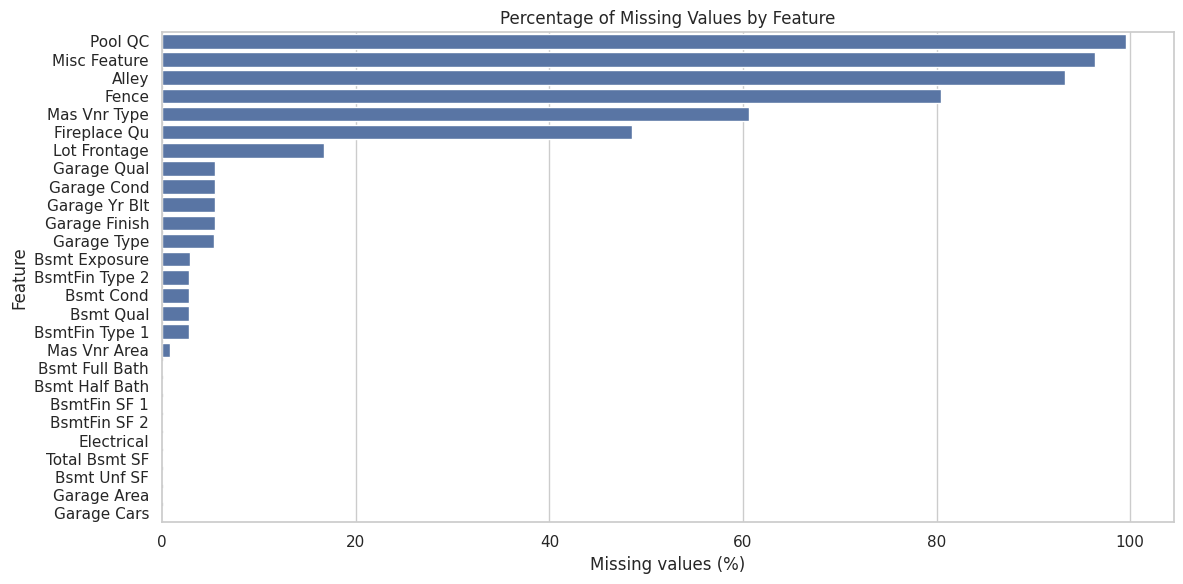

In [55]:
# Visualize columns with missing values
if not missing_summary.empty:
    plt.figure(figsize=(12, 6))
    sns.barplot(
        data=missing_summary.reset_index(),
        x="Missing_Percent",
        y="index"
    )
    plt.title("Percentage of Missing Values by Feature")
    plt.xlabel("Missing values (%)")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

<details>
<summary><strong>Observation – Missing values</strong></summary>

After running the table and chart, record:
- Which features have the highest missing percentages?
- Are missing values concentrated in a few columns?
- Are any target values (`SalePrice`) missing?

**Important:** In housing data, a missing value can sometimes mean that a feature is not present in the property (for example, no pool or no alley access). Check the dataset's data dictionary or feature meaning before deciding whether to fill it with a value, create a category such as `None`, or use another strategy.
</details>

# **Custom code**

**Features with NaN vlues**

In [57]:
feature_na= [feature for feature in df.columns  if df[feature].isnull().sum()>=1]
# df.columns are indexes which is a pandas object

'''
Why .sum() works for counts:

• df.isnull() turns your data into True (missing) and False (not missing).
• In Python, True equals 1 and False equals 0.
• By using .sum(), Pandas adds up all the 1s, giving you the exact total number of missing rows for each column.
'''

print(len(feature_na))  # 27 features have at least 1 NaN/Null value

feature_with_na = [feature for feature in df.columns  if df[feature].isnull().sum()>1]

print(len(feature_with_na)) # 20 features have more than one null value

# here we calculate the featue with how many null/NaN value percent using mean()

for feature in feature_with_na:
  print(f"feature :{feature} and null value percent:{np.round(df[feature].isnull().mean()*100,2)}%")




27
20
feature :Lot Frontage and null value percent:16.72%
feature :Alley and null value percent:93.24%
feature :Mas Vnr Type and null value percent:60.58%
feature :Mas Vnr Area and null value percent:0.78%
feature :Bsmt Qual and null value percent:2.73%
feature :Bsmt Cond and null value percent:2.73%
feature :Bsmt Exposure and null value percent:2.83%
feature :BsmtFin Type 1 and null value percent:2.73%
feature :BsmtFin Type 2 and null value percent:2.76%
feature :Bsmt Full Bath and null value percent:0.07%
feature :Bsmt Half Bath and null value percent:0.07%
feature :Fireplace Qu and null value percent:48.53%
feature :Garage Type and null value percent:5.36%
feature :Garage Yr Blt and null value percent:5.43%
feature :Garage Finish and null value percent:5.43%
feature :Garage Qual and null value percent:5.43%
feature :Garage Cond and null value percent:5.43%
feature :Pool QC and null value percent:99.56%
feature :Fence and null value percent:80.48%
feature :Misc Feature and null value

In [58]:
# count of missing values

missing_count = df.isnull().sum()
missing_count[missing_count>1]

,0
Lot Frontage,490
Alley,2732
Mas Vnr Type,1775
Mas Vnr Area,23
Bsmt Qual,80
Bsmt Cond,80
Bsmt Exposure,83
BsmtFin Type 1,80
BsmtFin Type 2,81
Bsmt Full Bath,2


**Data Visiualization Using Bar Plot**



```
Finding Relationship on SalePrice with these Feature having (null/NaN) vlaues
```



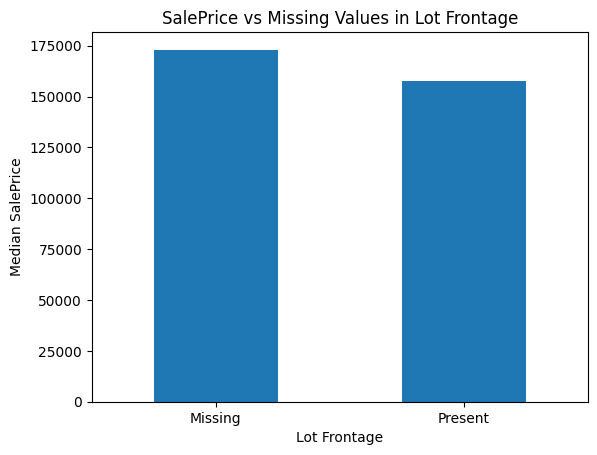

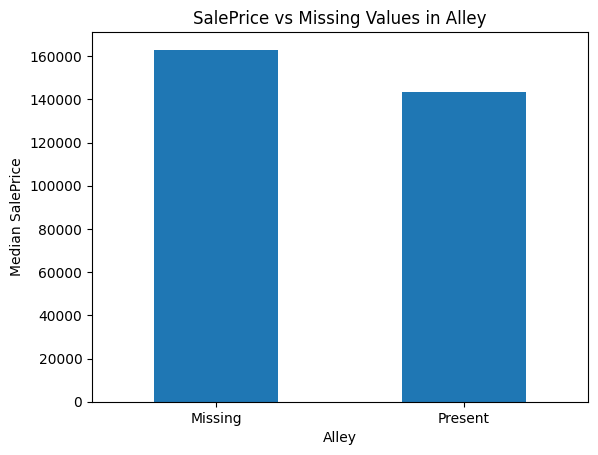

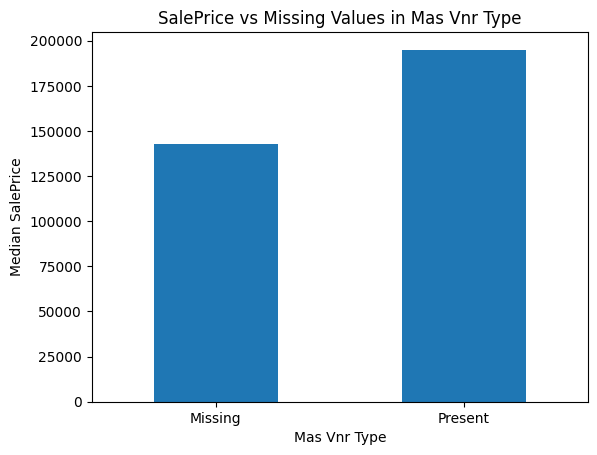

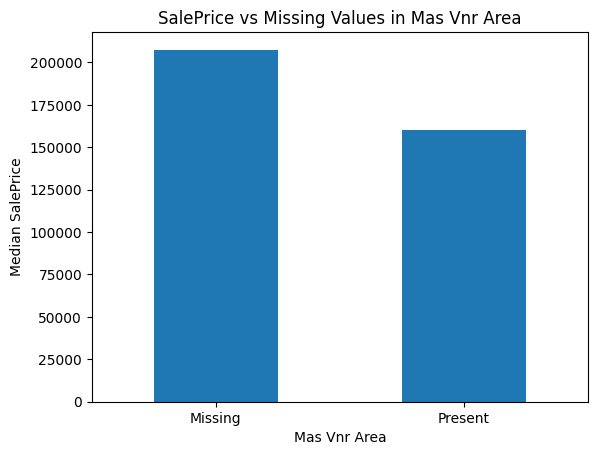

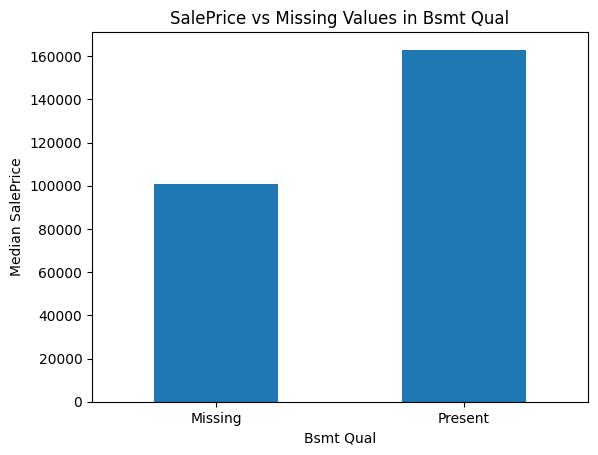

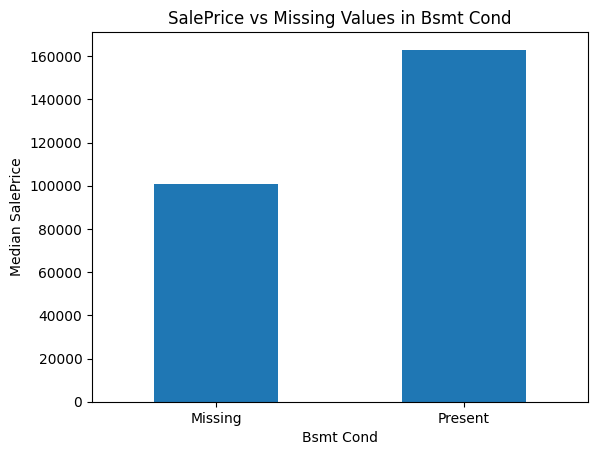

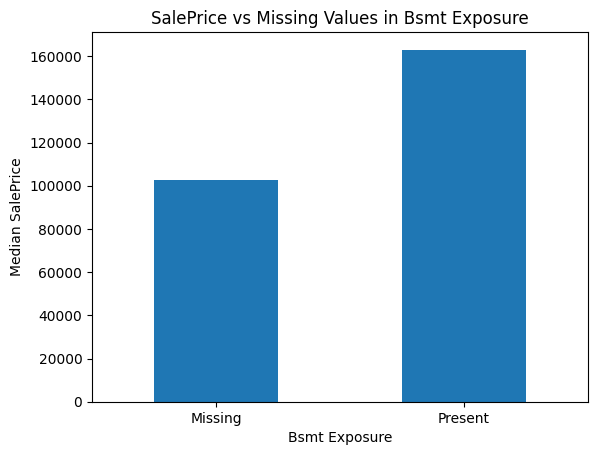

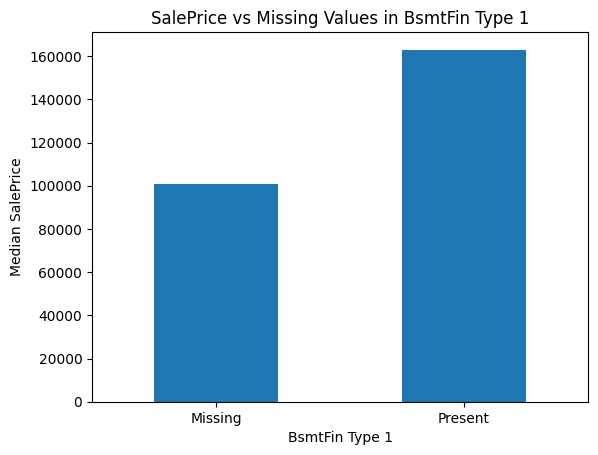

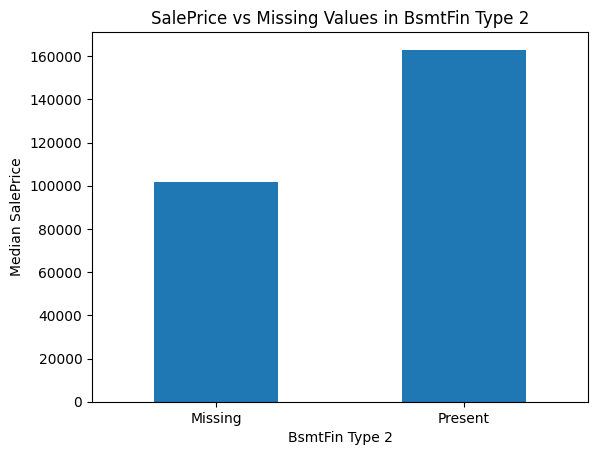

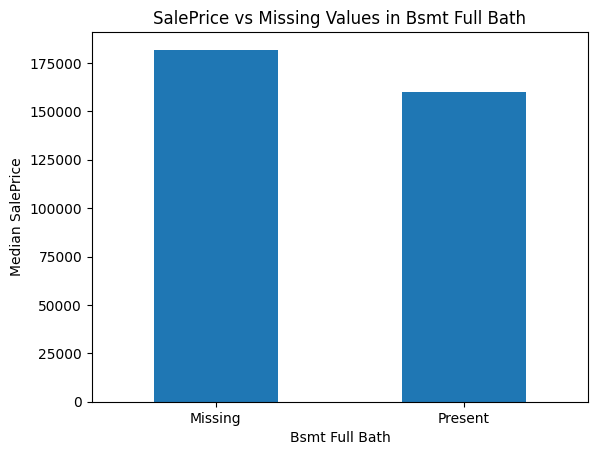

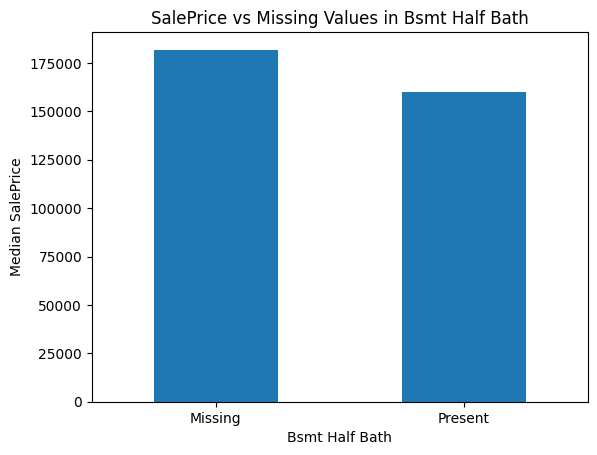

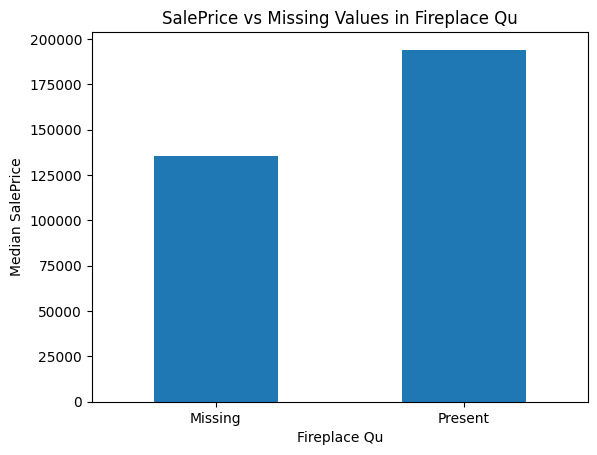

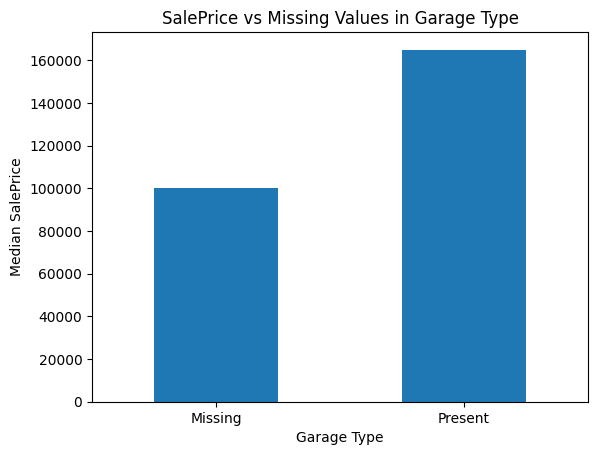

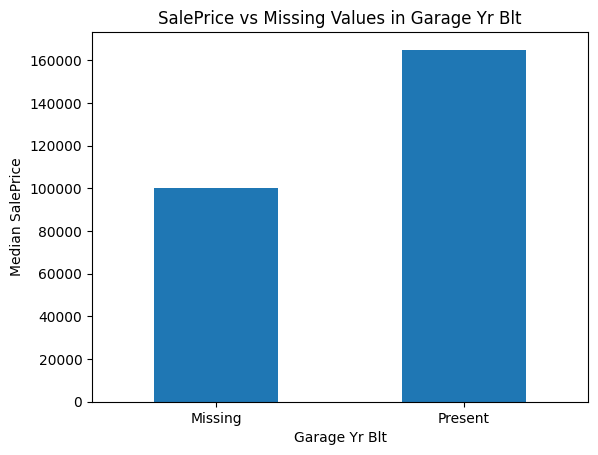

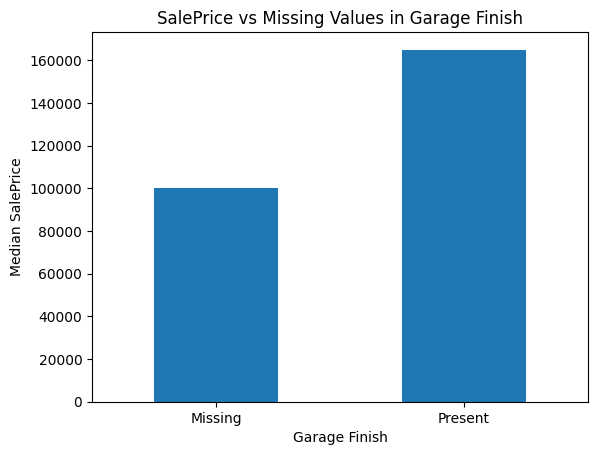

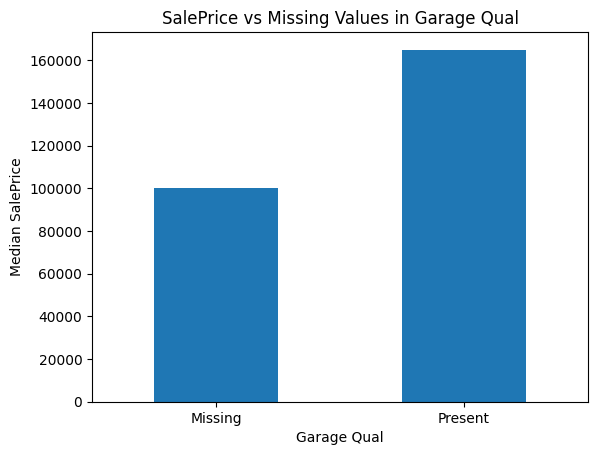

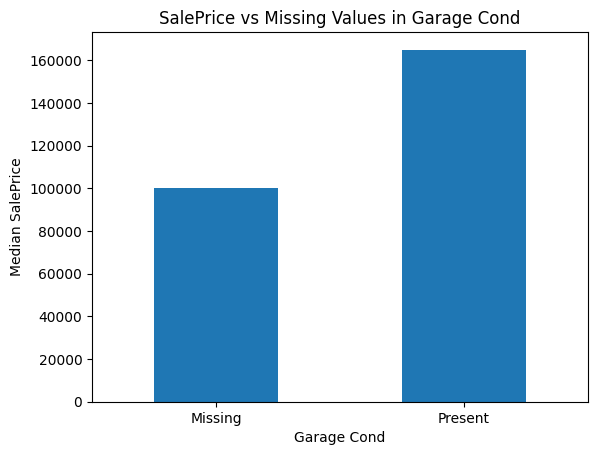

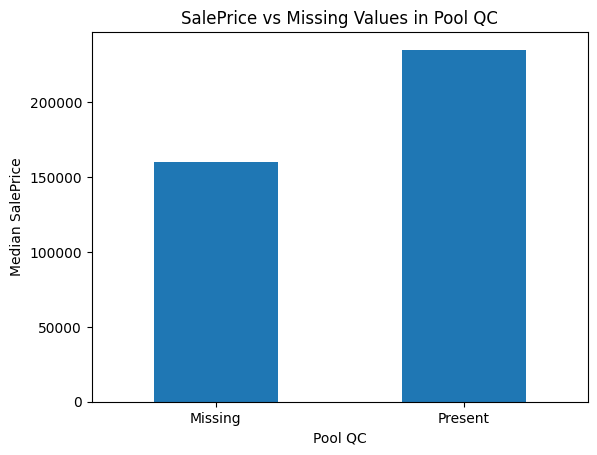

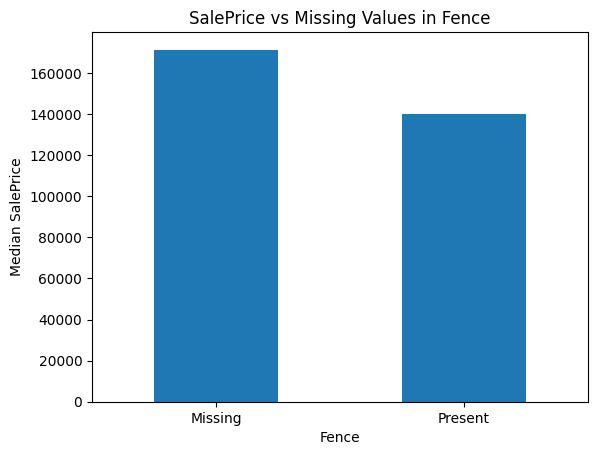

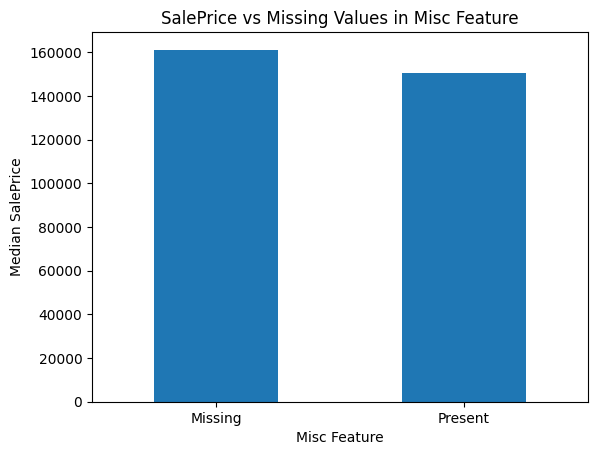

In [ ]:
for feature in feature_with_na:

    data = df.copy()

    # Identify missing and available values
    data[feature] = np.where(
        data[feature].isnull(),
        "Missing",
        "Present"
    )

    # Calculate median SalePrice
    result = data.groupby(feature)["SalePrice"].median()

    # Plot comparison
    result.plot.bar()

    plt.title(f"SalePrice vs Missing Values in {feature}")
    plt.xlabel(feature)
    plt.ylabel("Median SalePrice")
    plt.xticks(rotation=0)
    plt.show()

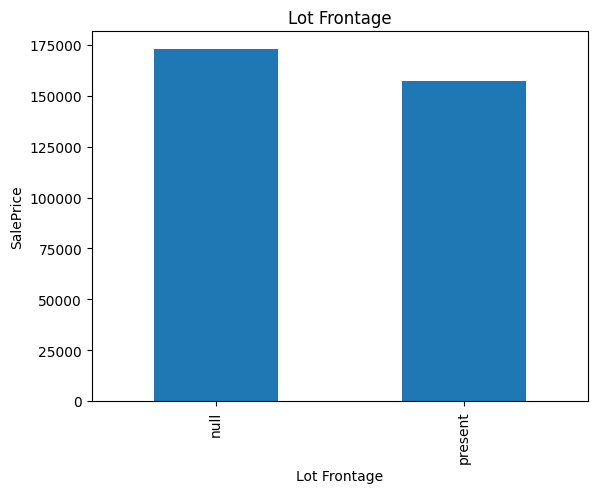

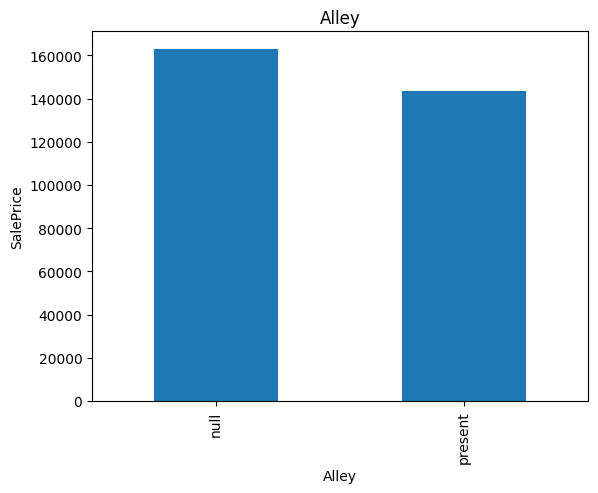

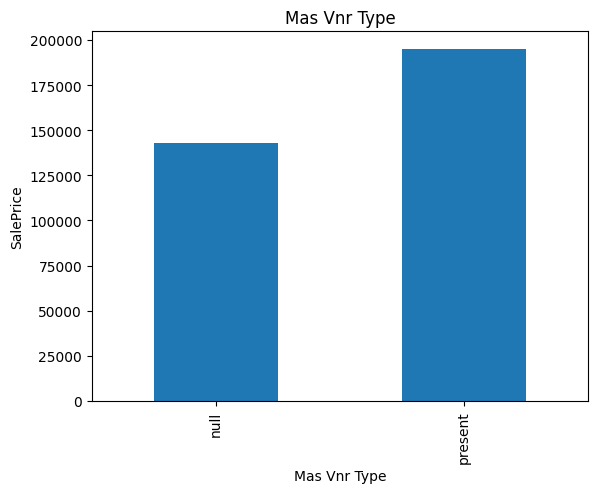

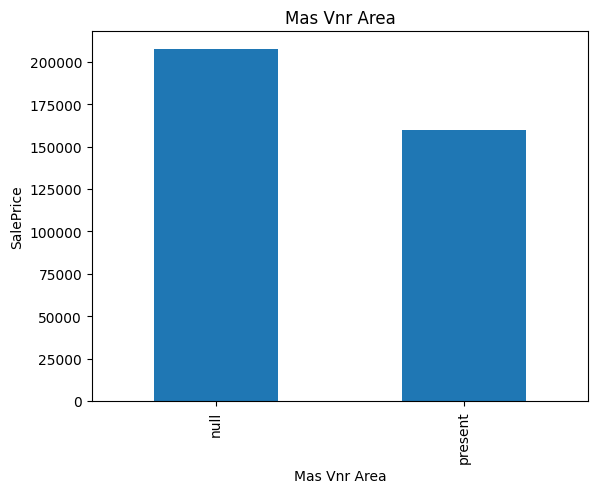

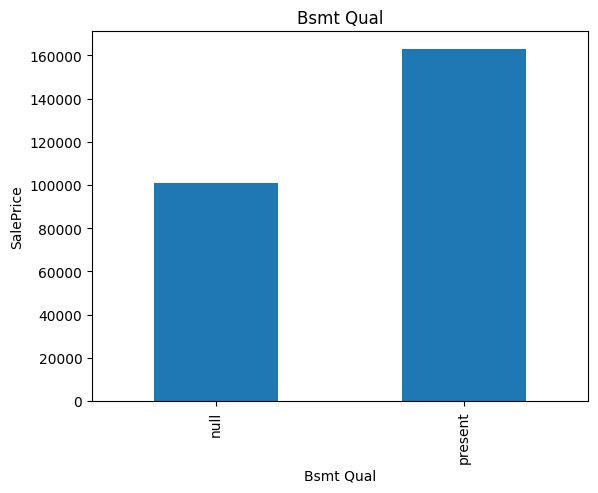

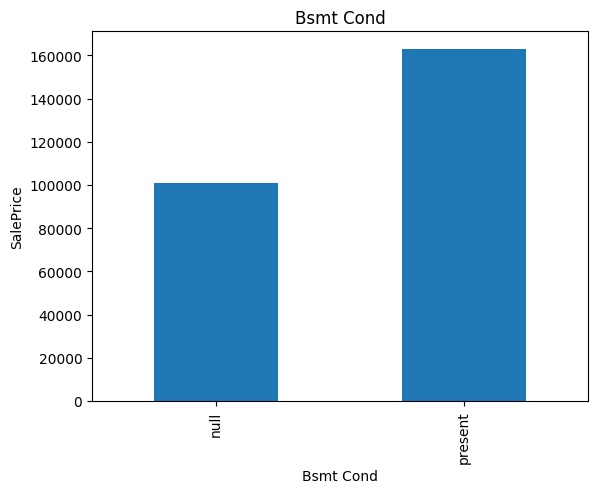

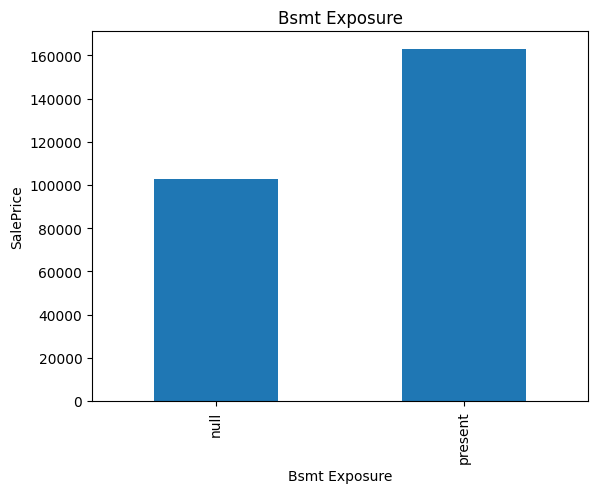

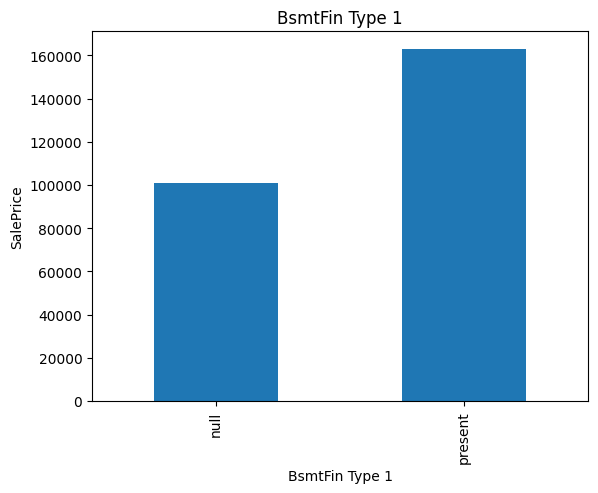

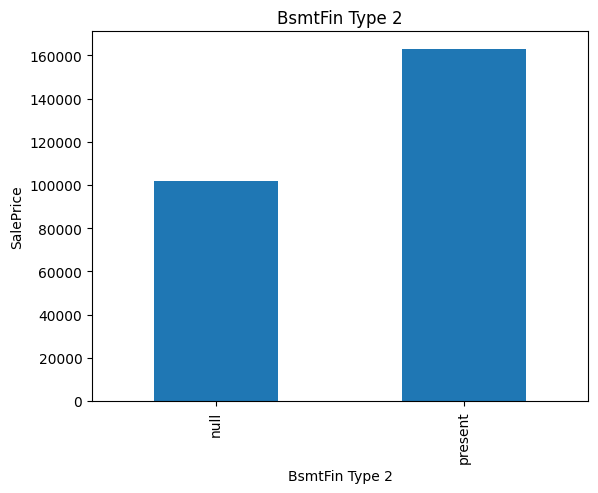

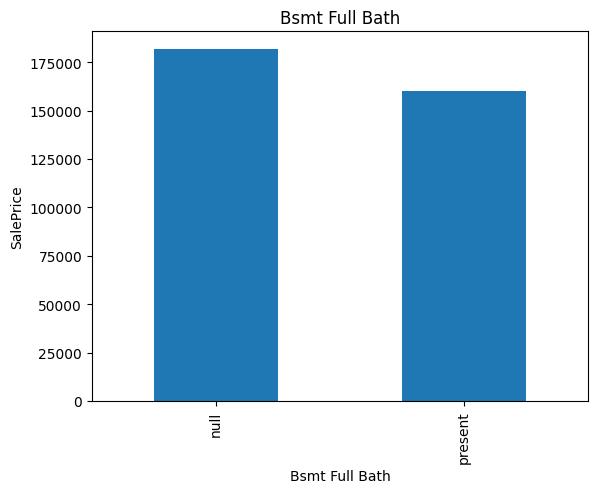

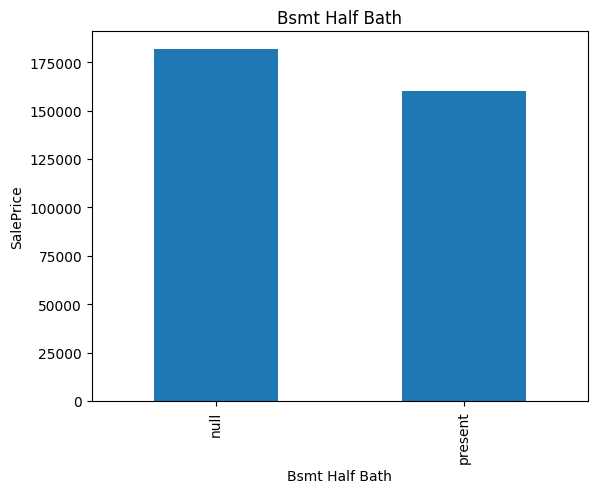

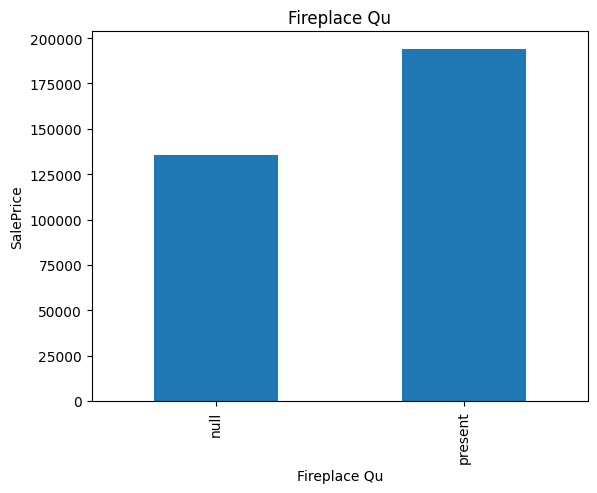

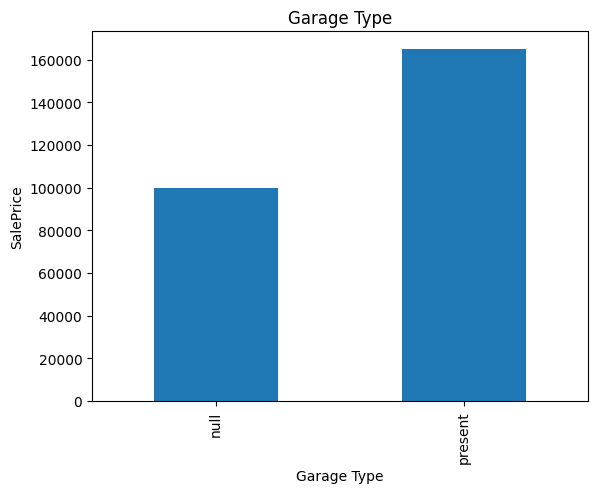

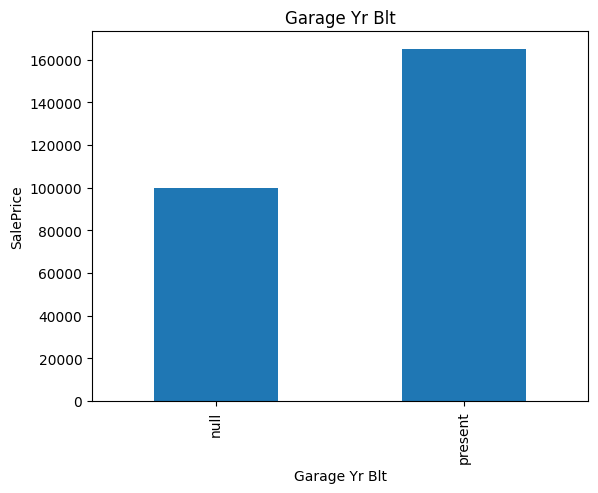

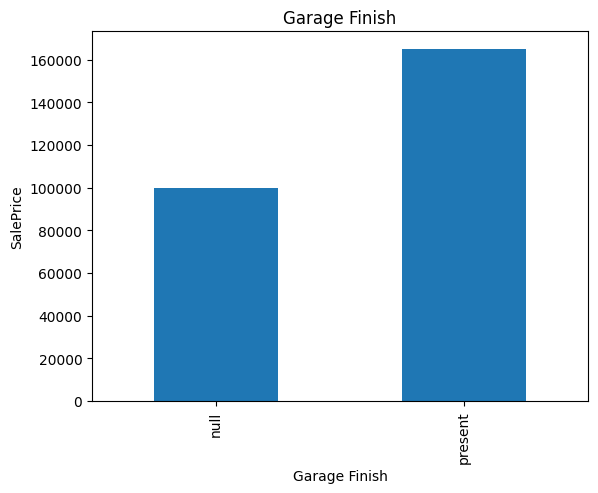

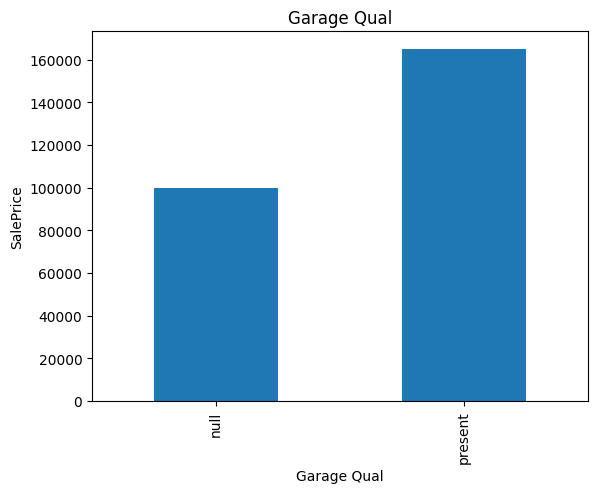

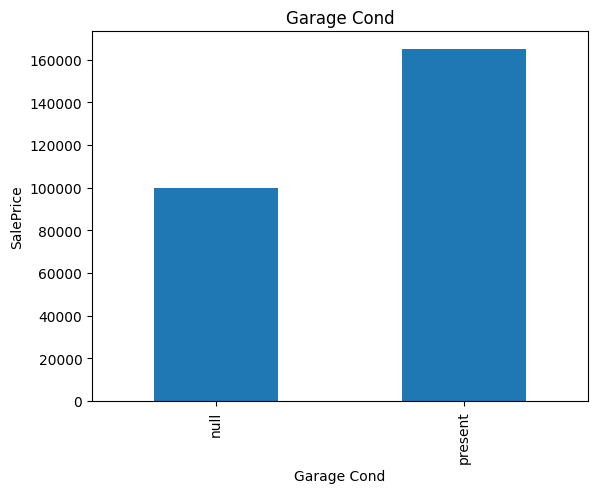

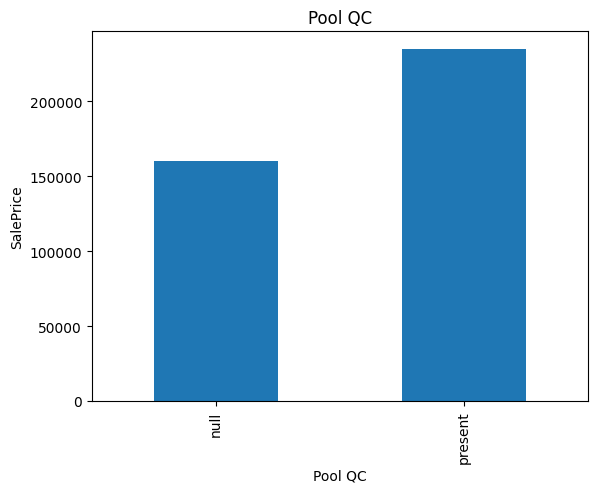

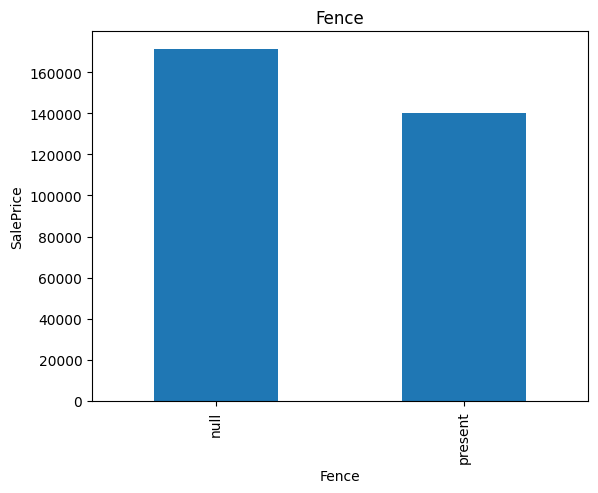

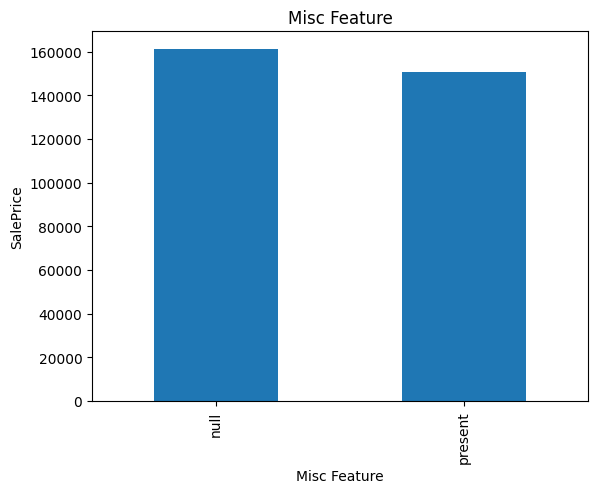

In [ ]:
for feature in feature_with_na:
    data = df.copy()

    # Replace the column's values with just two labels:
    #   "null"    -> the value was missing
    #   "present" -> the value existed (whatever it was)
    data[feature] = np.where(df[feature].isnull(), "null", "present")

    # Group houses by these two labels and find the median SalePrice of each group,
    # then plot it as a bar chart to compare the two
    data.groupby(feature)['SalePrice'].median().plot.bar()

    plt.title(feature)
    plt.xlabel(feature)
    plt.ylabel("SalePrice")
    plt.show()
#s.plot(kind='bar')  s is series # pandas
#s.plot.bar()         # pandas, identical result

## Median with `groupby()`

The **median** is the middle value after sorting numbers in ascending order.

When we use `groupby()` with `median()`, Pandas divides the data into groups and calculates the median separately for each group.

<details>
<summary><b>Example: Median SalePrice based on Alley</b></summary>

### Sample dataset

| House | Alley | SalePrice |
|---|---|---:|
| 1 | null | 120000 |
| 2 | present | 200000 |
| 3 | null | 140000 |
| 4 | null | 100000 |
| 5 | present | 250000 |
| 6 | present | 180000 |
| 7 | present | 300000 |

### Step 1: Group the data

```python
df.groupby('Alley')['SalePrice']
```

This divides the houses into two groups:

- **Null group:** 120000, 140000, 100000
- **Present group:** 200000, 250000, 180000, 300000

### Step 2: Calculate the median

**Null group:**

Sort the prices in ascending order:

```text
100000, 120000, 140000
```

The middle value is **120000**.

**Present group:**

Sort the prices in ascending order:

```text
180000, 200000, 250000, 300000
```

There are four values, so the median is the average of the two middle values:

\[
\text{Median}=\frac{200000+250000}{2}=225000
\]

The median is **225000**.

### Step 3: Complete Python code

```python
import pandas as pd

# Create sample data
df = pd.DataFrame({
    'Alley': [
        None, 'present', None, None,
        'present', 'present', 'present'
    ],
    'SalePrice': [
        120000, 200000, 140000, 100000,
        250000, 180000, 300000
    ]
})

# Calculate median SalePrice for each Alley group
result = df.groupby('Alley', dropna=False)['SalePrice'].median()

print(result)
```

Output:

```text
Alley
present    225000.0
NaN        120000.0
Name: SalePrice, dtype: float64
```

**Note:** `dropna=False` keeps the missing `Alley` values as a separate group. Without it, Pandas excludes missing group keys by default.

### Step 4: Plot the result

```python
result.plot.bar(
    title='Median SalePrice by Alley',
    xlabel='Alley',
    ylabel='Median SalePrice',
    rot=0
)
```

The bar chart displays one bar per group:

- Missing Alley: 120000
- Present Alley: 225000

**Key takeaway:** `groupby()` creates groups, `median()` calculates the middle value for each group, and `plot.bar()` visualizes the results.

</details>



### Observation

- The bar plots compare median SalePrice between houses with missing and available values.
- A noticeable difference between the two groups suggests that missingness may contain useful information.
- Features with similar median prices may have a weaker relationship with SalePrice through their missingness.

**Conclusion:** Missing values should be investigated feature by feature. We should not automatically remove or fill all missing values using the same strategy.

In [ ]:
# here PID and Order columns are not require for to predict SalePrices
# so we drop it

df = df.drop(['Order','PID'],axis=1)

## 6. Separate numerical and categorical features

#**Numerical Features**

In [ ]:
numerical_f = [feature  for feature in df.columns if df[feature].dtypes !='O']

df[numerical_f].head()

,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
0,20,141.0,31770,6,5,1960,1960,112.0,639.0,0.0,...,210,62,0,0,0,0,0,5,2010,215000
1,20,80.0,11622,5,6,1961,1961,0.0,468.0,144.0,...,140,0,0,0,120,0,0,6,2010,105000
2,20,81.0,14267,6,6,1958,1958,108.0,923.0,0.0,...,393,36,0,0,0,0,12500,6,2010,172000
3,20,93.0,11160,7,5,1968,1968,0.0,1065.0,0.0,...,0,0,0,0,0,0,0,4,2010,244000
4,60,74.0,13830,5,5,1997,1998,0.0,791.0,0.0,...,212,34,0,0,0,0,0,3,2010,189900


## 7. Analyze the target variable – SalePrice

In [59]:
# Check target column and missing target values
TARGET = "SalePrice"

if TARGET not in df.columns:
    raise KeyError("The dataset does not contain the SalePrice target column.")

print("Missing SalePrice values:", df[TARGET].isnull().sum())
display(df[TARGET].describe())

Missing SalePrice values: 0


,SalePrice
count,2930.000000
mean,180796.060068
std,79886.692357
min,12789.000000
25%,129500.000000
50%,160000.000000
75%,213500.000000
max,755000.000000


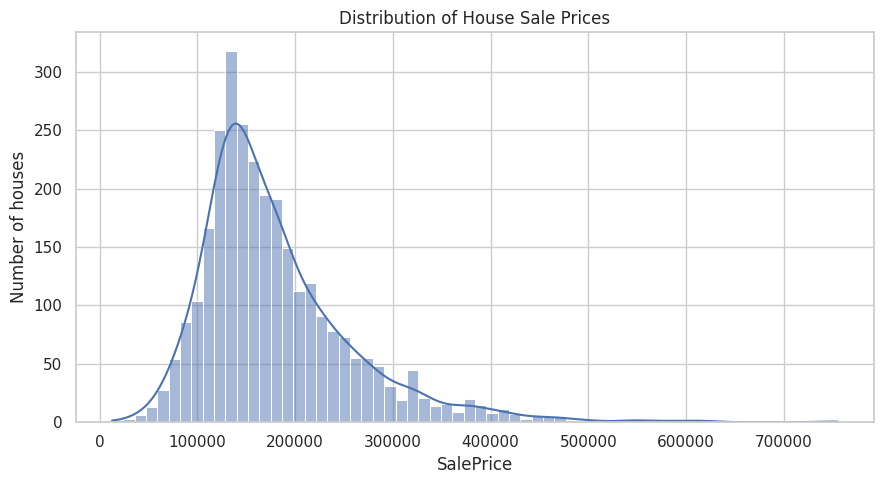

SalePrice skewness: 1.744


In [60]:
# Plot the distribution of house sale prices
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x=TARGET, kde=True)
plt.title("Distribution of House Sale Prices")
plt.xlabel("SalePrice")
plt.ylabel("Number of houses")
plt.tight_layout()
plt.show()

# Calculate skewness of SalePrice
print("SalePrice skewness:", round(df[TARGET].skew(), 3))

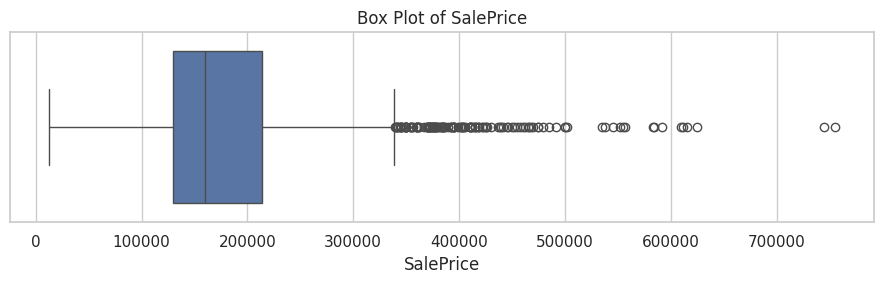

In [61]:
# Box plot helps identify possible extreme sale prices
plt.figure(figsize=(9, 3))
sns.boxplot(x=df[TARGET])
plt.title("Box Plot of SalePrice")
plt.xlabel("SalePrice")
plt.tight_layout()
plt.show()

<details>
<summary><strong>Observation – SalePrice distribution</strong></summary>

Check whether the distribution is symmetric or right-skewed. A long right tail means a smaller number of houses have much higher sale prices than most houses.

Record the skewness value and inspect the box plot. Extreme sale prices should be investigated rather than automatically deleted. A log transformation may be considered later if it is suitable for the modelling approach.
</details>

**Date-Time Features (temporal variables)**

In [ ]:
# list of year features

years_f = [feature for feature in df.columns if 'Year' in feature or 'Yr' in feature]

df[years_f].head()

,Year Built,Year Remod/Add,Garage Yr Blt,Yr Sold
0,1960,1960,1960.0,2010
1,1961,1961,1961.0,2010
2,1958,1958,1958.0,2010
3,1968,1968,1968.0,2010
4,1997,1998,1997.0,2010


**Data visulaization**



```
Relation of Tempo variables on SalePrice
```



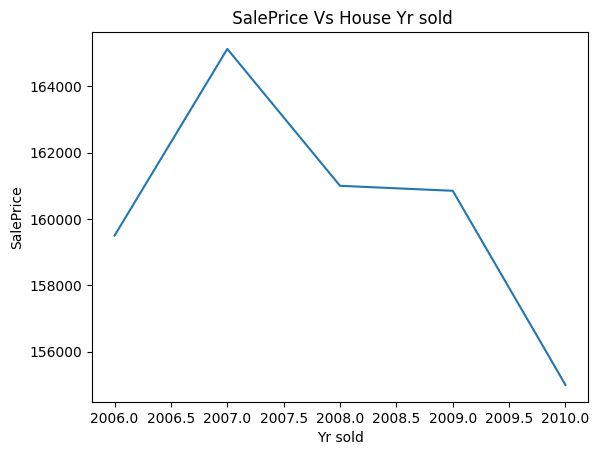

In [ ]:
# 1) year Sold 2D line graph using group by

df.groupby('Yr Sold')['SalePrice'].median().plot()
# by default X axis--> (' ') |  y axis--> [' ']
plt.title(" SalePrice Vs House Yr sold")
plt.xlabel('Yr sold')
plt.ylabel('SalePrice')
plt.show()



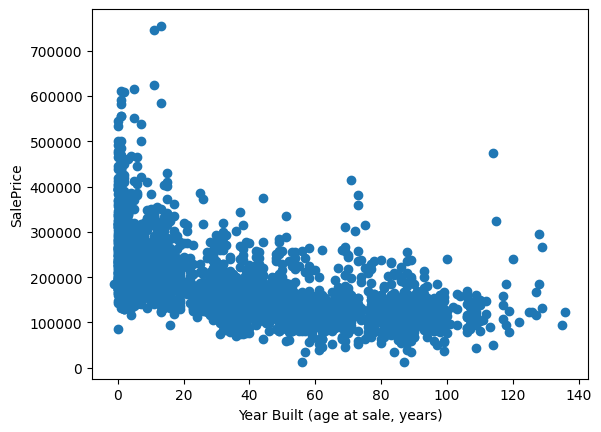

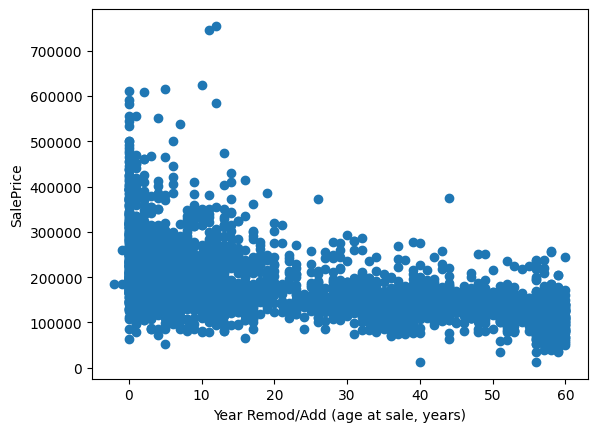

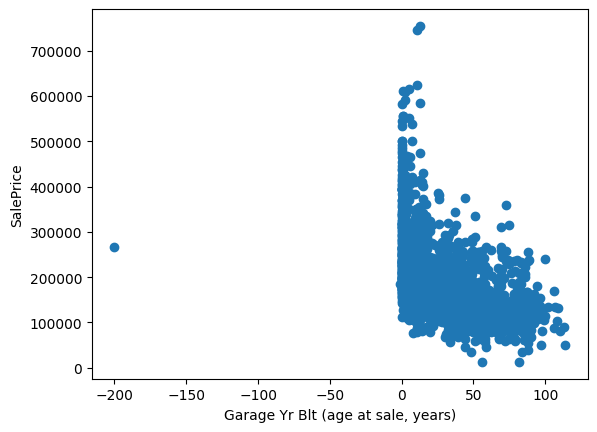

In [ ]:
# depending on year difference from the feature to Yr Sold how many years taken

for feature in years_f:
  if feature != 'Yr Sold':

      data = df.copy()
      data[feature] = data['Yr Sold']-data[feature]

      plt.scatter(data[feature],data['SalePrice'])
      plt.xlabel(feature+" (age at sale, years)")
      plt.ylabel("SalePrice")
      plt.show()

**Numerical Features (Valrables)** are two types
`1) Continuous`
`2) Discrete`

In [ ]:
# discrete features

discrete_f = [feature for feature in numerical_f
              if df[feature].nunique() < 25 and feature not in years_f + ['ID']]
# This marks a column discrete only if it has few unique values and all of them are whole numbers.
# means these columns have less than 25 unique vlaues and these same values repeated


df[discrete_f]


,MS SubClass,Overall Qual,Overall Cond,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,TotRms AbvGrd,Fireplaces,Garage Cars,Pool Area,Mo Sold
0,20,6,5,1.0,0.0,1,0,3,1,7,2,2.0,0,5
1,20,5,6,0.0,0.0,1,0,2,1,5,0,1.0,0,6
2,20,6,6,0.0,0.0,1,1,3,1,6,0,1.0,0,6
3,20,7,5,1.0,0.0,2,1,3,1,8,2,2.0,0,4
4,60,5,5,0.0,0.0,2,1,3,1,6,1,2.0,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,80,6,6,1.0,0.0,1,0,3,1,6,0,2.0,0,3
2926,20,5,5,1.0,0.0,1,0,2,1,5,0,2.0,0,6
2927,85,5,5,0.0,1.0,1,0,3,1,6,0,0.0,0,7
2928,20,5,5,1.0,0.0,1,0,2,1,6,1,2.0,0,4


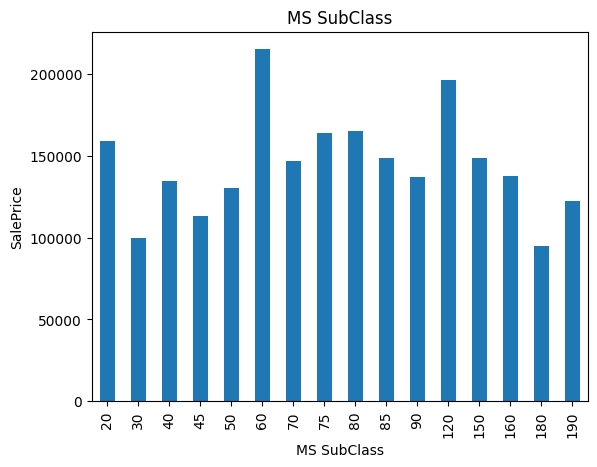

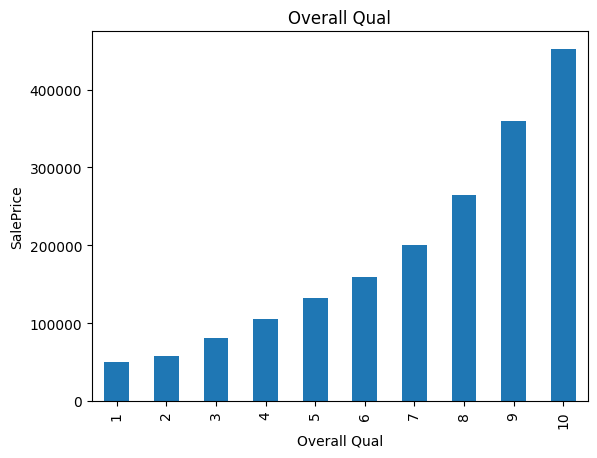

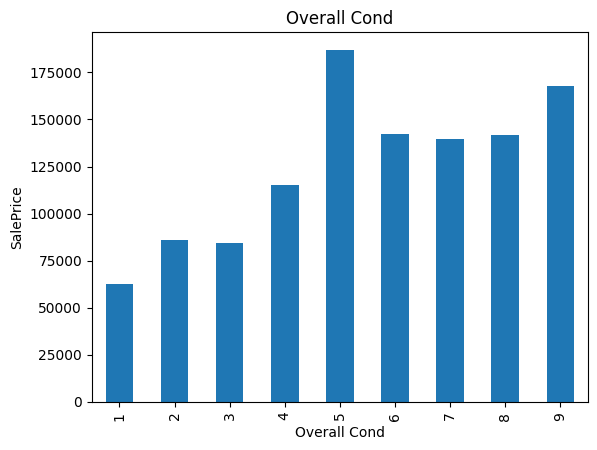

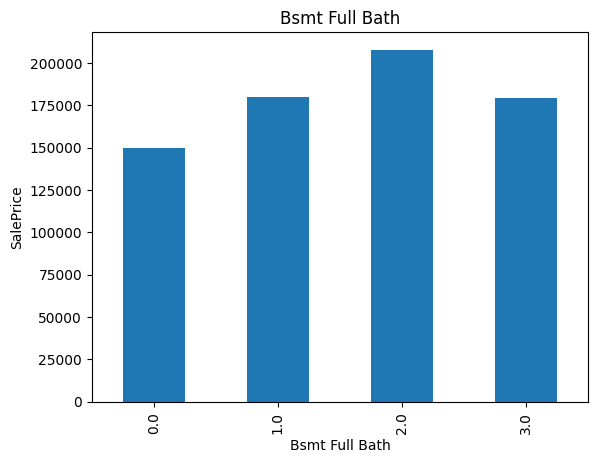

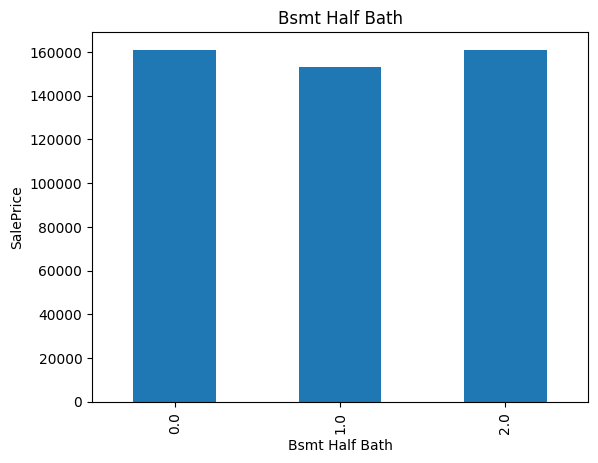

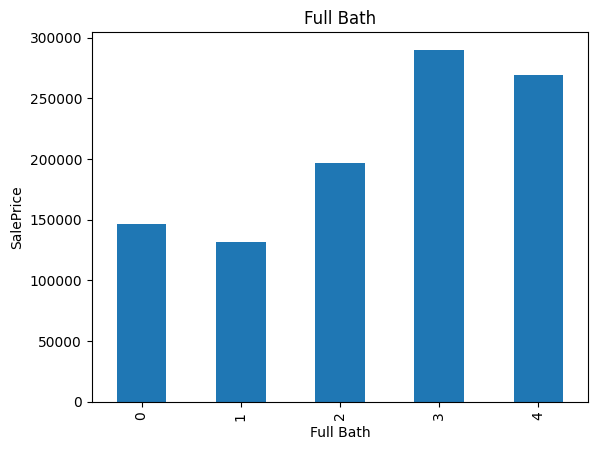

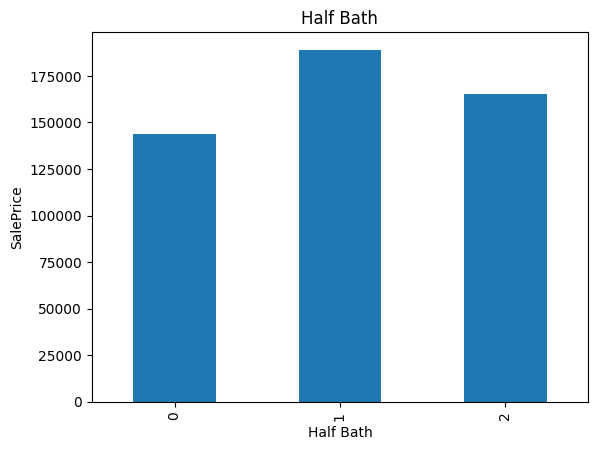

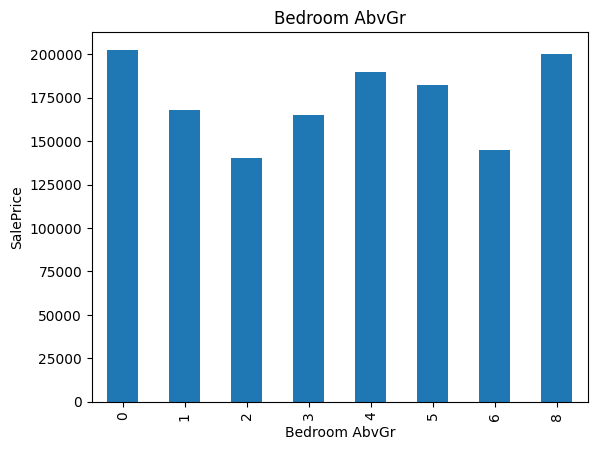

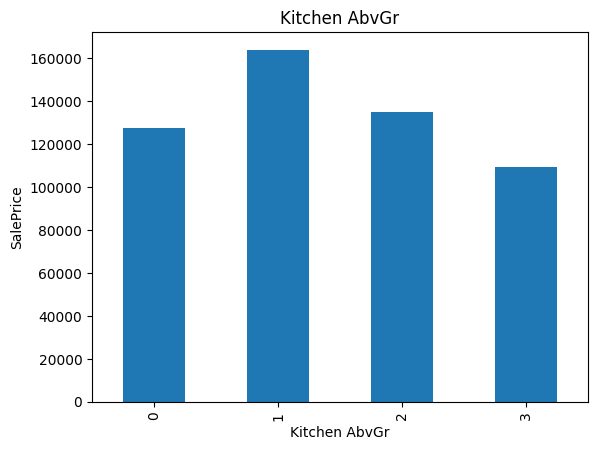

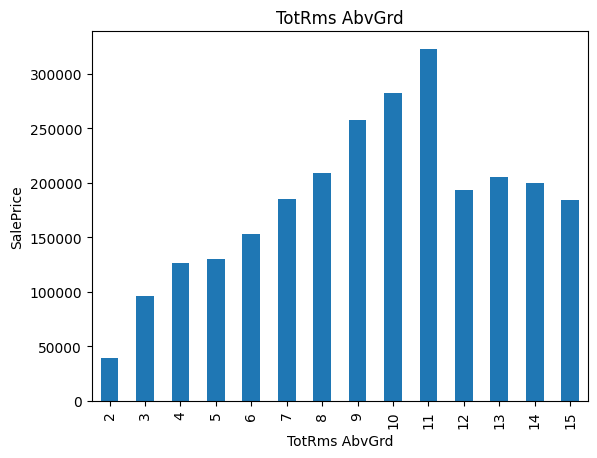

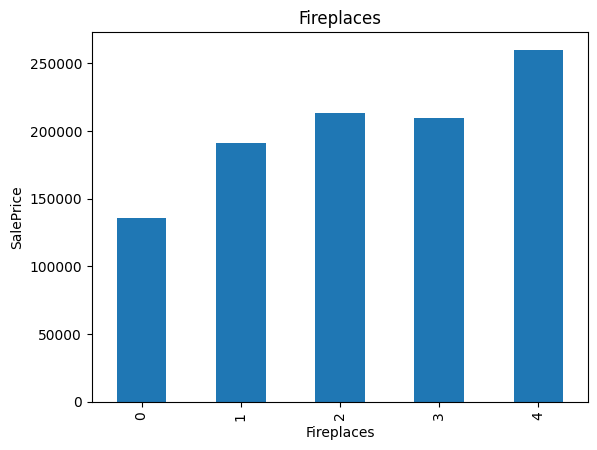

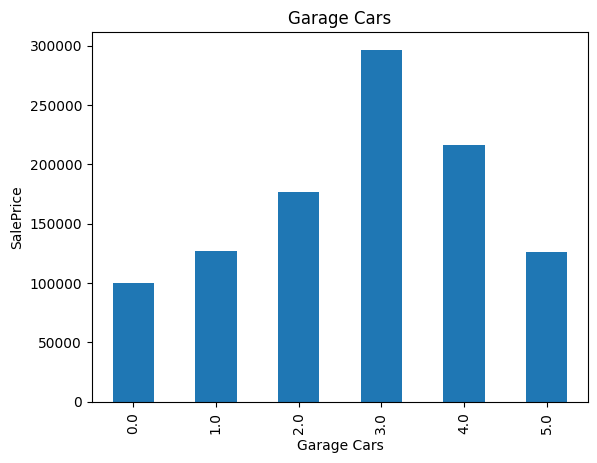

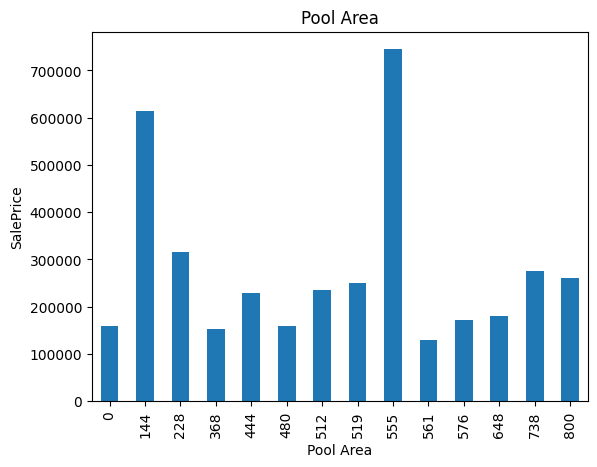

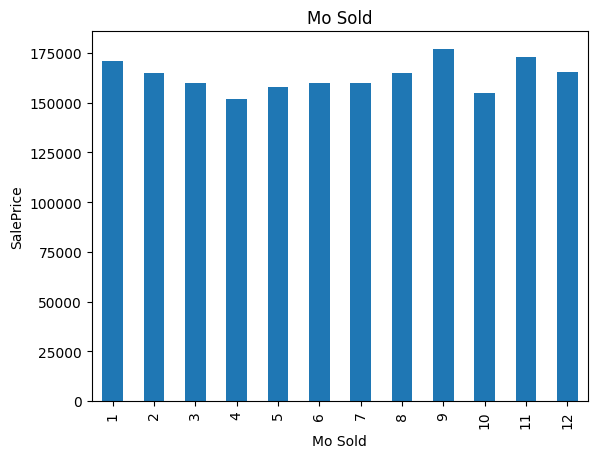

In [ ]:
# finding relationship between these discrete variables on SalePrice

for feature in discrete_f:
  data = df.copy()

  # use groupby and apply agg fun median and then plot graph

  data.groupby(feature)['SalePrice'].median().plot.bar()
  plt.title(feature)
  plt.xlabel(feature)
  plt.ylabel('SalePrice')
  plt.show()

In [ ]:
# contineous variables

contineous_f = [feature for feature in numerical_f if feature not in discrete_f+years_f+['Id']]

df[contineous_f].head()

,Lot Frontage,Lot Area,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Garage Area,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Misc Val,SalePrice
0,141.0,31770,112.0,639.0,0.0,441.0,1080.0,1656,0,0,1656,528.0,210,62,0,0,0,0,215000
1,80.0,11622,0.0,468.0,144.0,270.0,882.0,896,0,0,896,730.0,140,0,0,0,120,0,105000
2,81.0,14267,108.0,923.0,0.0,406.0,1329.0,1329,0,0,1329,312.0,393,36,0,0,0,12500,172000
3,93.0,11160,0.0,1065.0,0.0,1045.0,2110.0,2110,0,0,2110,522.0,0,0,0,0,0,0,244000
4,74.0,13830,0.0,791.0,0.0,137.0,928.0,928,701,0,1629,482.0,212,34,0,0,0,0,189900


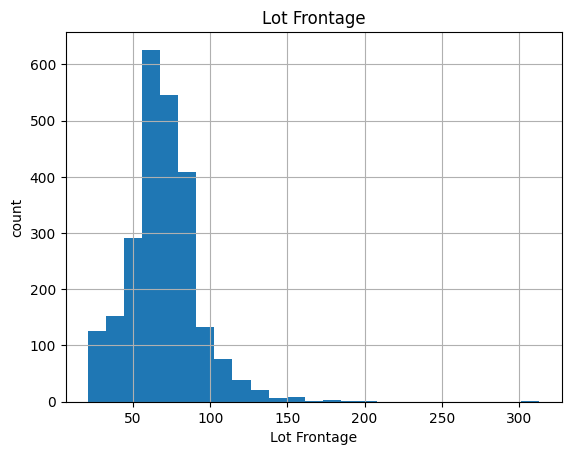

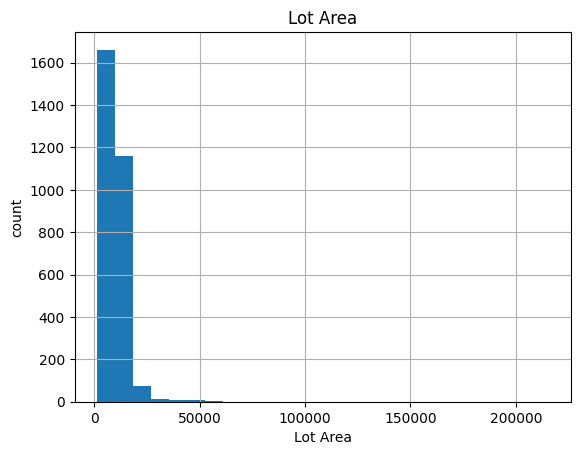

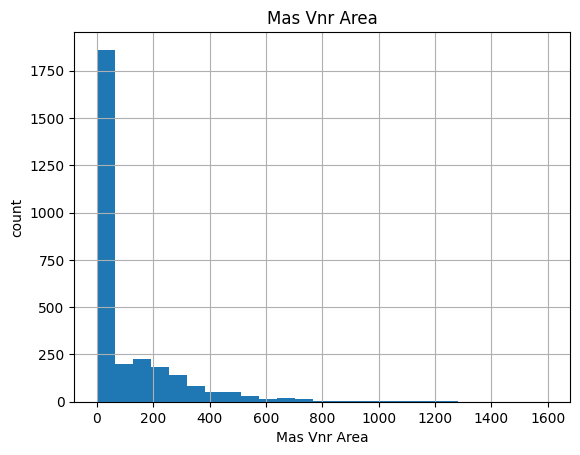

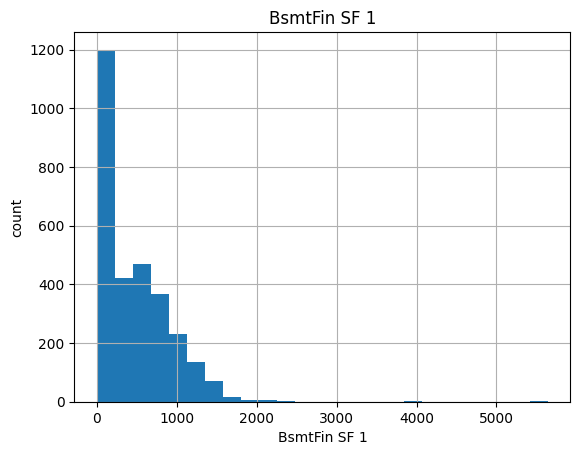

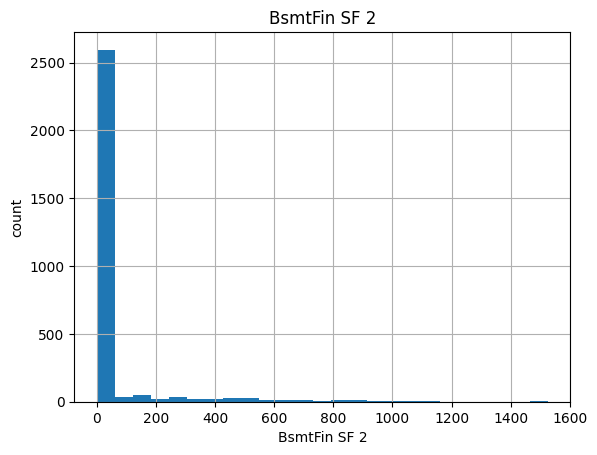

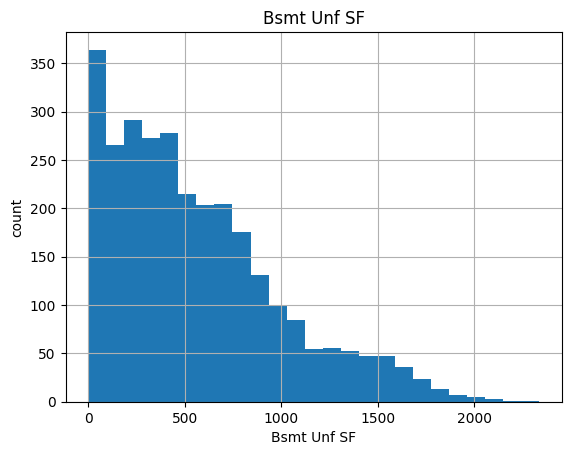

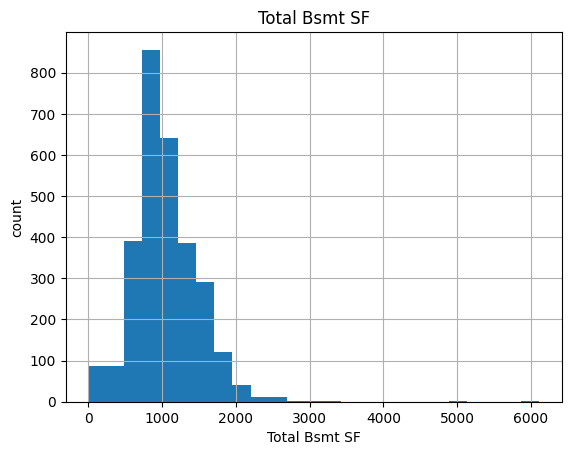

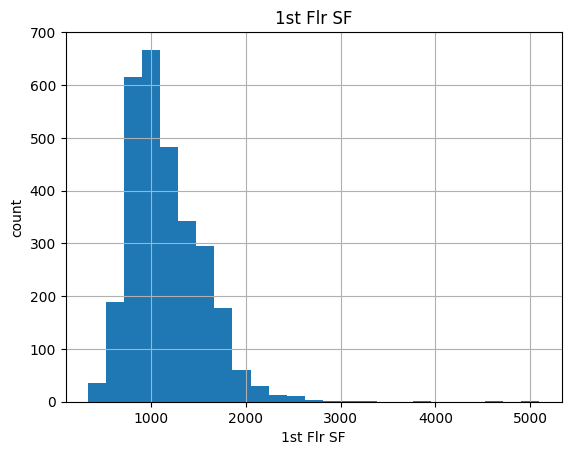

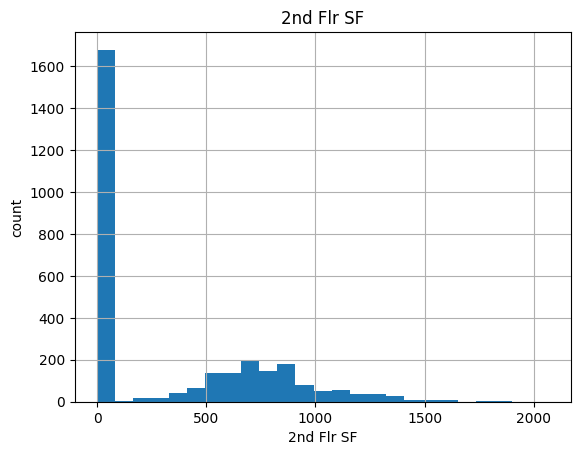

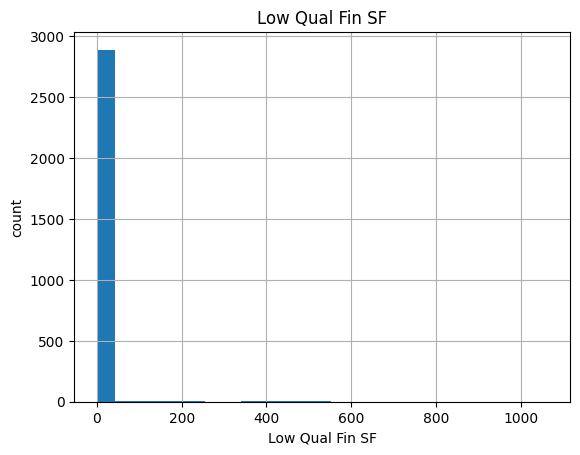

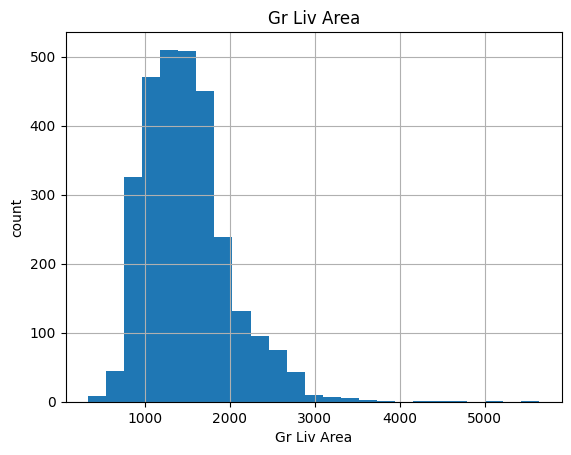

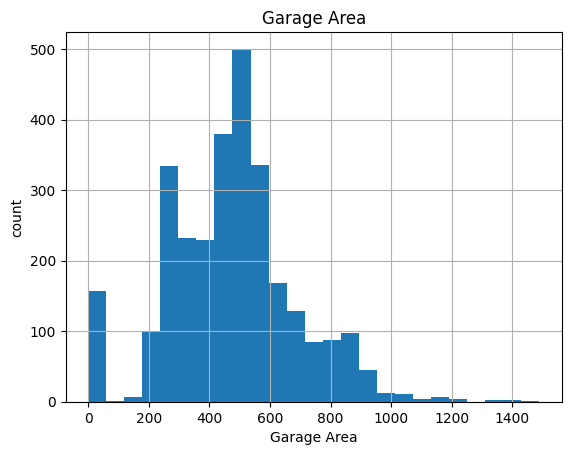

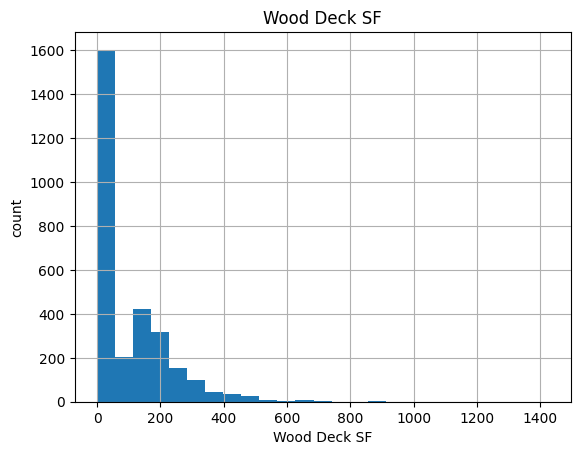

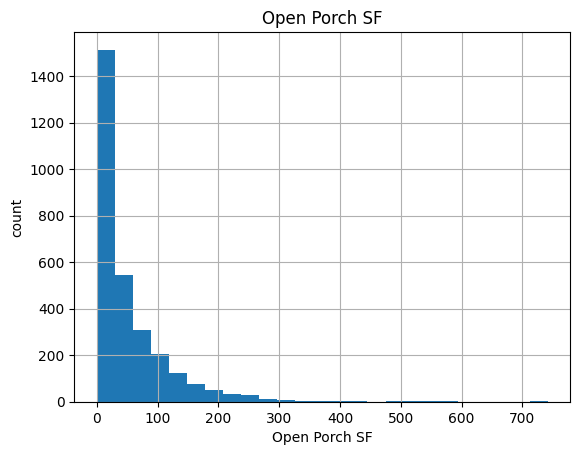

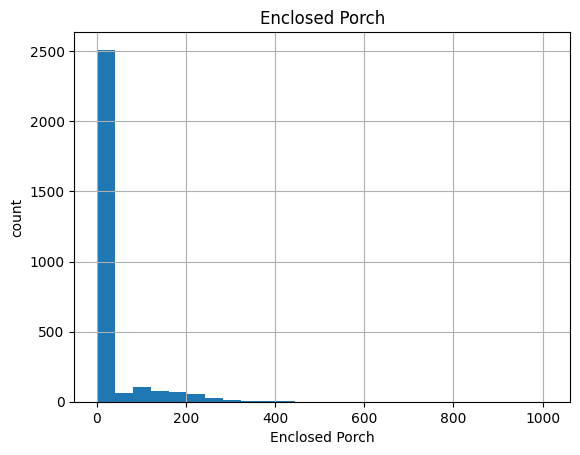

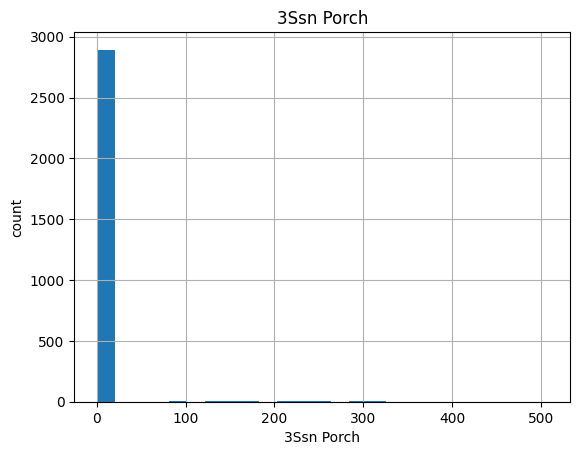

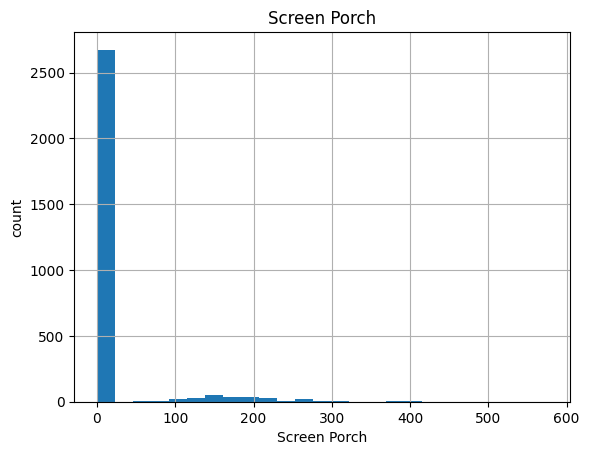

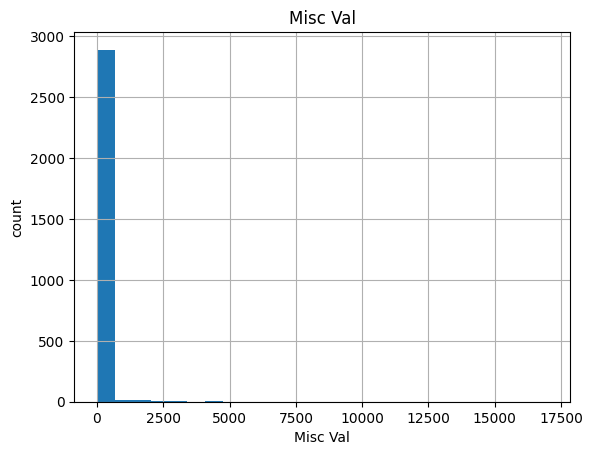

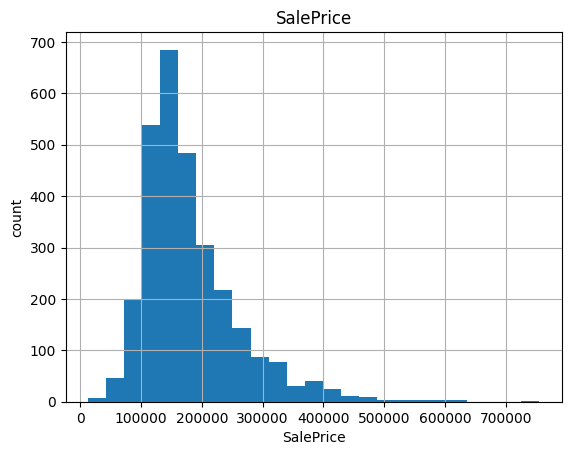

In [ ]:
# Distribution of each continuous feature (histogram) to check skewness and outliers
for feature in contineous_f:
    df[feature].hist(bins=25)
    plt.xlabel(feature)
    plt.ylabel("count")
    plt.title(feature)
    plt.show()



```
How to read the histogram
Shape              	                 Meaning
Bell shape,symmetric	           Roughly normal, usually fine as is

Long tail to the right  	       Right-skewed, often fixed with a log transform

Isolated bars far from the rest  	Outliers
```



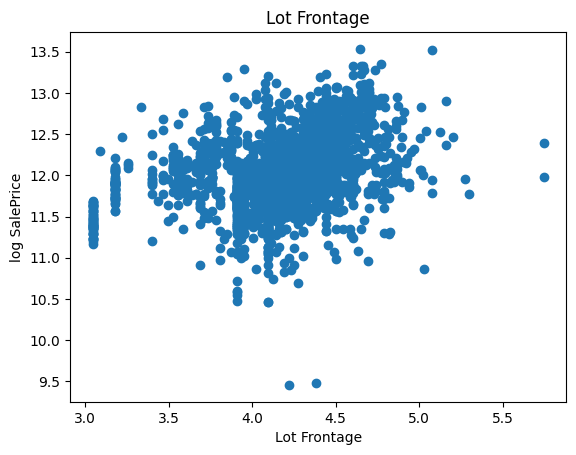

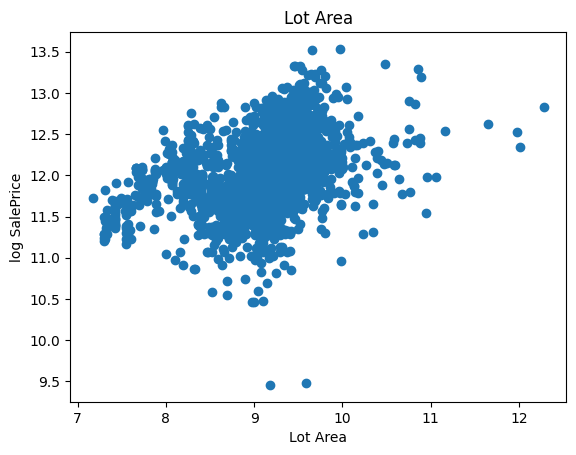

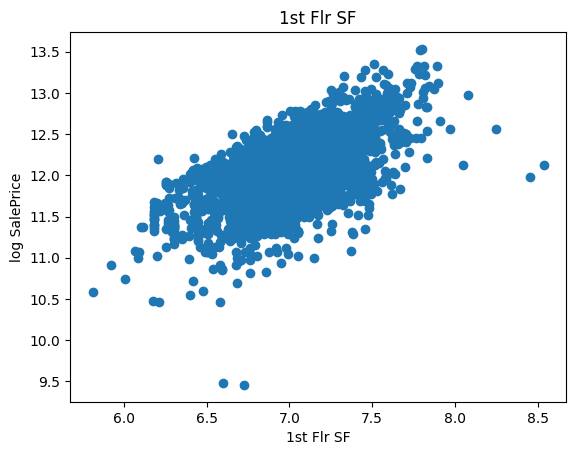

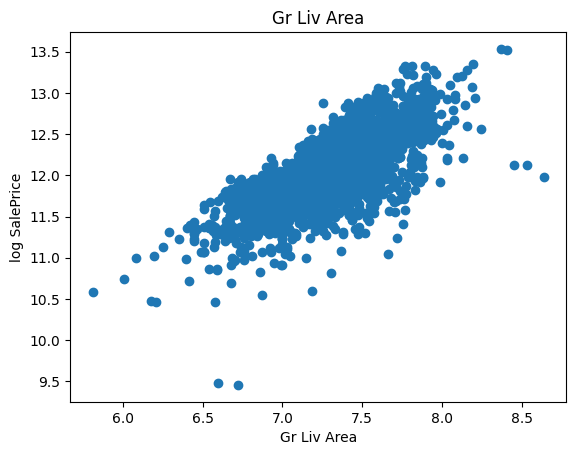

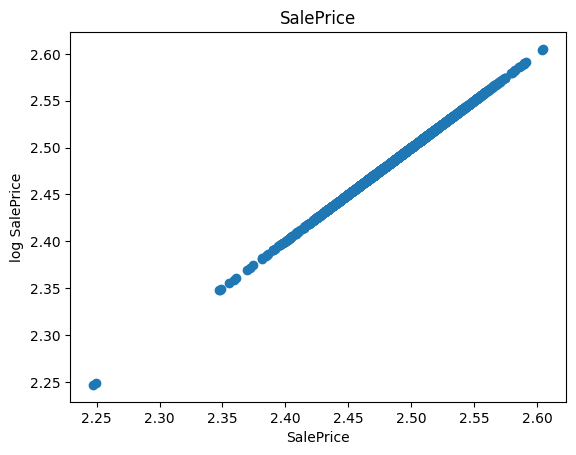

In [ ]:
# applying log noramal distribution
for feature in contineous_f:
    data = df.copy()
    if 0 in data[feature].unique():   # log(0) is undefined, so skip
        continue

    data[feature] = np.log(data[feature])
    data['SalePrice'] = np.log(data['SalePrice'])

    plt.scatter(data[feature], data['SalePrice'])
    plt.xlabel(feature)
    plt.ylabel("log SalePrice")
    plt.title(feature)
    plt.show()

In [ ]:
df['Lot Area'].skew()  # positve right skewed
# negative number left skewed
# 0 symmetric

np.float64(12.820898171092681)

# **Outliers**





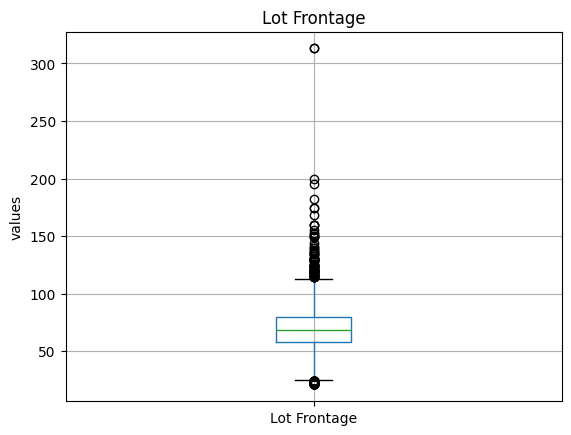

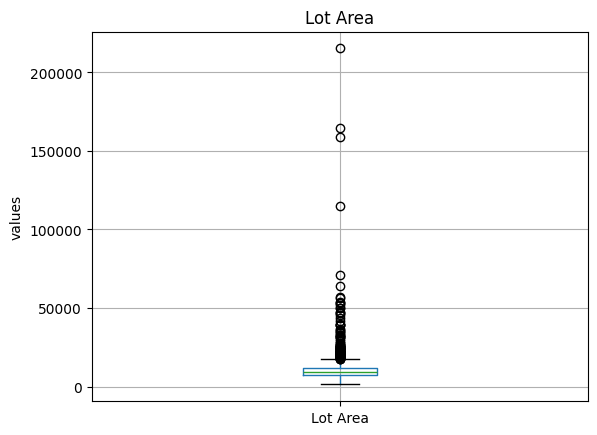

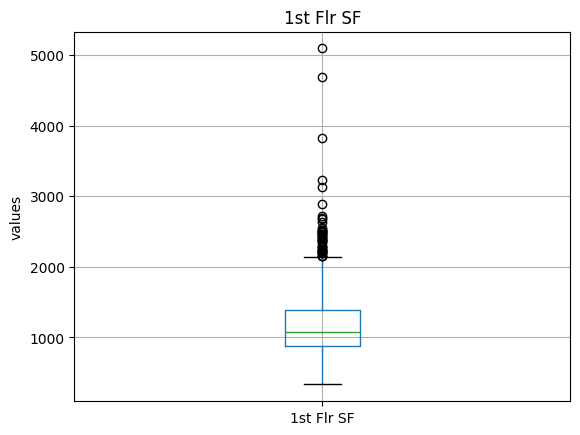

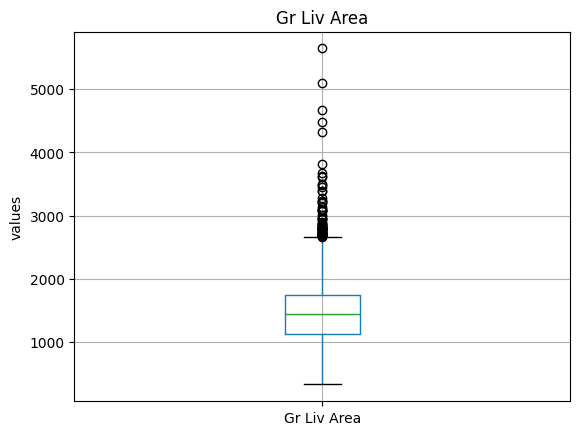

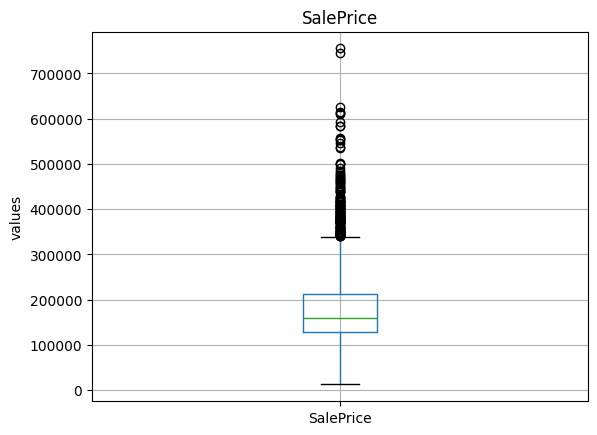

In [ ]:
# Box Plot
# Box plot only works on Contineous data does not work on Categorical data

for feature in contineous_f:
  data = df.copy()

  if 0 in df[feature].unique():
    pass
  else:
    data.boxplot(column=feature)
    plt.title(feature)
    plt.ylabel("values")
    plt.show()

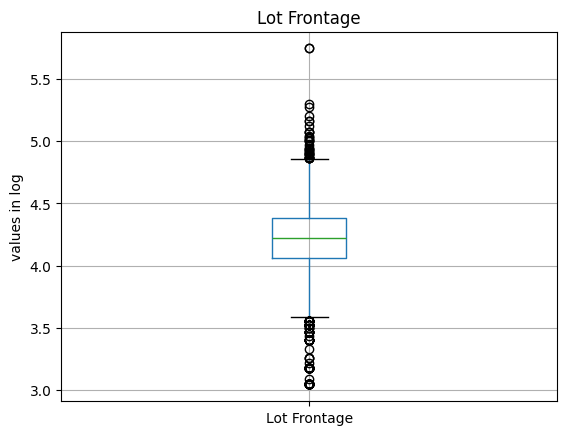

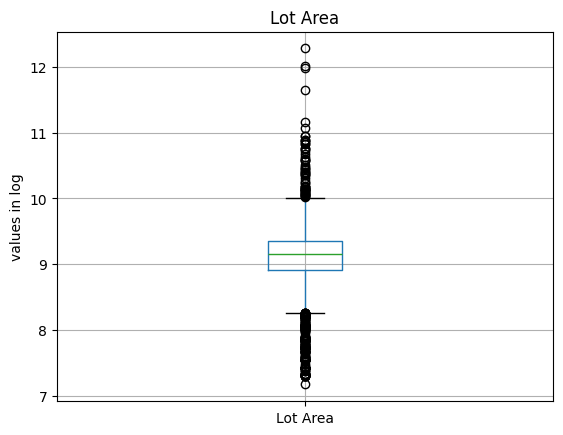

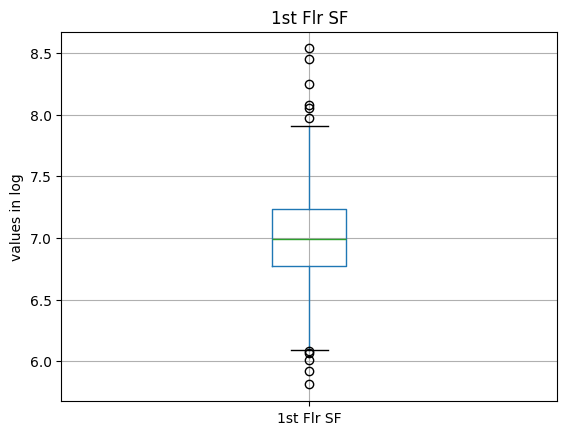

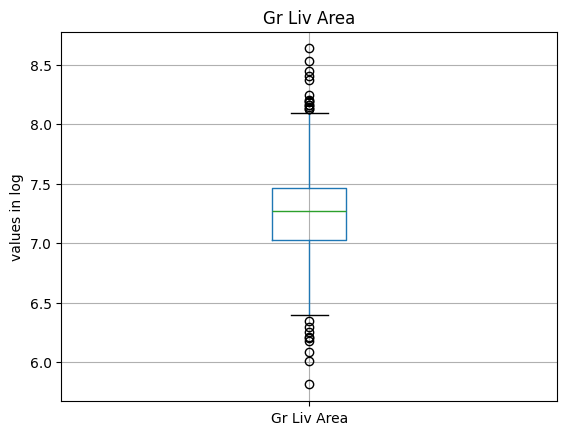

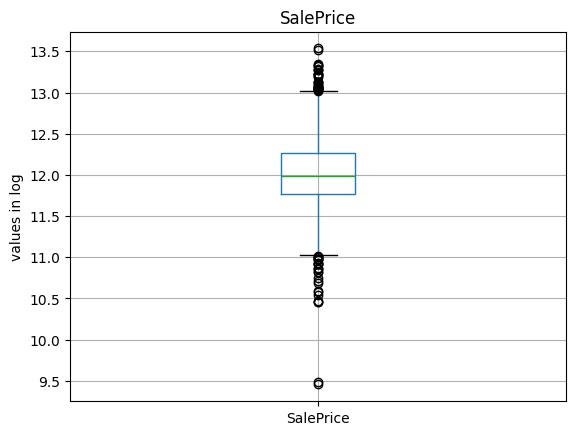

In [ ]:
for feature in contineous_f:
    data = df.copy()
    if 0 in data[feature].unique():
        continue
    data[feature] = np.log(data[feature])
    data.boxplot(column=feature)
    plt.title(feature)
    plt.ylabel("values in log")
    plt.show()



```
Observation lot of Outliers in each feature
```



**Categorical Features**

In [ ]:
categorical_f = [feature for feature in df.columns if df[feature].dtypes == 'O']

df[categorical_f].head()

,MS Zoning,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,...,Garage Type,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Pool QC,Fence,Misc Feature,Sale Type,Sale Condition
0,RL,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,...,Attchd,Fin,TA,TA,P,NaN,NaN,NaN,WD,Normal
1,RH,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,...,Attchd,Unf,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal
2,RL,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,...,Attchd,Unf,TA,TA,Y,NaN,NaN,Gar2,WD,Normal
3,RL,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,...,Attchd,Fin,TA,TA,Y,NaN,NaN,NaN,WD,Normal
4,RL,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,...,Attchd,Fin,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal





```
Cardinality
```



In [ ]:
# for finding how many unique categories are there in this columns
# cardinality of categorical columns

for feature in categorical_f:
    print(f"Feature: {feature} has {df[feature].nunique()} categories")

Feature: MS Zoning has 7 categories
Feature: Street has 2 categories
Feature: Alley has 2 categories
Feature: Lot Shape has 4 categories
Feature: Land Contour has 4 categories
Feature: Utilities has 3 categories
Feature: Lot Config has 5 categories
Feature: Land Slope has 3 categories
Feature: Neighborhood has 28 categories
Feature: Condition 1 has 9 categories
Feature: Condition 2 has 8 categories
Feature: Bldg Type has 5 categories
Feature: House Style has 8 categories
Feature: Roof Style has 6 categories
Feature: Roof Matl has 8 categories
Feature: Exterior 1st has 16 categories
Feature: Exterior 2nd has 17 categories
Feature: Mas Vnr Type has 4 categories
Feature: Exter Qual has 4 categories
Feature: Exter Cond has 5 categories
Feature: Foundation has 6 categories
Feature: Bsmt Qual has 5 categories
Feature: Bsmt Cond has 5 categories
Feature: Bsmt Exposure has 4 categories
Feature: BsmtFin Type 1 has 6 categories
Feature: BsmtFin Type 2 has 6 categories
Feature: Heating has 6 cate

In [ ]:
# Feature: Exterior 1st has 16 categories
# Feature: Exterior 2nd has 17 categories
# Feature: Sale Type has 10 categories
# Feature: Neighborhood has 28 categories

# max categories features

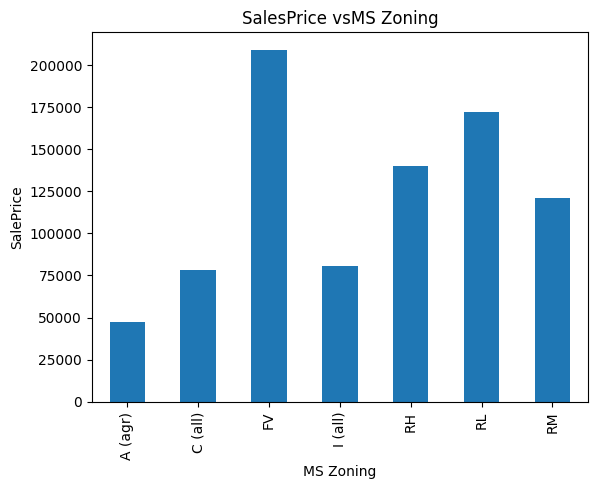

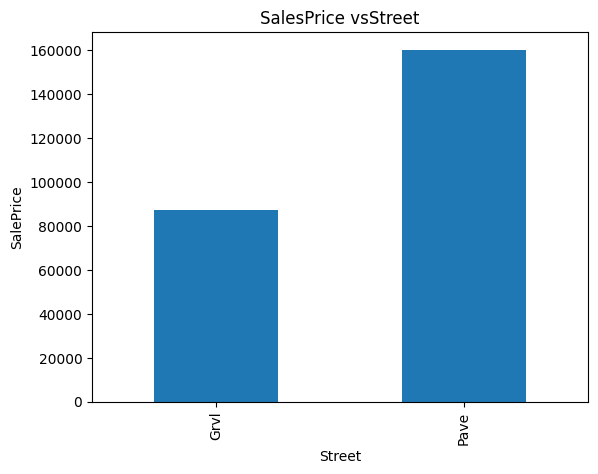

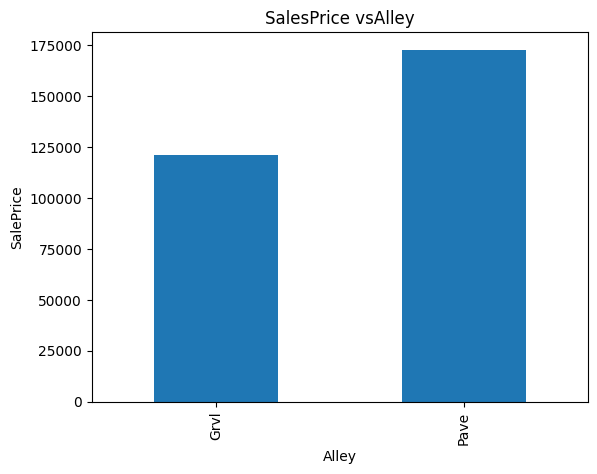

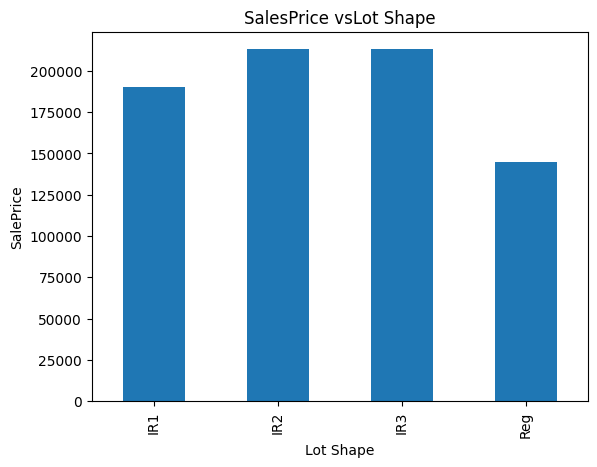

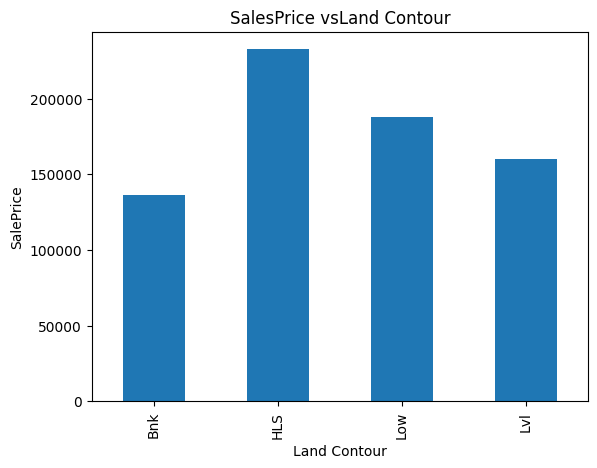

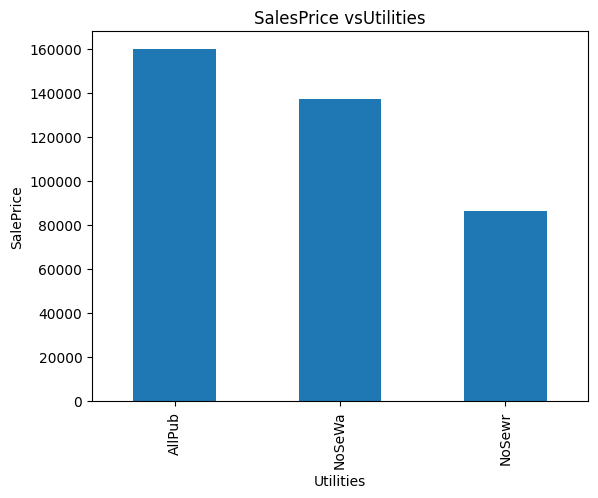

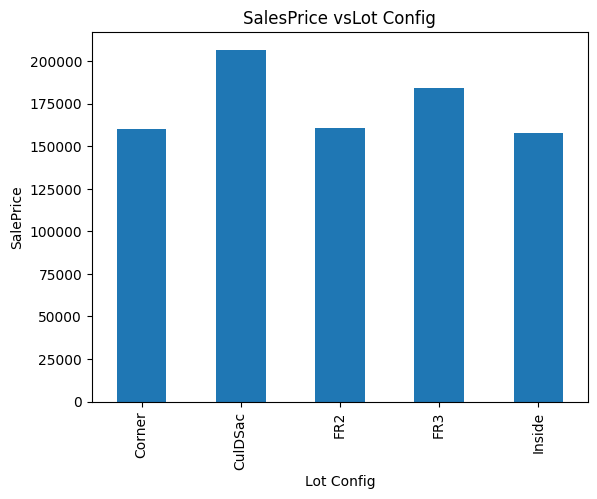

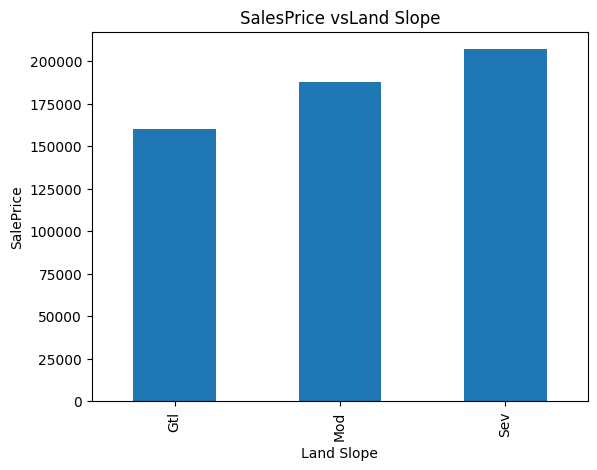

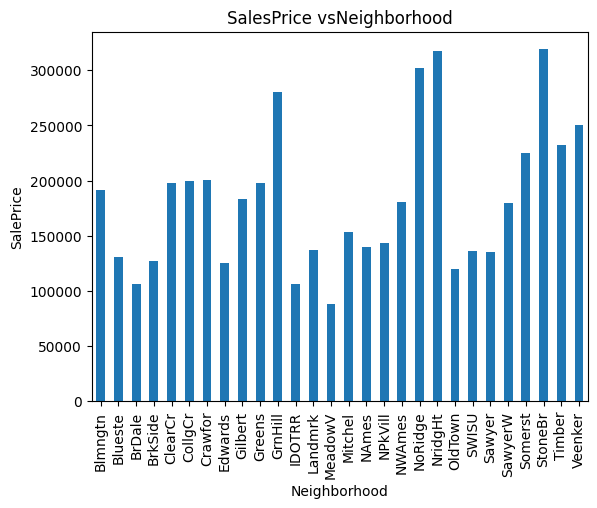

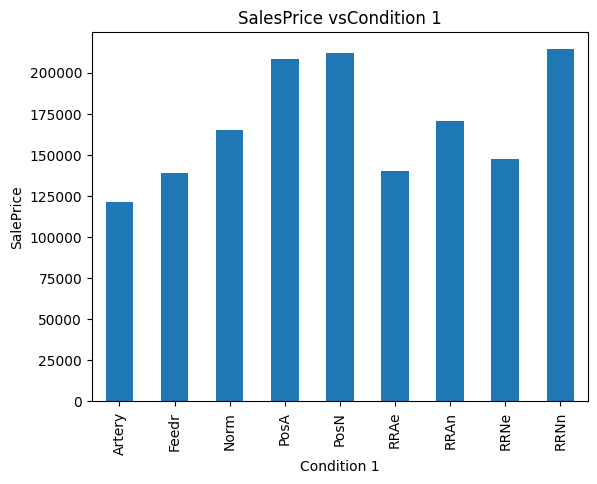

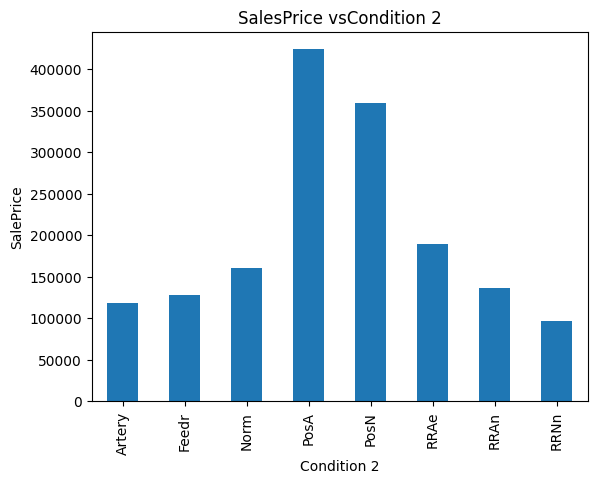

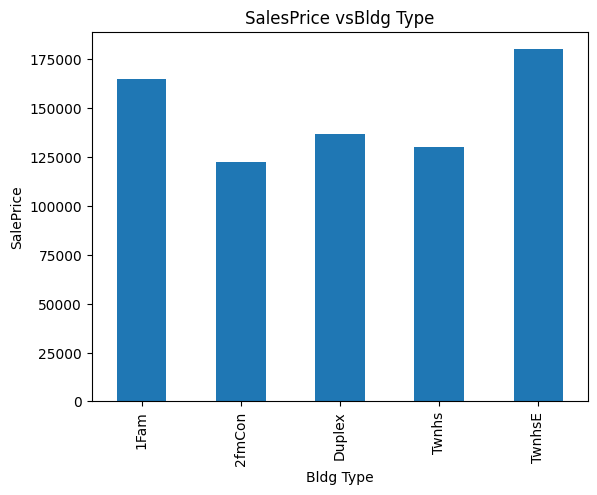

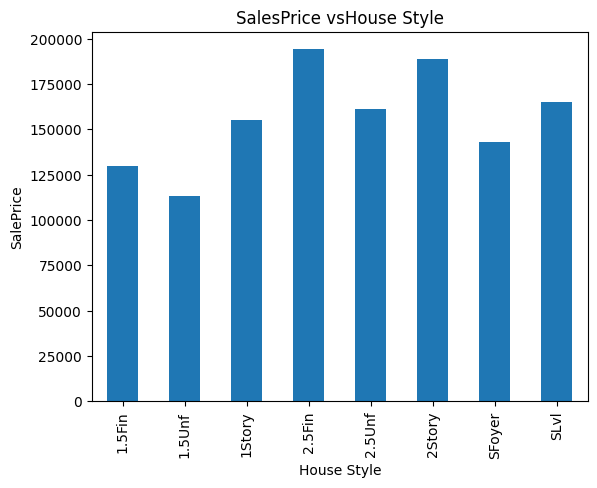

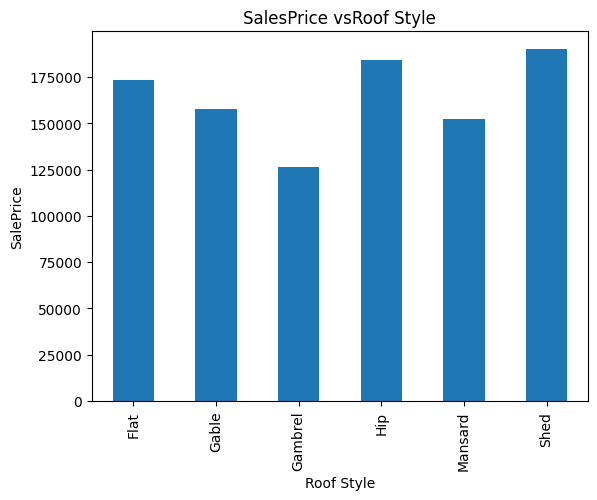

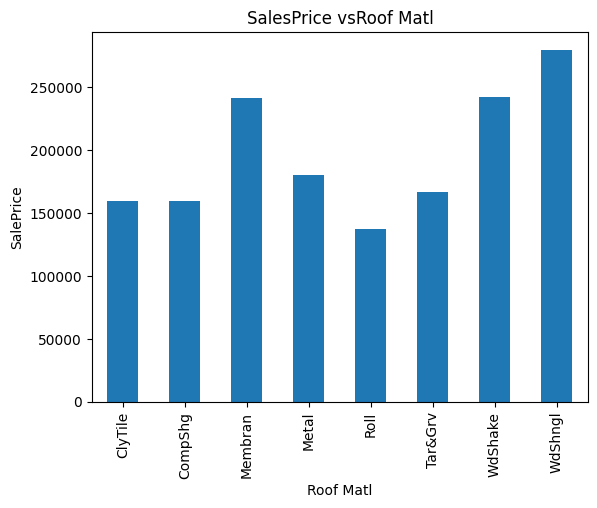

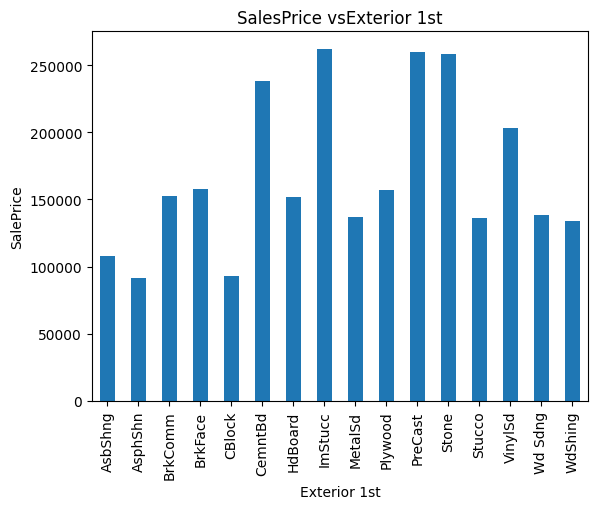

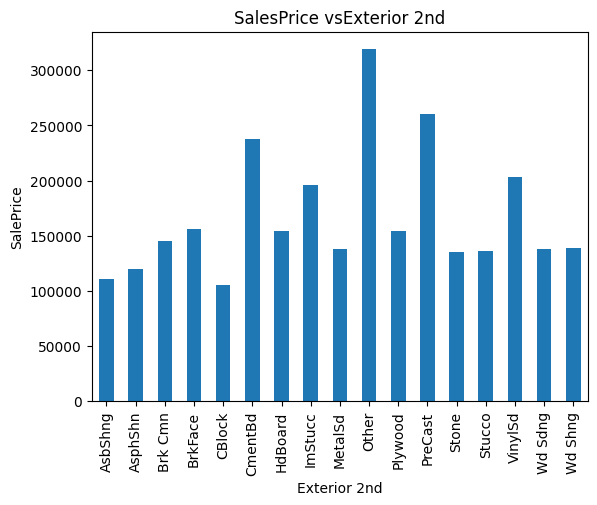

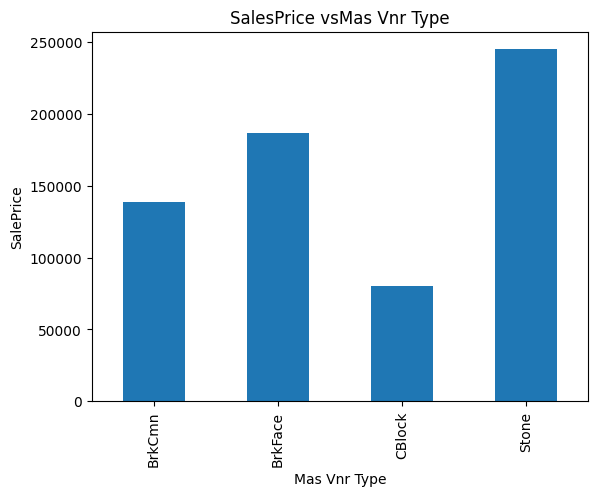

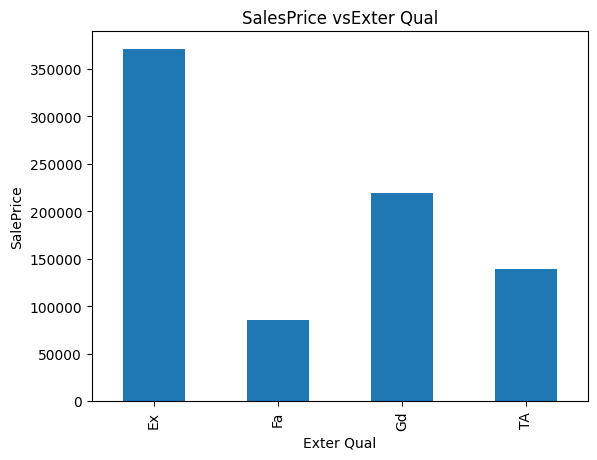

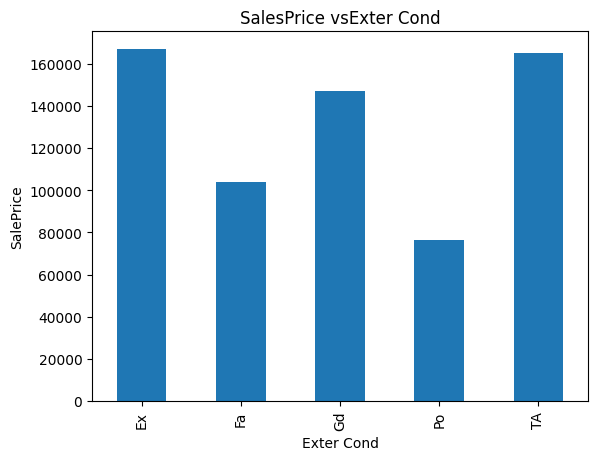

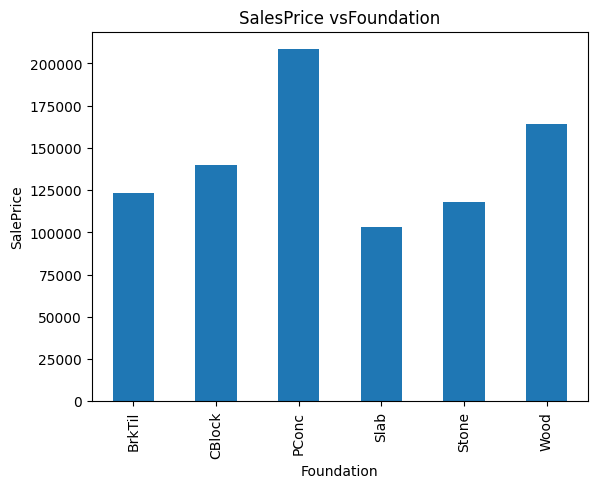

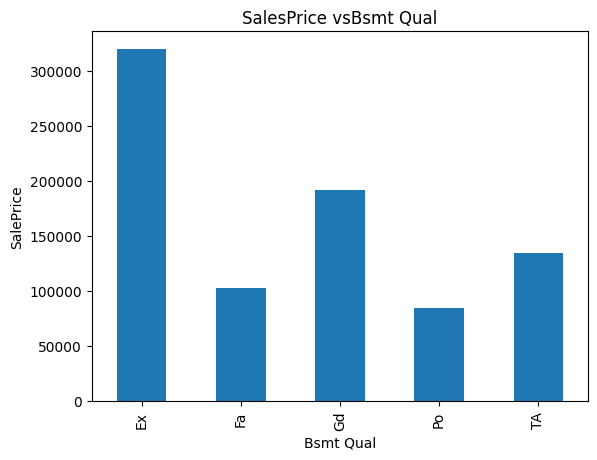

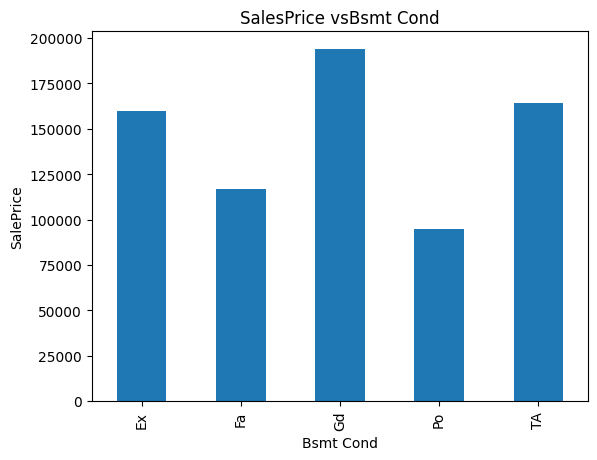

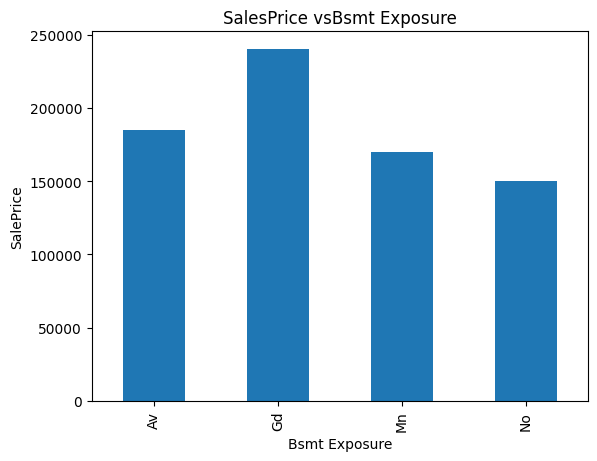

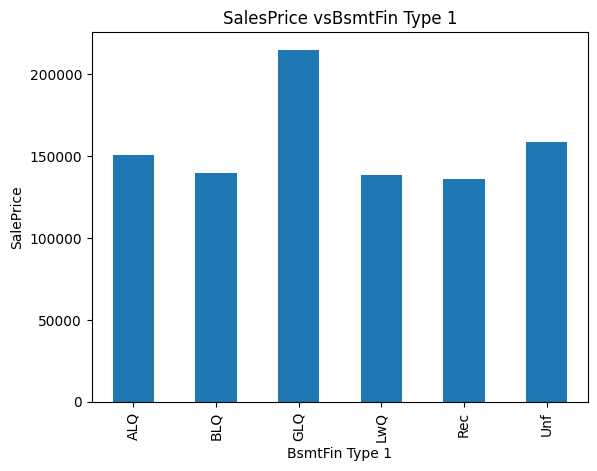

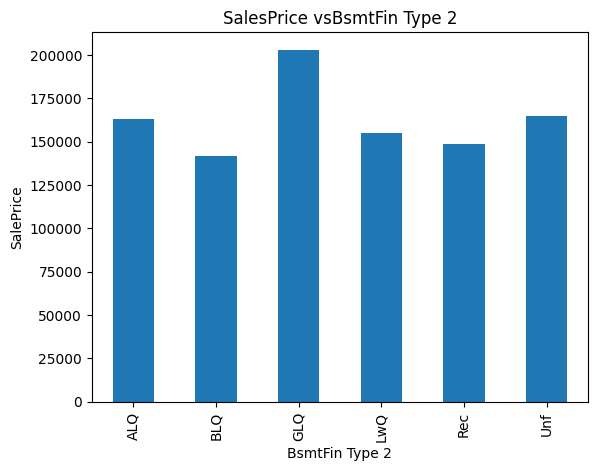

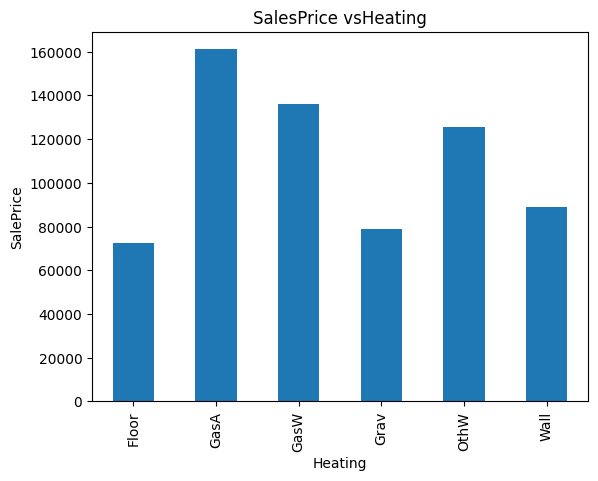

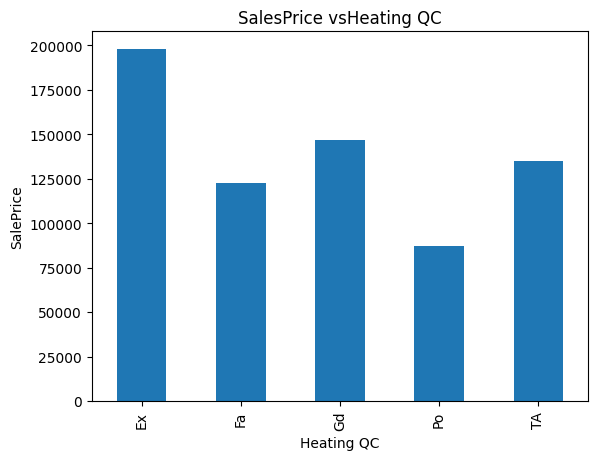

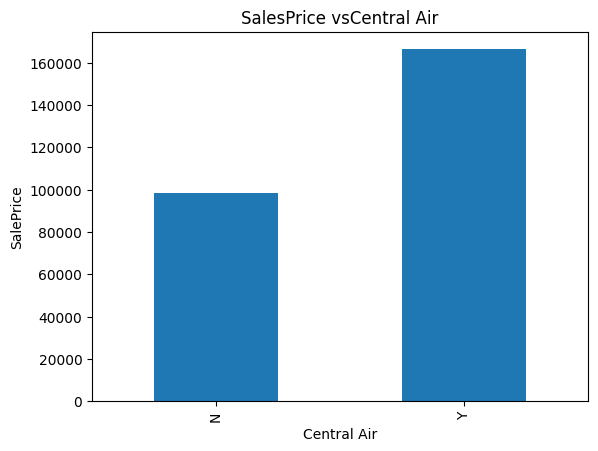

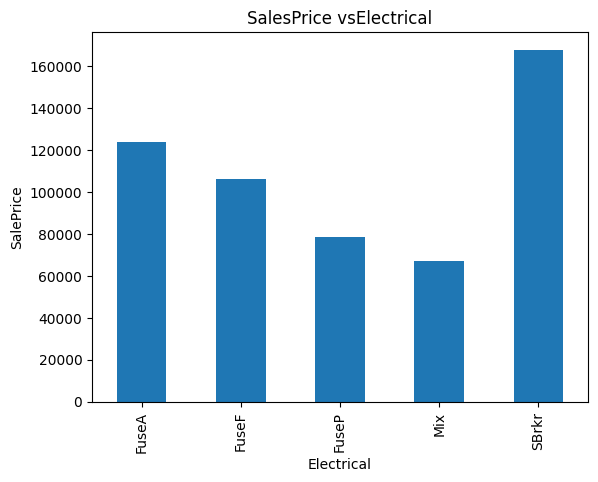

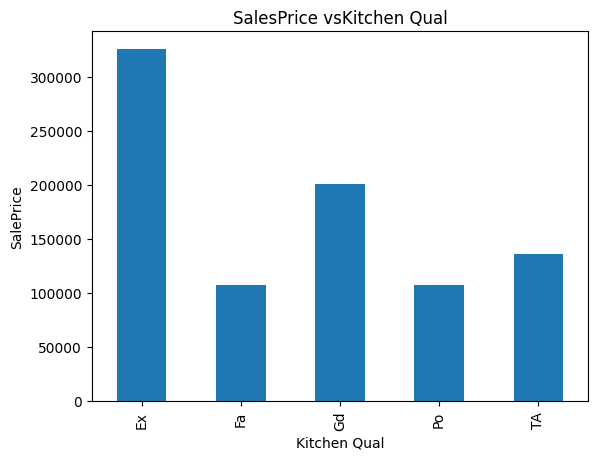

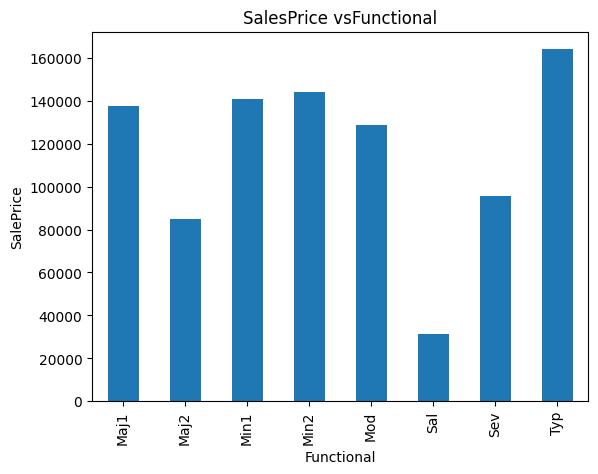

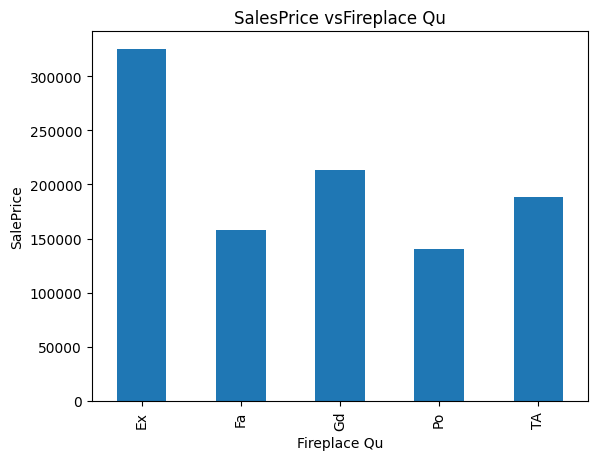

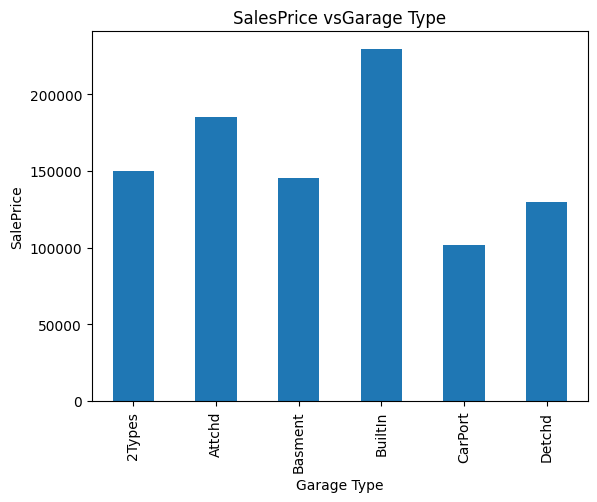

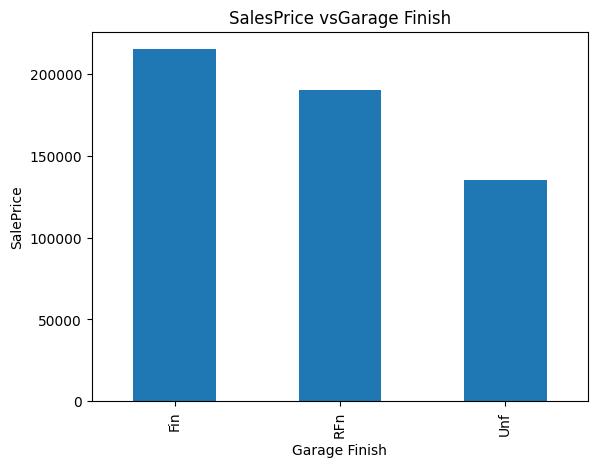

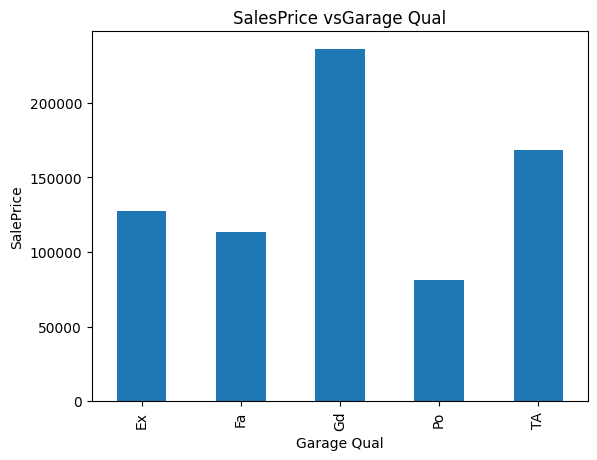

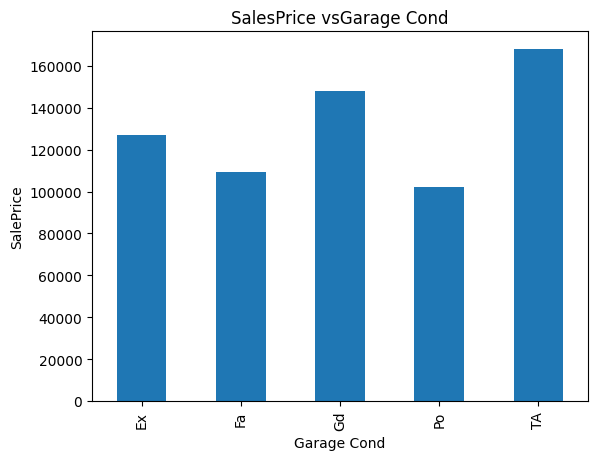

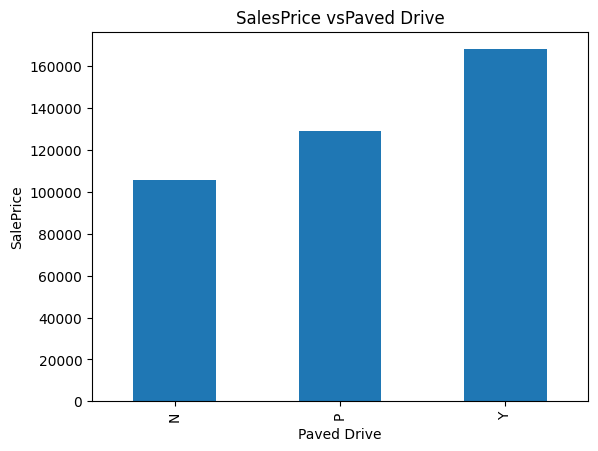

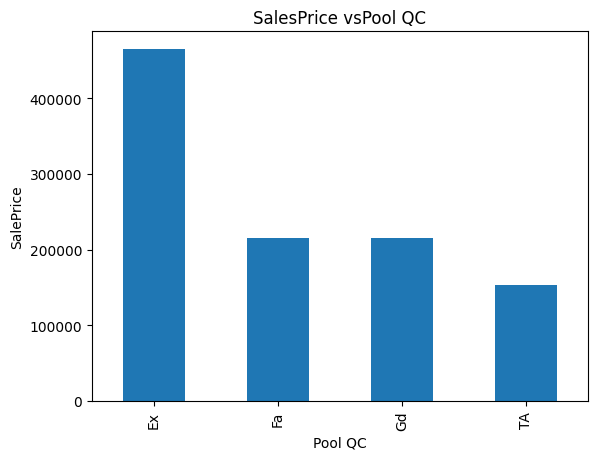

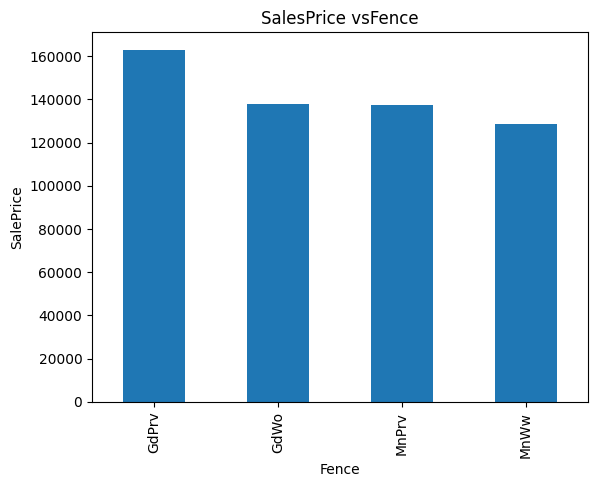

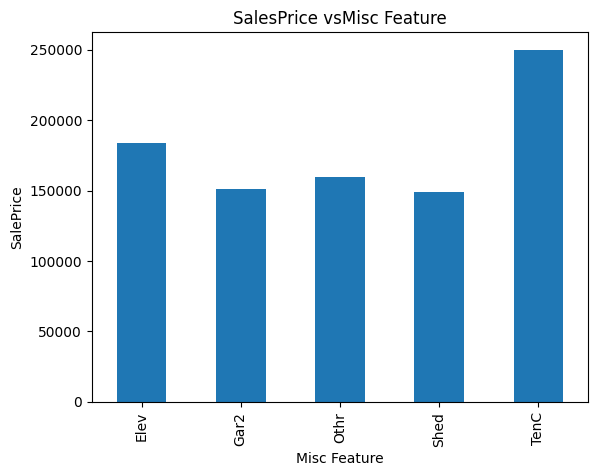

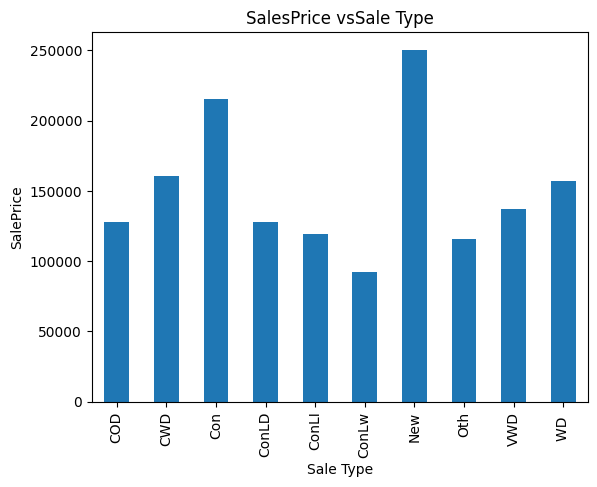

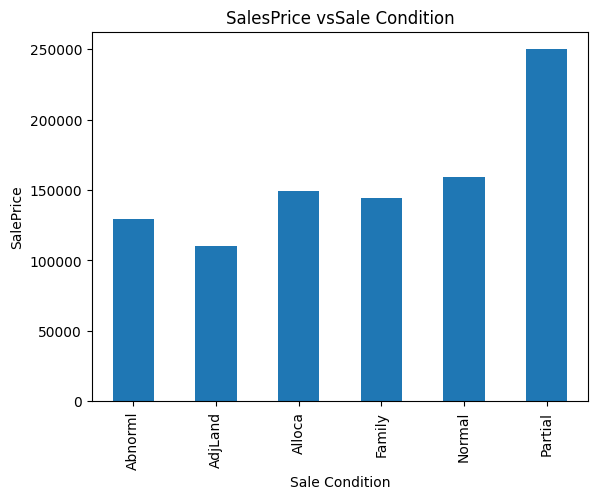

In [ ]:
# findinng relationship between each categorical feature on SalePrice

for feature in categorical_f:
  data = df.copy()

  data.groupby(feature)['SalePrice'].median().plot.bar()
  plt.title("SalesPrice vs" + feature)
  plt.xlabel(feature)
  plt.ylabel("SalePrice")
  plt.show()

# **Some Advance EDA using Seaborn Plots**

## 8. Numerical feature analysis

In [62]:
# Identify numerical columns
numerical_features = df.select_dtypes(include=np.number).columns.tolist()

# Identify categorical columns
categorical_features = df.select_dtypes(include=["object", "category"]).columns.tolist()

print("Number of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

print("\nNumerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Number of numerical features: 39
Number of categorical features: 43

Numerical features:
['Order', 'PID', 'MS SubClass', 'Lot Frontage', 'Lot Area', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add', 'Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'TotRms AbvGrd', 'Fireplaces', 'Garage Yr Blt', 'Garage Cars', 'Garage Area', 'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch', 'Screen Porch', 'Pool Area', 'Misc Val', 'Mo Sold', 'Yr Sold', 'SalePrice']

Categorical features:
['MS Zoning', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 

<details>
<summary><strong>Observation – Feature types</strong></summary>

Numerical columns contain measurable or coded numeric values. Categorical columns represent groups or labels.
Some numeric columns, such as `MS SubClass`, may represent categories even though they are stored as numbers. Use the meaning of each feature, not only its data type, when deciding how to analyze it.
</details>

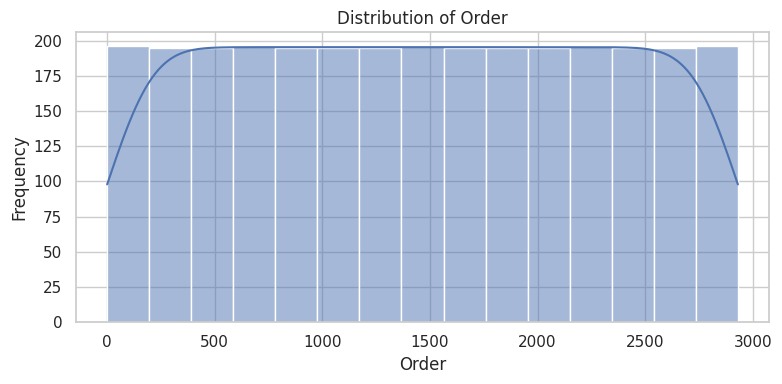

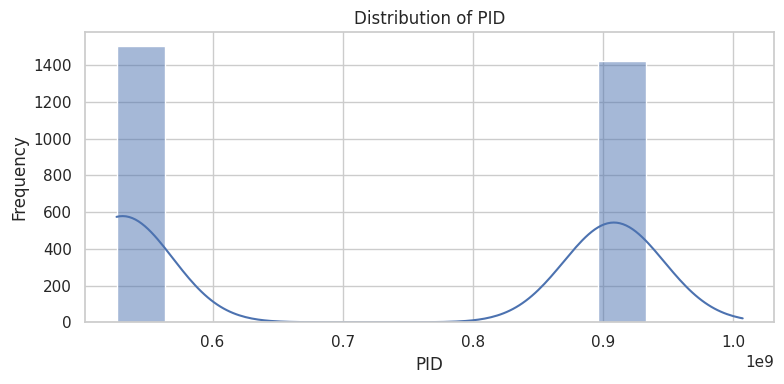

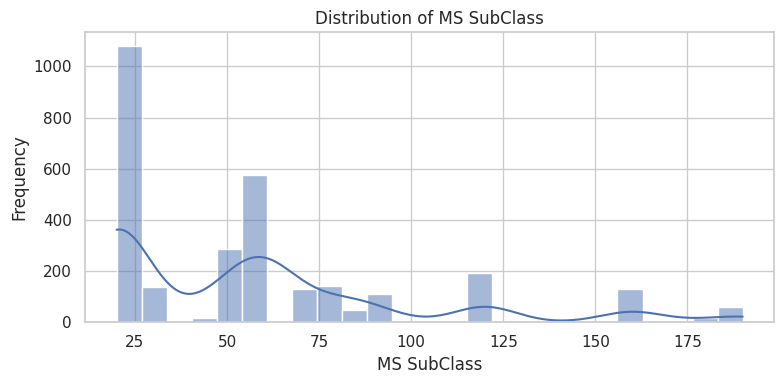

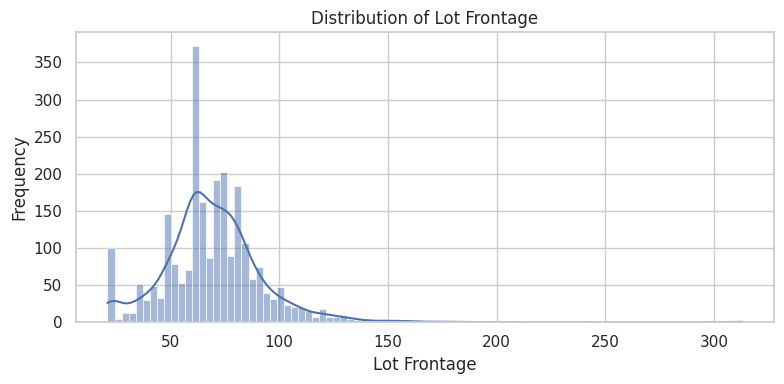

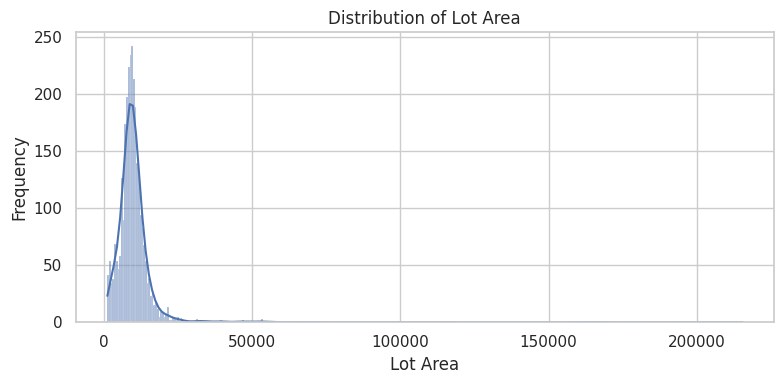

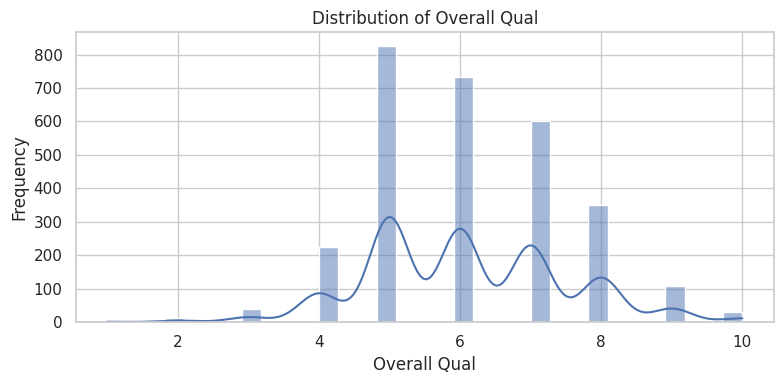

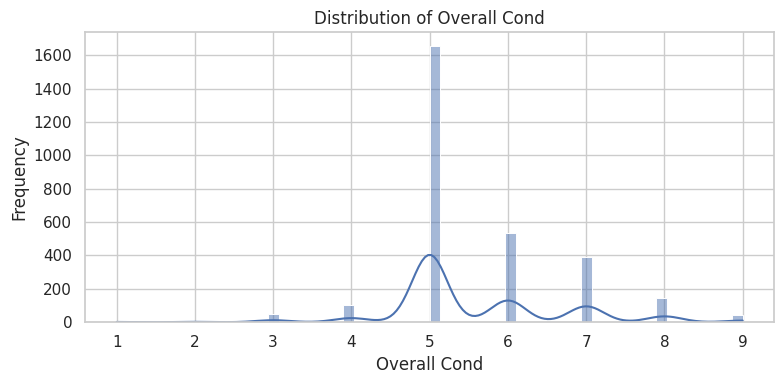

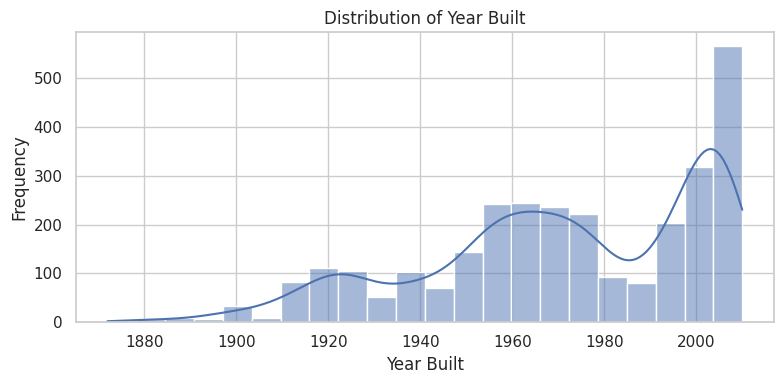

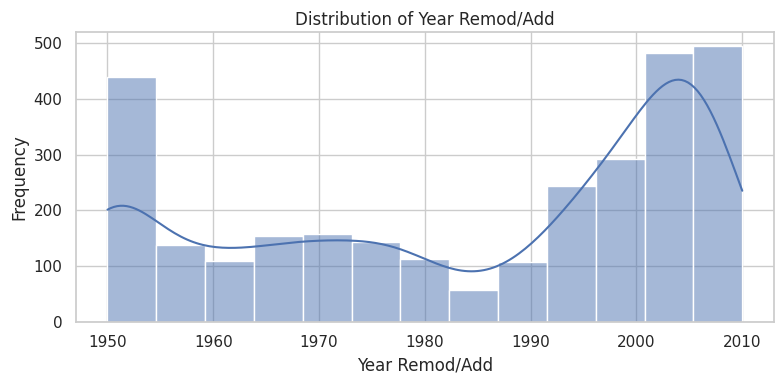

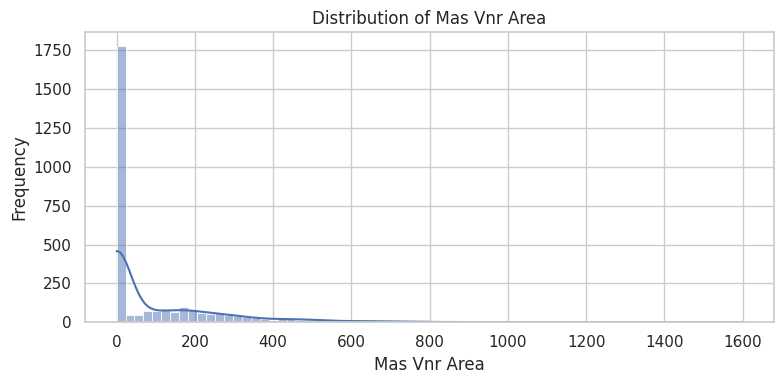

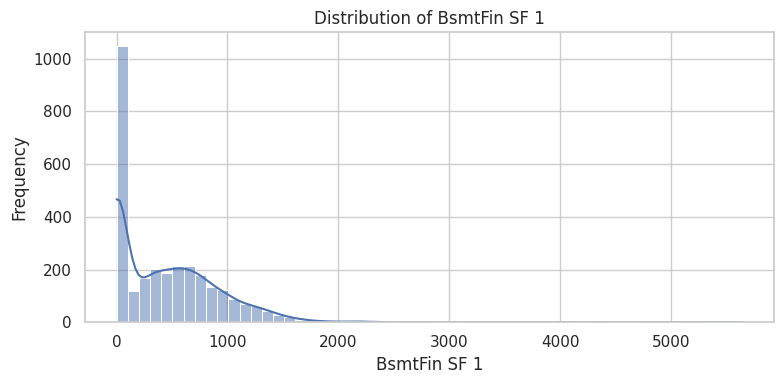

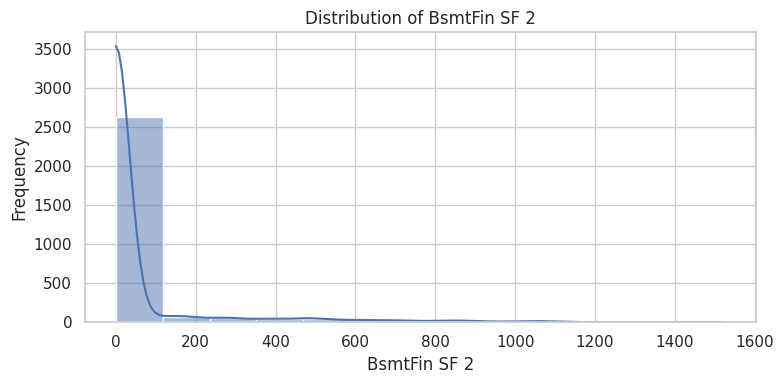

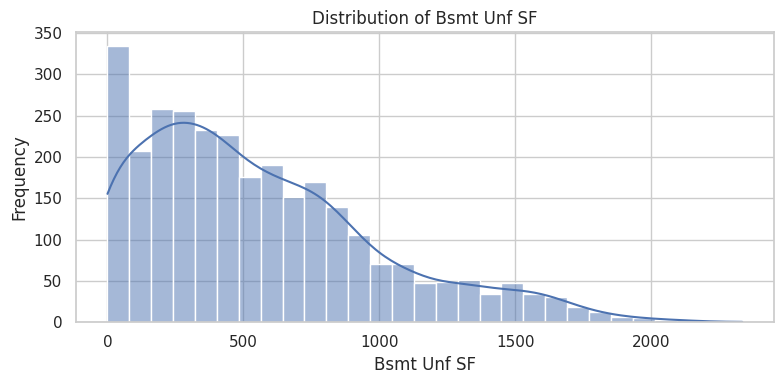

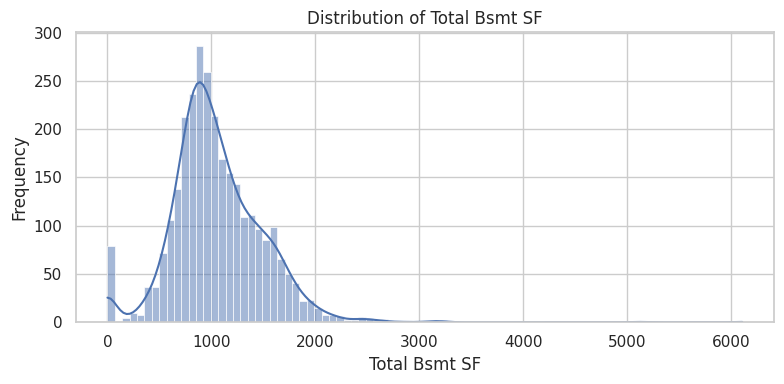

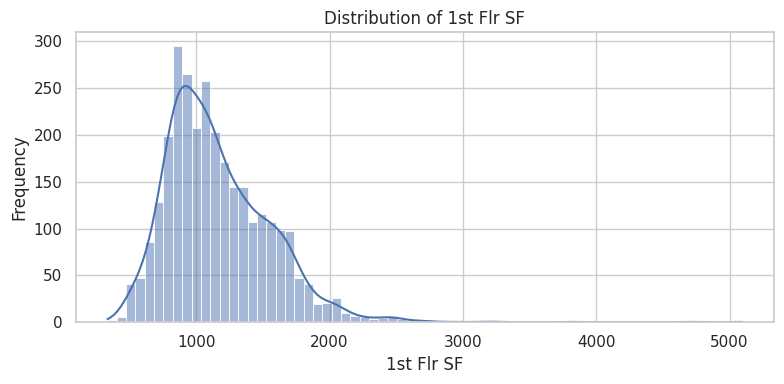

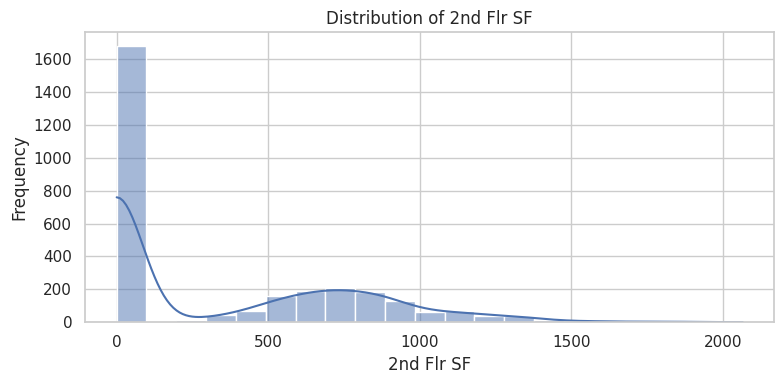

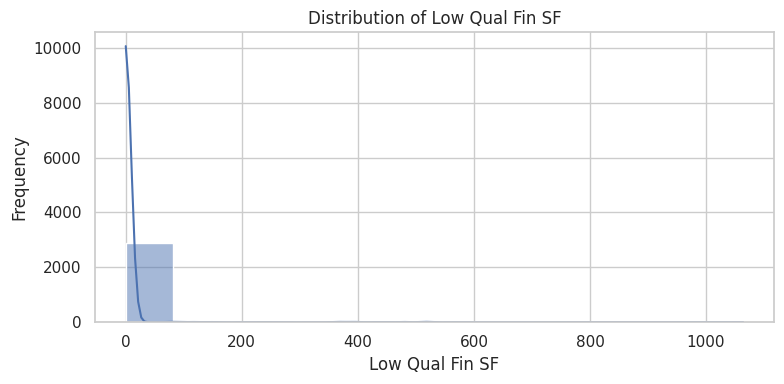

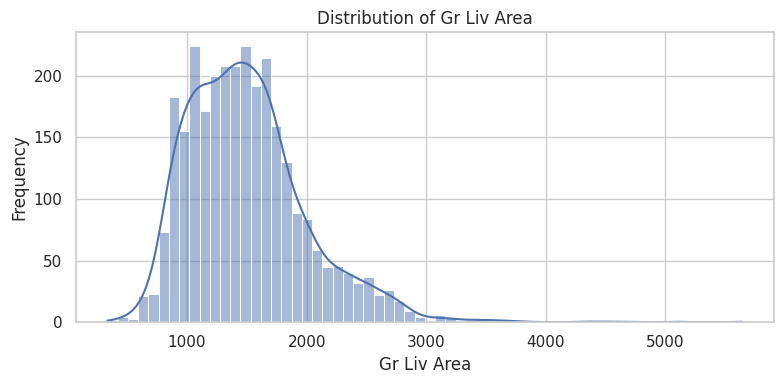

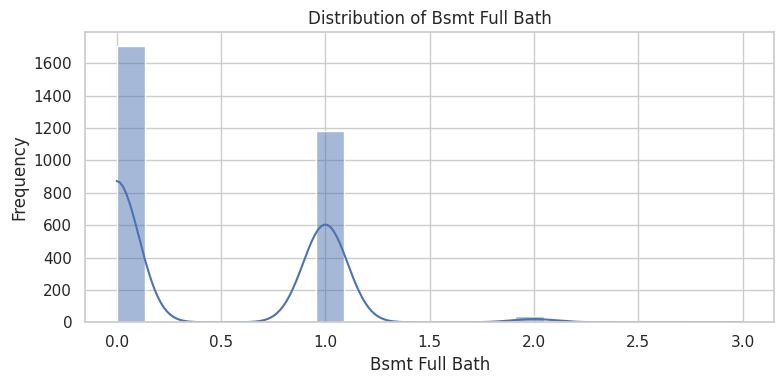

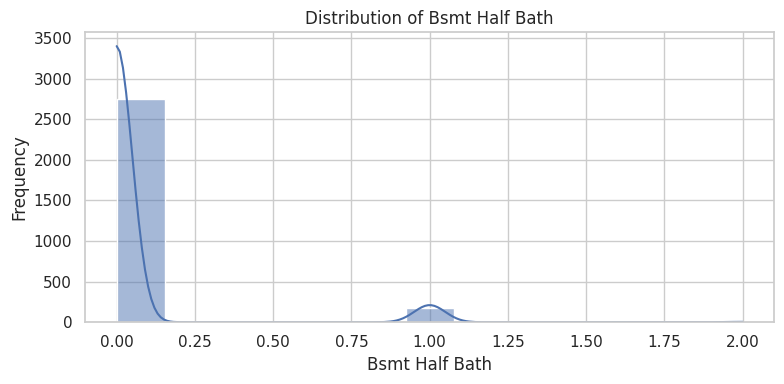

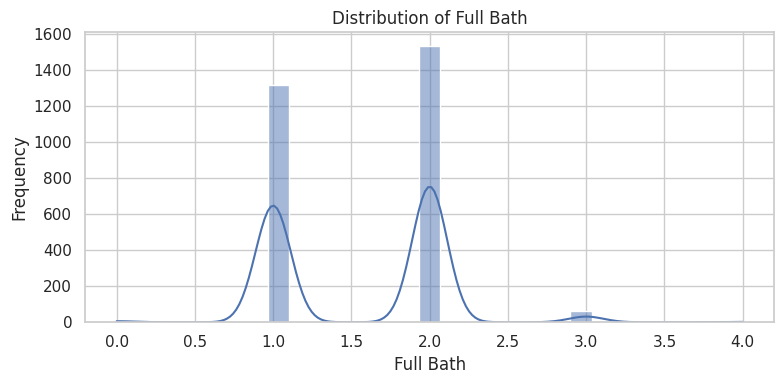

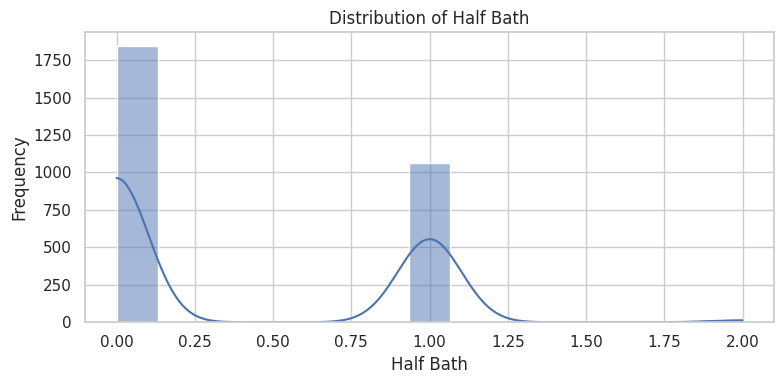

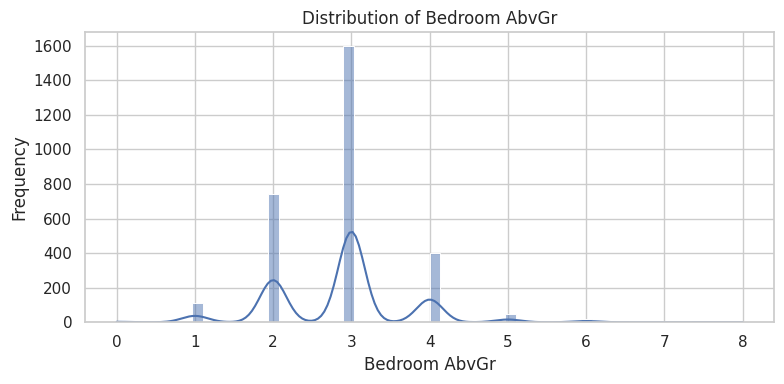

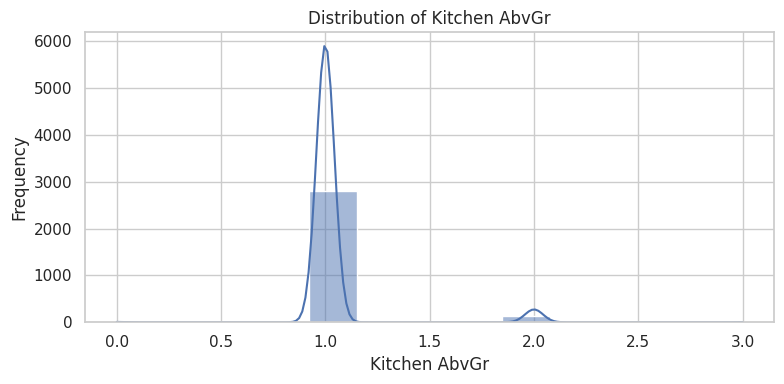

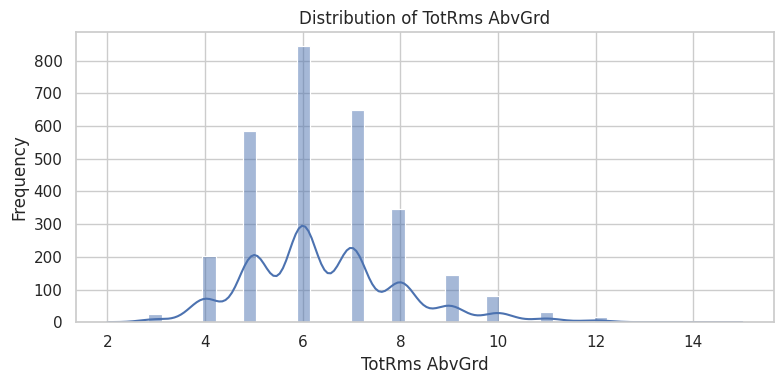

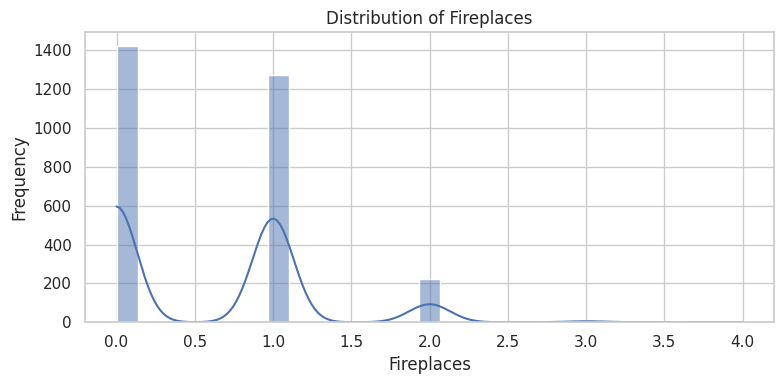

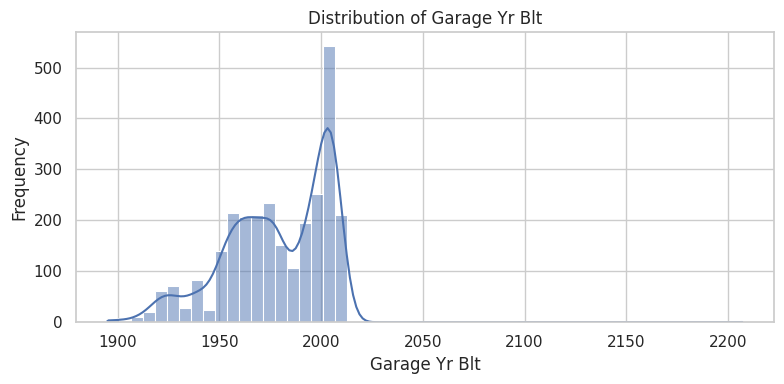

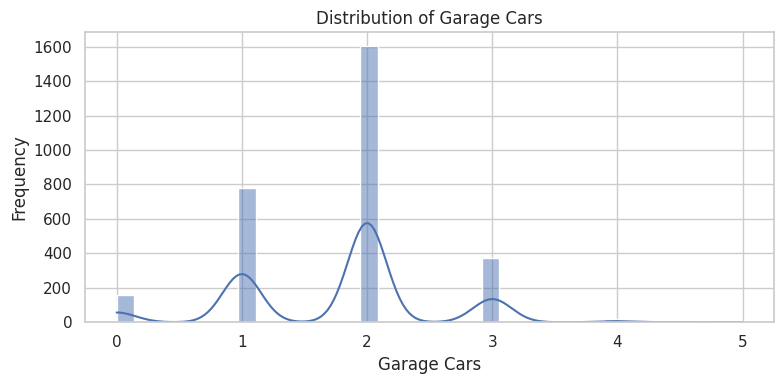

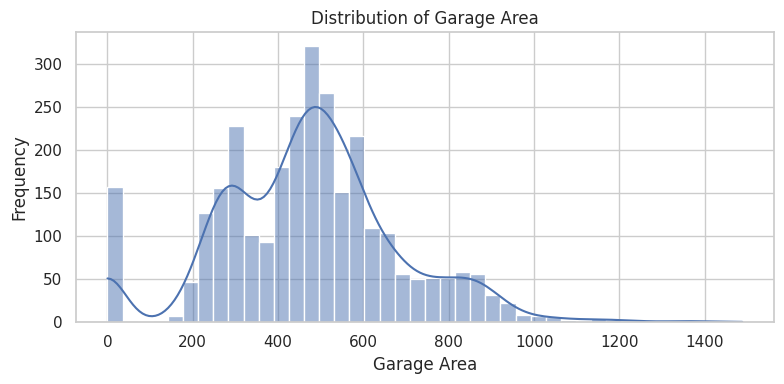

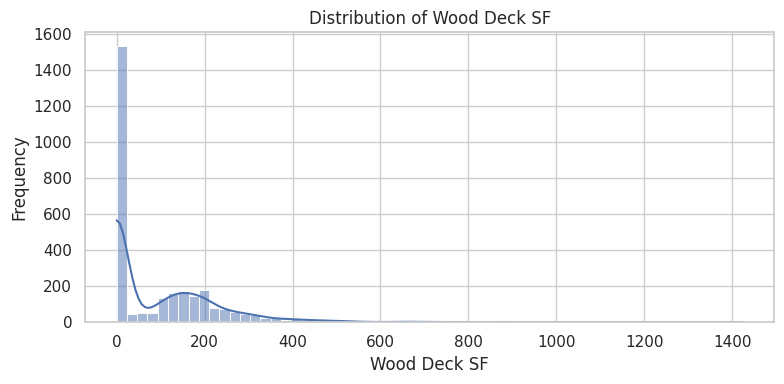

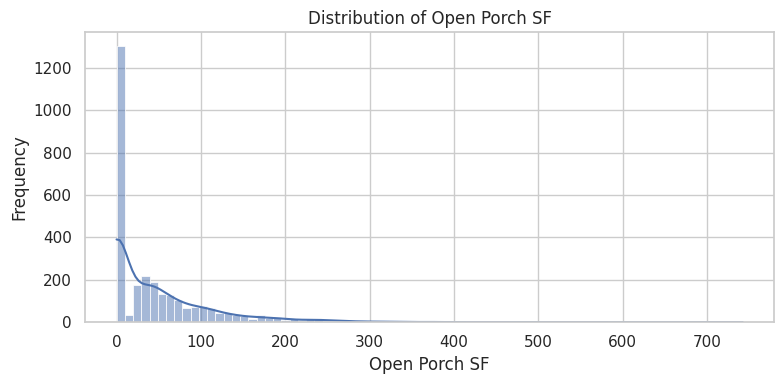

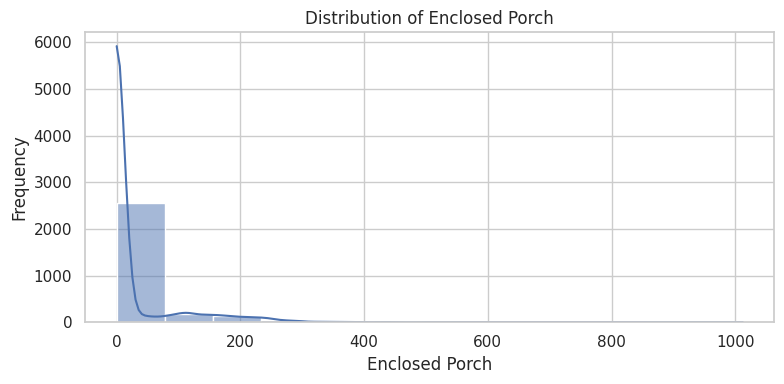

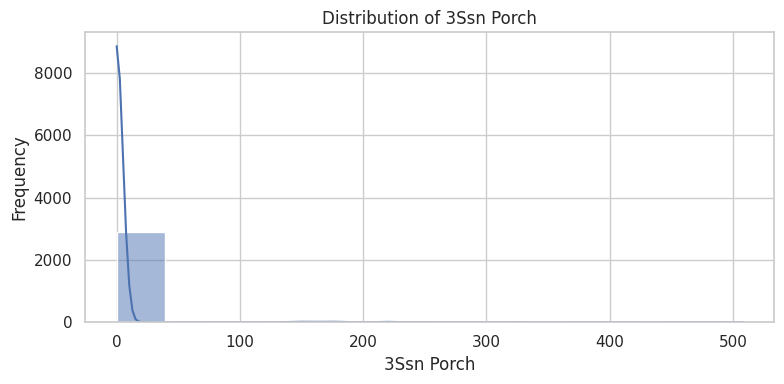

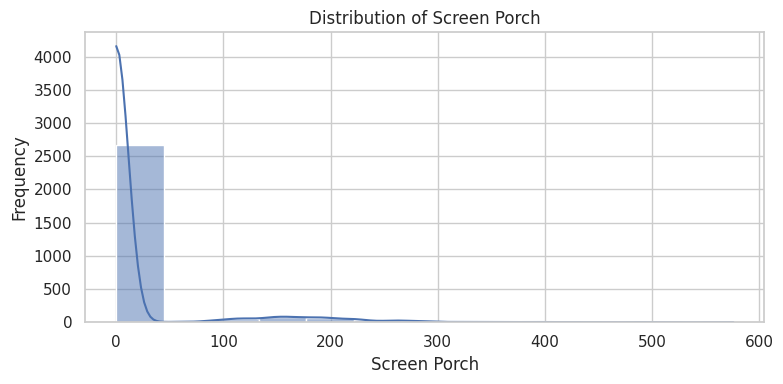

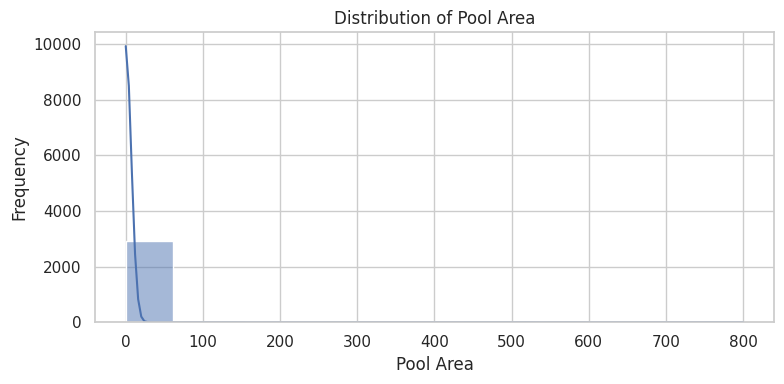

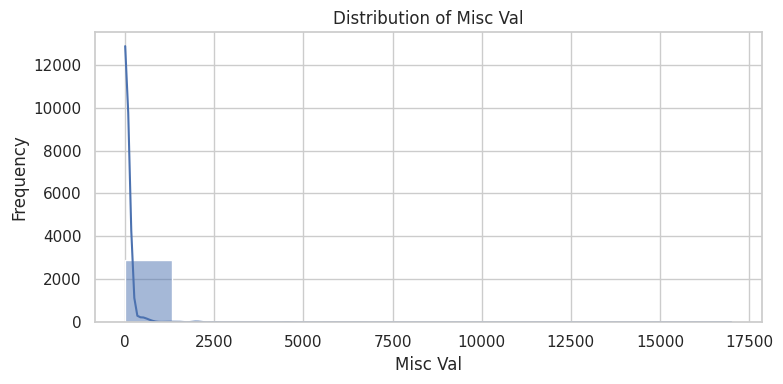

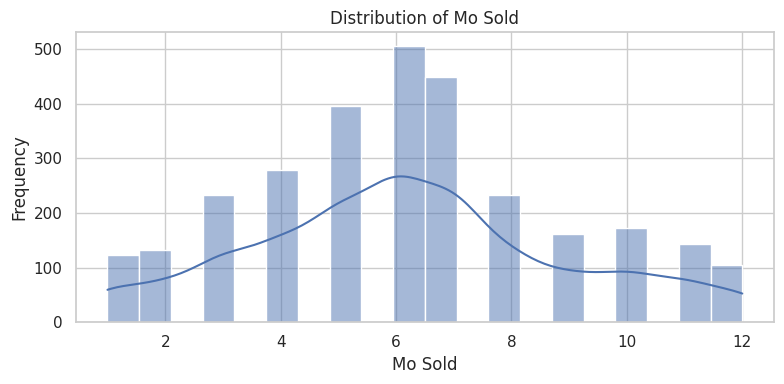

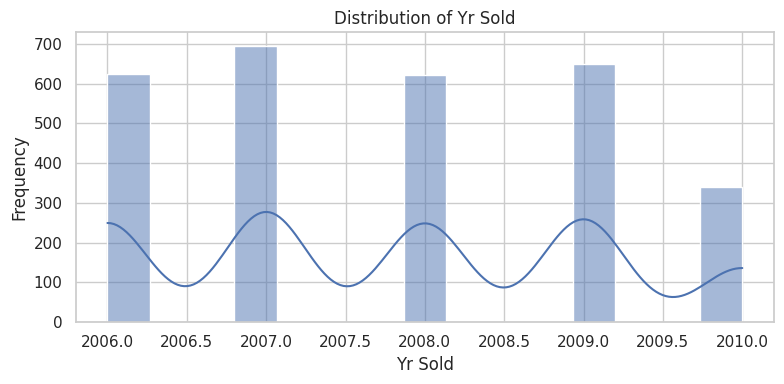

In [63]:
# Exclude the target from independent numerical features
numeric_predictors = [
    feature for feature in numerical_features
    if feature != TARGET
]

# Plot distributions for numerical predictors
for feature in numeric_predictors:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=df, x=feature, kde=True)
    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

<details>
<summary><strong>Observation – Numerical distributions</strong></summary>

For each important feature, note:
- Whether values are concentrated in a small range.
- Whether the distribution is skewed.
- Whether there are unusual gaps or extreme values.
- Whether the feature is actually a numeric measurement or a coded category.

You do not need to write an observation for every single plot. Focus on features that may affect house prices or need preprocessing.
</details>

### 8.1 Discrete and continuous numerical features

In [64]:
# Features with a relatively small number of unique values are candidates
# for discrete/categorical-style numerical analysis.
discrete_features = []

for feature in numeric_predictors:
    if df[feature].nunique(dropna=True) <= 20:
        discrete_features.append(feature)

# Remaining numerical predictors are treated as continuous candidates
continuous_features = [
    feature for feature in numeric_predictors
    if feature not in discrete_features
]

print("Discrete numerical candidates:", discrete_features)
print("\nContinuous numerical candidates:", continuous_features)

Discrete numerical candidates: ['MS SubClass', 'Overall Qual', 'Overall Cond', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'TotRms AbvGrd', 'Fireplaces', 'Garage Cars', 'Pool Area', 'Mo Sold', 'Yr Sold']

Continuous numerical candidates: ['Order', 'PID', 'Lot Frontage', 'Lot Area', 'Year Built', 'Year Remod/Add', 'Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Garage Yr Blt', 'Garage Area', 'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch', 'Screen Porch', 'Misc Val']


<details>
<summary><strong>Observation – Discrete vs continuous features</strong></summary>

This is a practical first-pass grouping based on the number of unique values, not a definitive classification. Review features such as year, month, quality ratings, and class codes using their meanings before modelling.
</details>

### 8.2 Numerical features vs SalePrice

In [65]:
# Correlation of each numerical feature with SalePrice
correlation_with_target = (
    df[numerical_features]
    .corr(numeric_only=True)[TARGET]
    .drop(TARGET)
    .sort_values(ascending=False)
)

display(correlation_with_target.to_frame("Correlation_with_SalePrice"))

,Correlation_with_SalePrice
Overall Qual,0.799262
Gr Liv Area,0.706780
Garage Cars,0.647877
Garage Area,0.640401
Total Bsmt SF,0.632280
1st Flr SF,0.621676
Year Built,0.558426
Full Bath,0.545604
Year Remod/Add,0.532974
Garage Yr Blt,0.526965


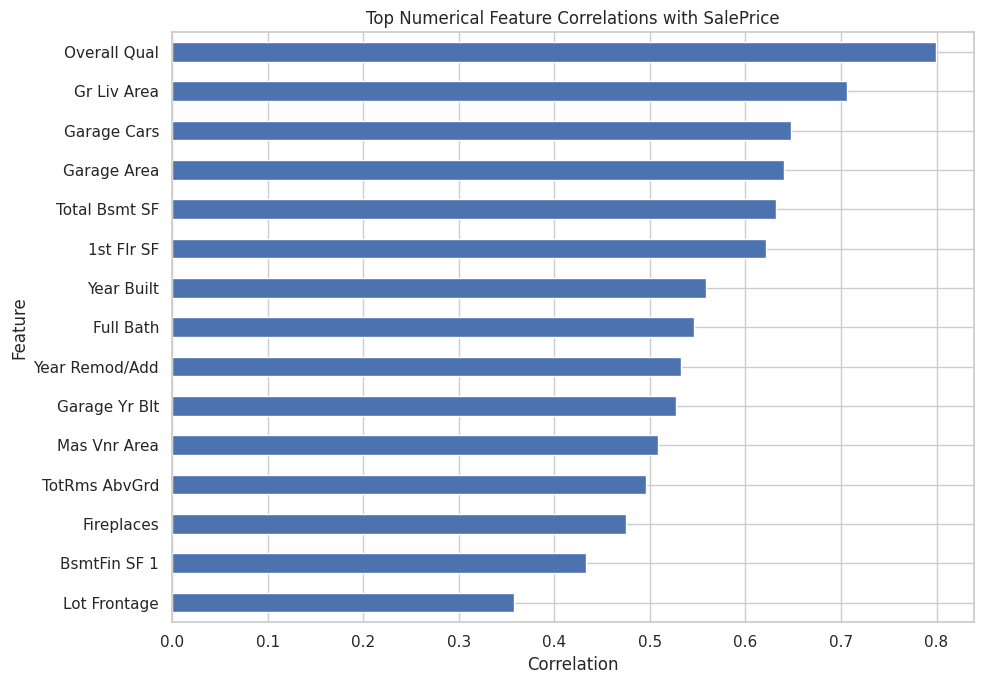

In [66]:
# Plot the strongest positive and negative correlations
top_correlations = correlation_with_target.reindex(
    correlation_with_target.abs().sort_values(ascending=False).head(15).index
).sort_values()

plt.figure(figsize=(10, 7))
top_correlations.plot(kind="barh")
plt.title("Top Numerical Feature Correlations with SalePrice")
plt.xlabel("Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

<details>
<summary><strong>Observation – Numerical features and SalePrice</strong></summary>

A positive correlation means the two variables tend to increase together; a negative correlation means one tends to decrease as the other increases.

Correlation measures linear association, not causation. A low correlation does not necessarily mean a feature is useless, because relationships can be non-linear or depend on other features.
</details>

## 9. Categorical feature analysis

In [67]:
# Show the number of unique categories in each categorical feature
cardinality = pd.DataFrame({
    "Feature": categorical_features,
    "Unique_Categories": [
        df[feature].nunique(dropna=True)
        for feature in categorical_features
    ]
})

cardinality = cardinality.sort_values(
    "Unique_Categories",
    ascending=False
)

display(cardinality)

,Feature,Unique_Categories
8,Neighborhood,28
16,Exterior 2nd,17
15,Exterior 1st,16
41,Sale Type,10
9,Condition 1,9
12,House Style,8
31,Functional,8
14,Roof Matl,8
10,Condition 2,8
0,MS Zoning,7


<details>
<summary><strong>Observation – Categorical cardinality</strong></summary>

Cardinality means the number of unique categories in a feature. Features with many categories may need careful encoding. Check whether categories are meaningful and whether rare categories should be grouped during preprocessing.
</details>

In [68]:
# Display the most frequent categories for each categorical feature
for feature in categorical_features:
    print(f"\nFeature: {feature}")
    display(df[feature].value_counts(dropna=False).head(10).to_frame("Count"))


Feature: MS Zoning


,Count
MS Zoning,
RL,2273
RM,462
FV,139
RH,27
C (all),25
I (all),2
A (agr),2



Feature: Street


,Count
Street,
Pave,2918
Grvl,12



Feature: Alley


,Count
Alley,
NaN,2732
Grvl,120
Pave,78


... (76 outputs left out)


Feature: Sale Type


,Count
Sale Type,
WD,2536
New,239
COD,87
ConLD,26
CWD,12
ConLI,9
ConLw,8
Oth,7
Con,5



Feature: Sale Condition


,Count
Sale Condition,
Normal,2413
Partial,245
Abnorml,190
Family,46
Alloca,24
AdjLand,12


<details>
<summary><strong>Observation – Category frequency</strong></summary>

Look for dominant categories, rare categories, and missing values. Rare categories may cause issues with one-hot encoding, especially when the dataset is split into training and testing sets.
</details>

### 9.1 Categorical features vs SalePrice

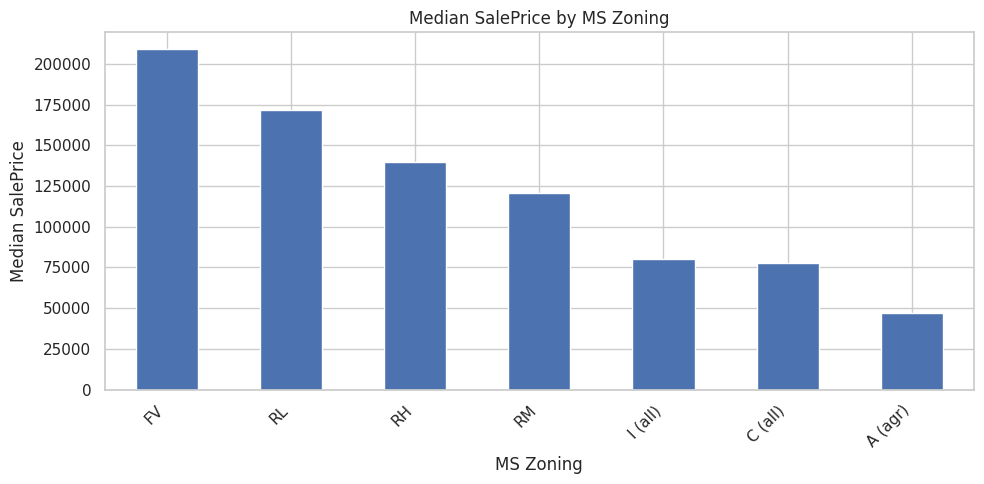

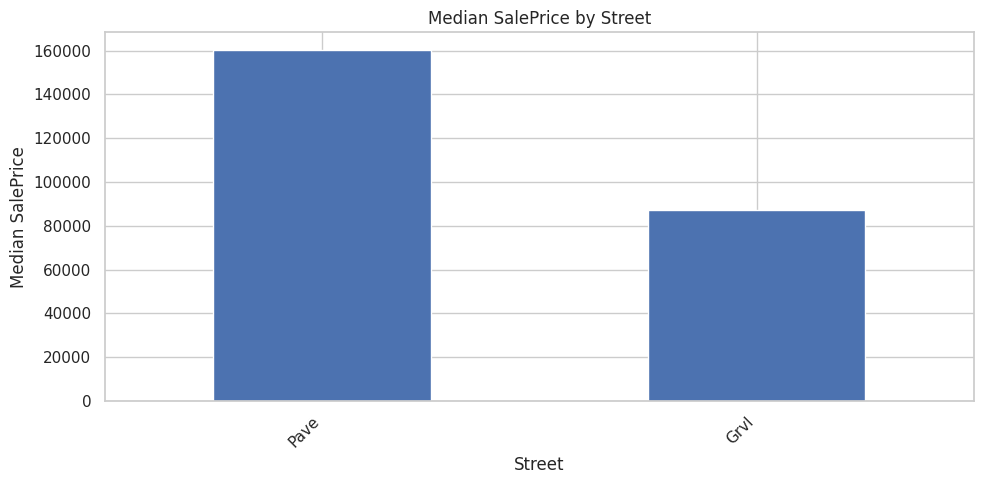

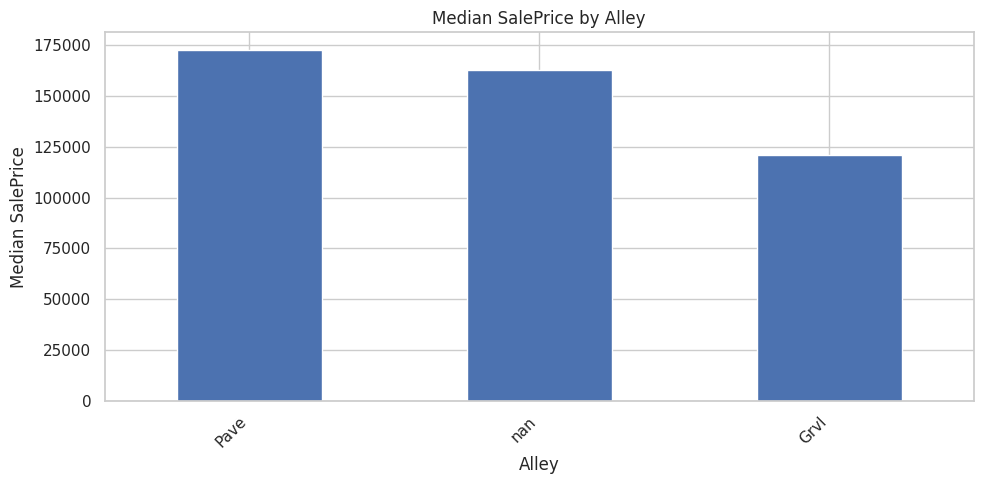

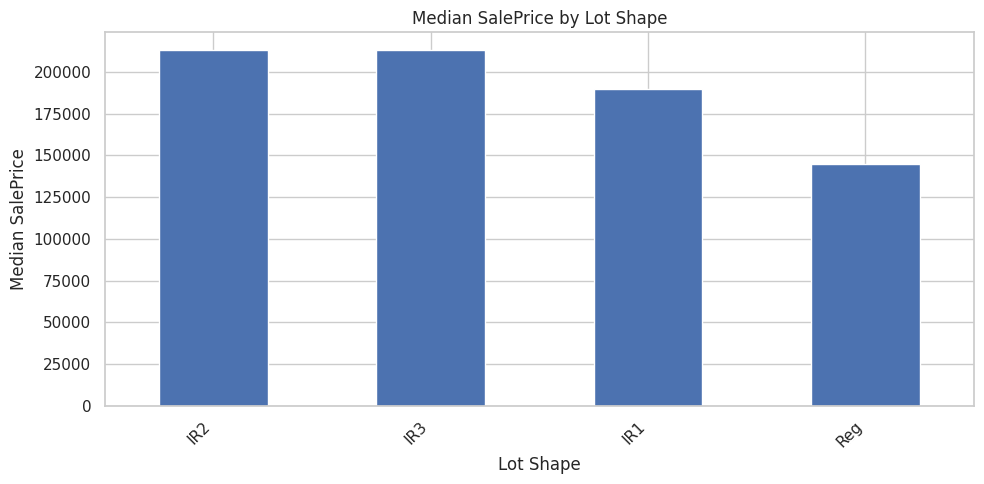

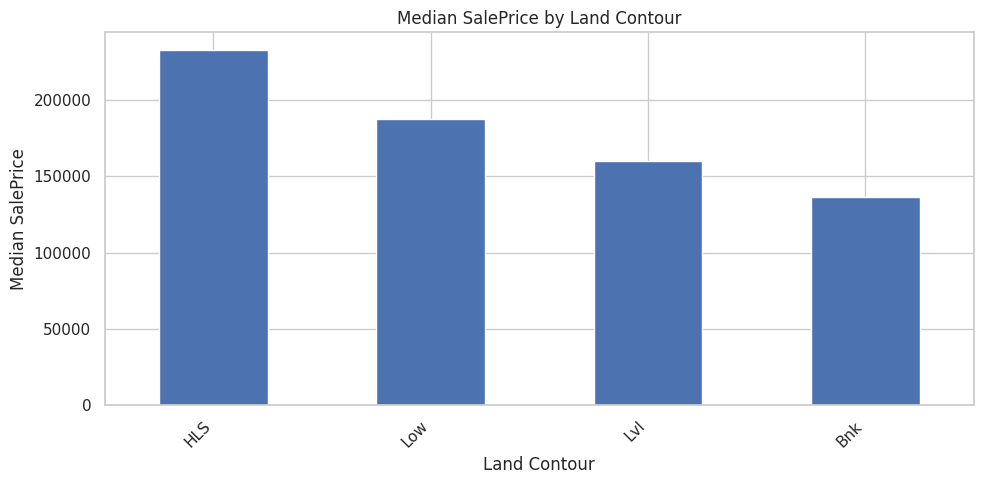

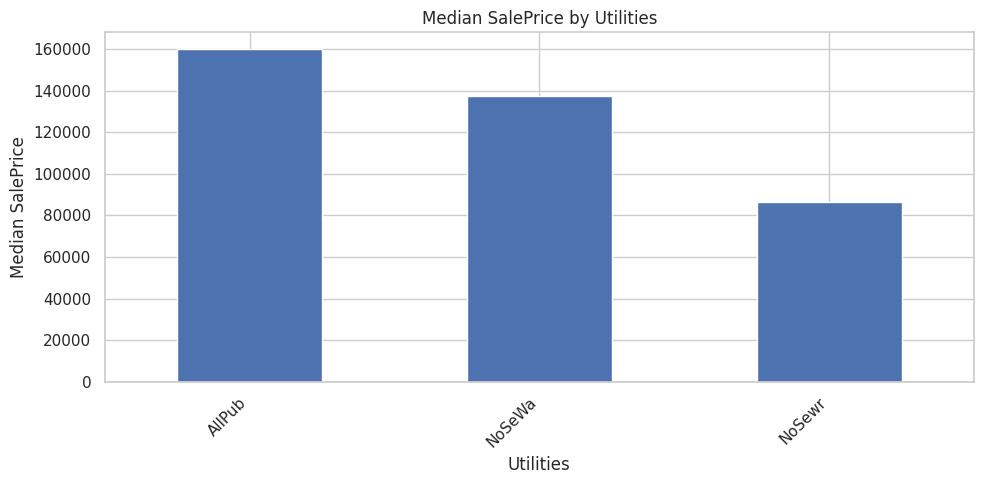

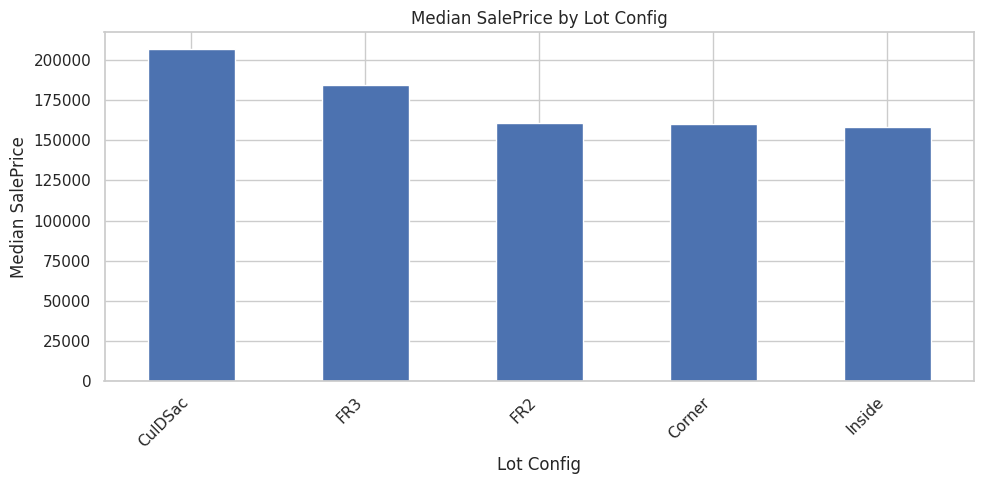

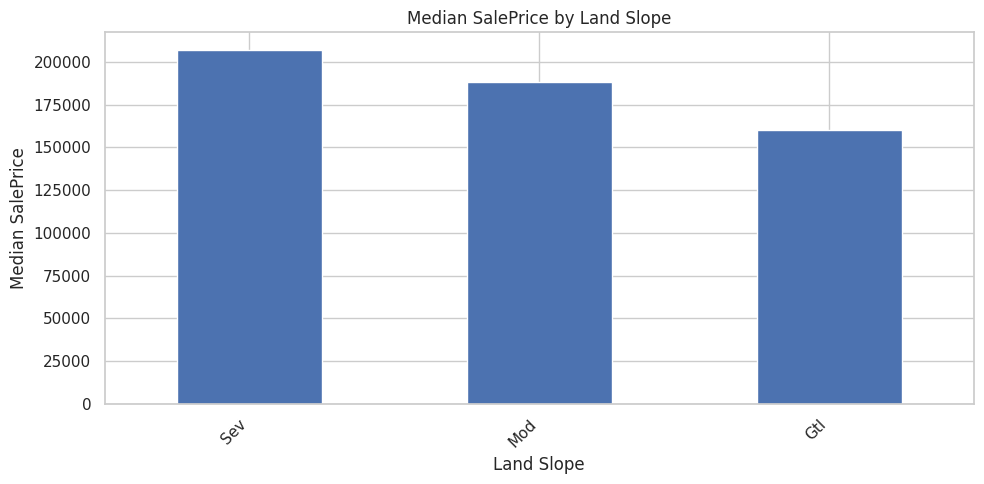

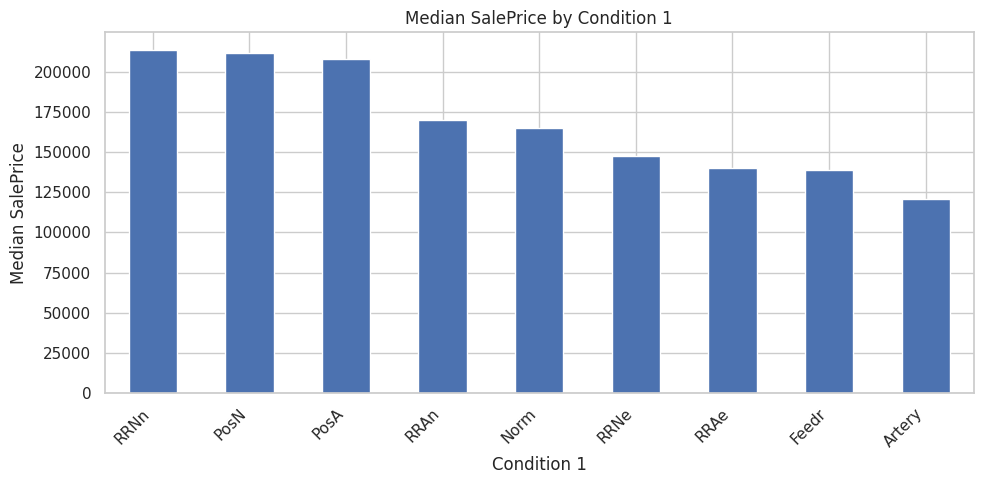

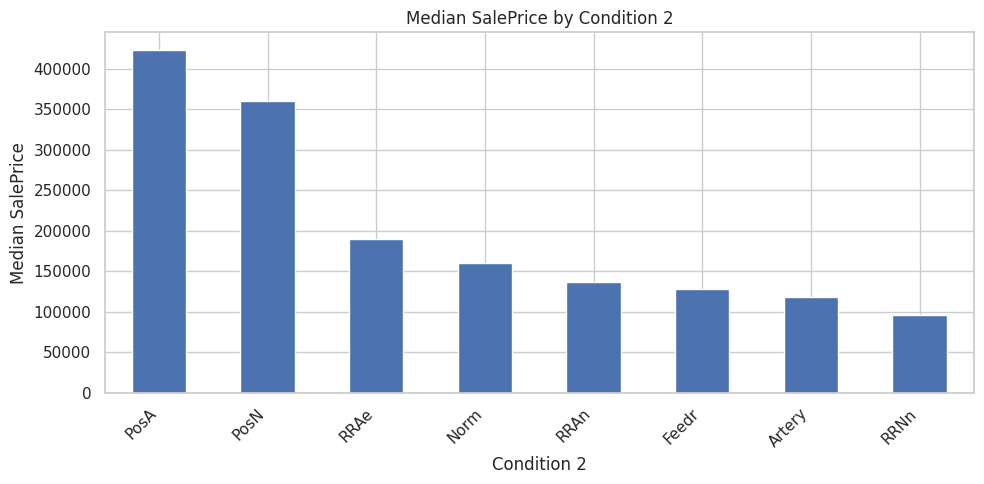

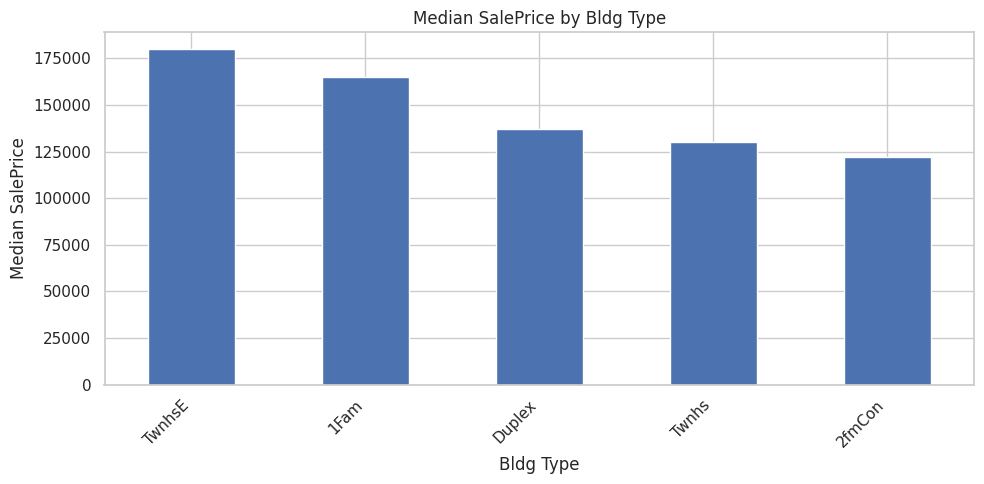

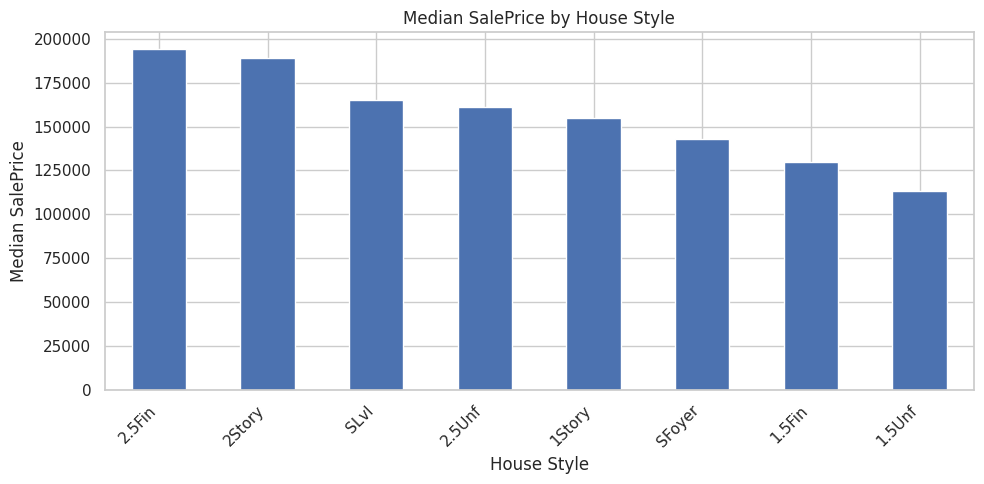

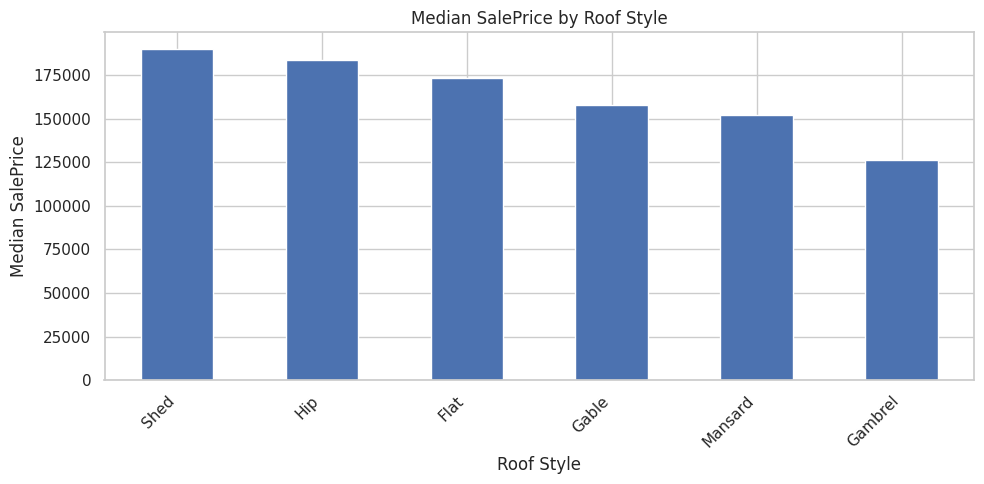

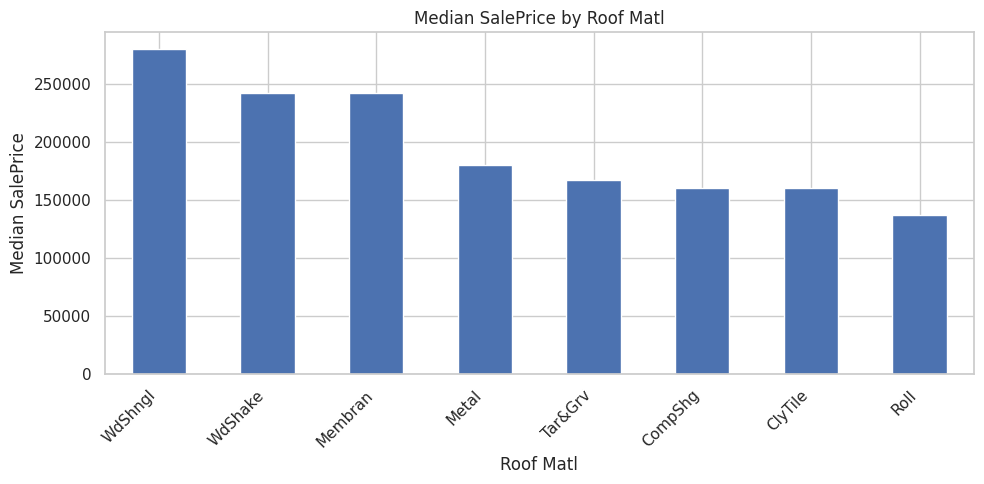

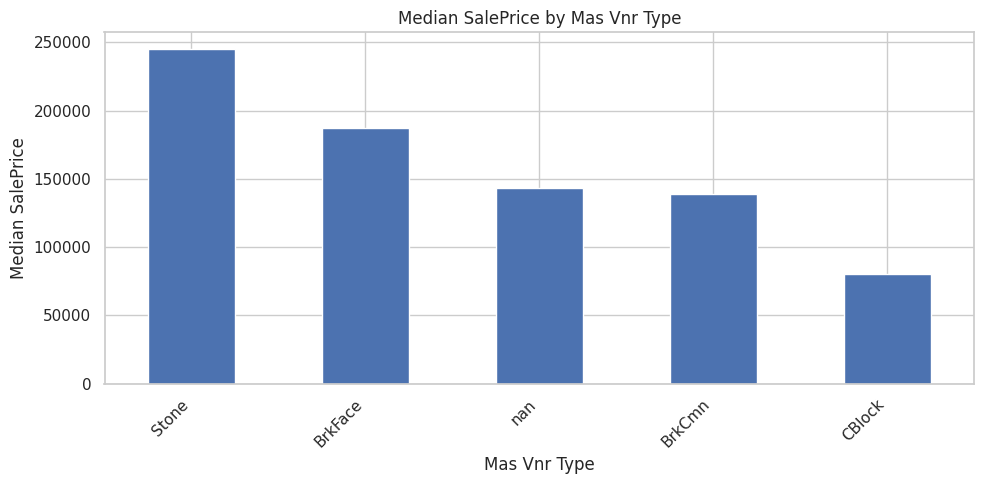

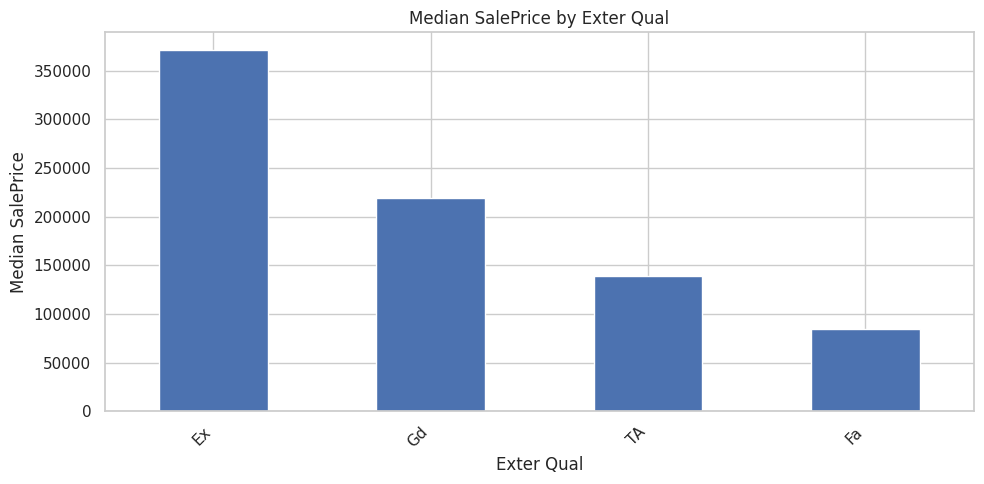

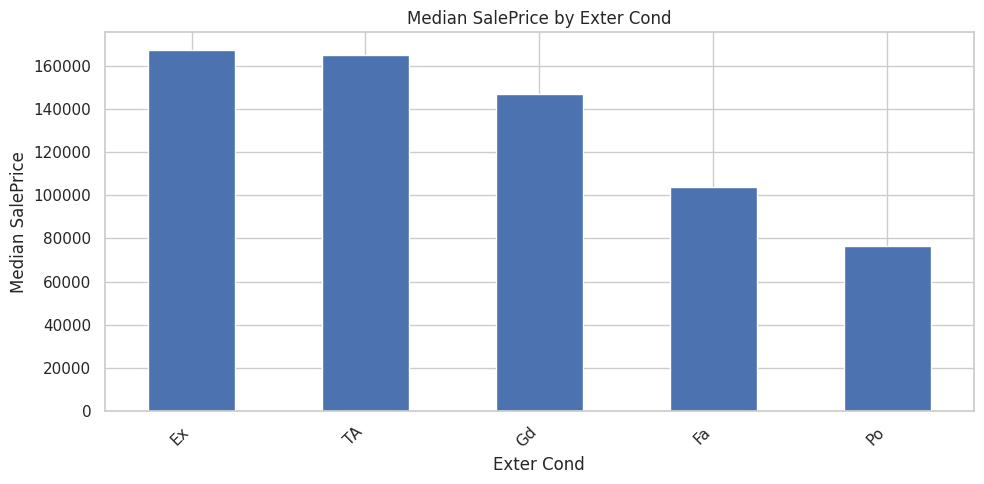

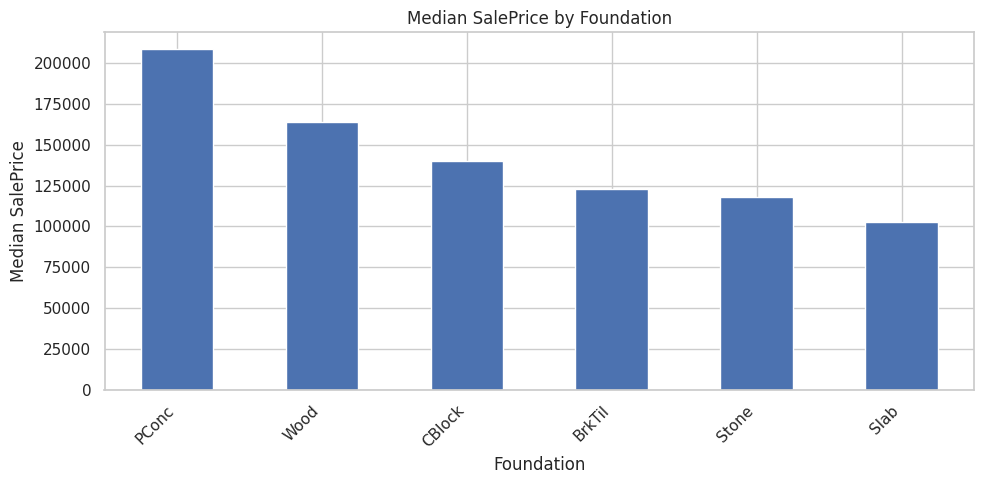

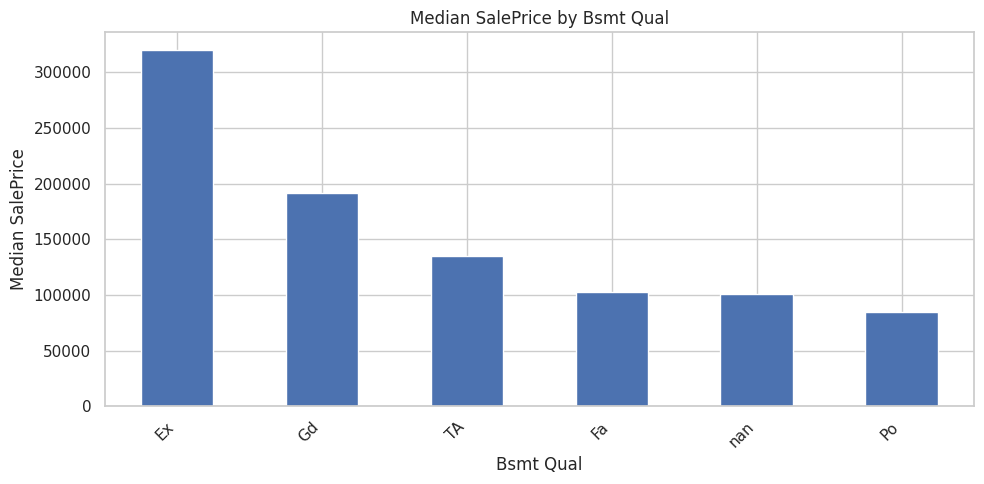

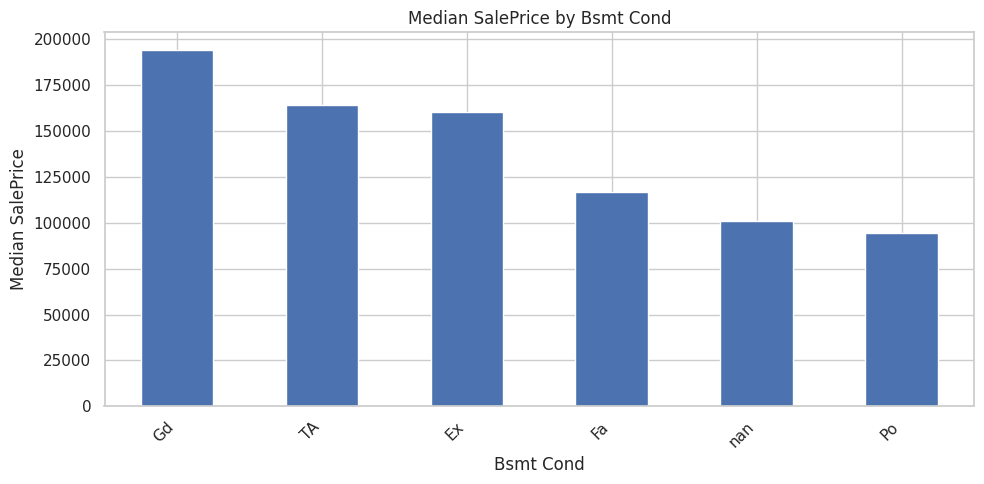

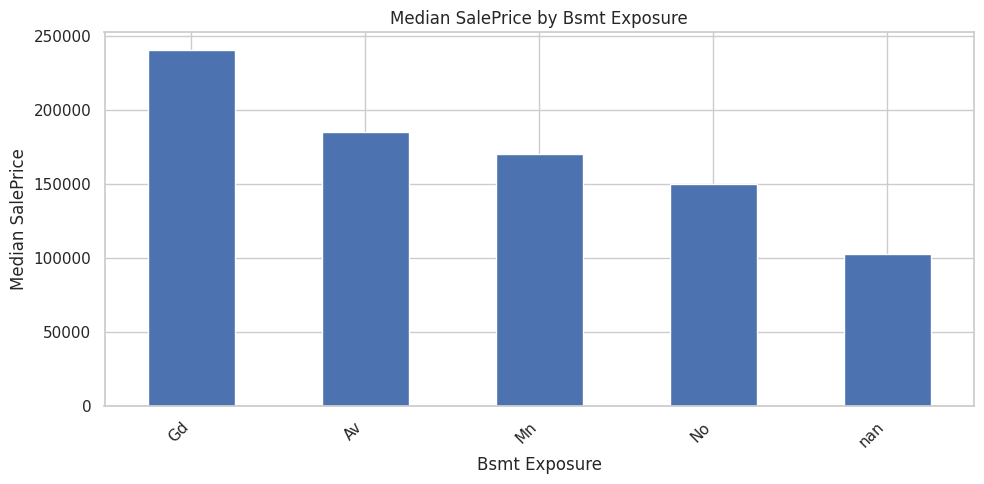

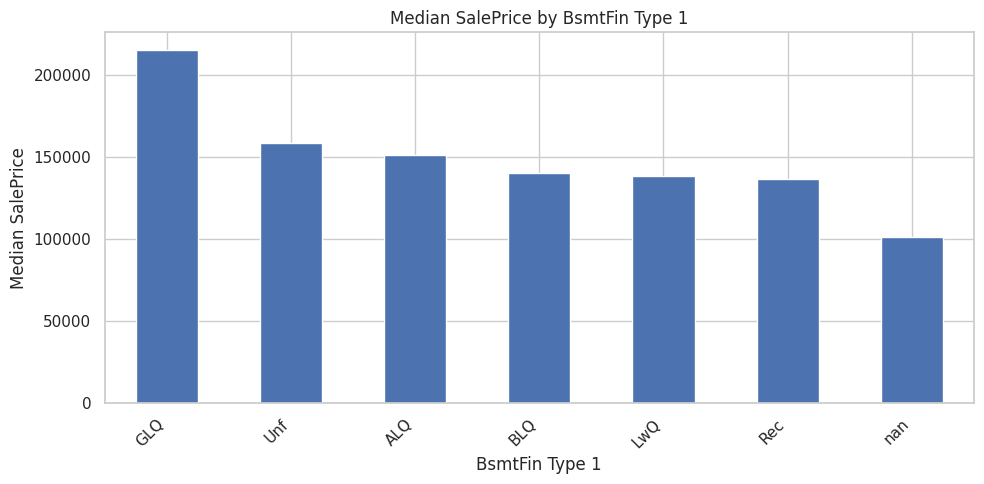

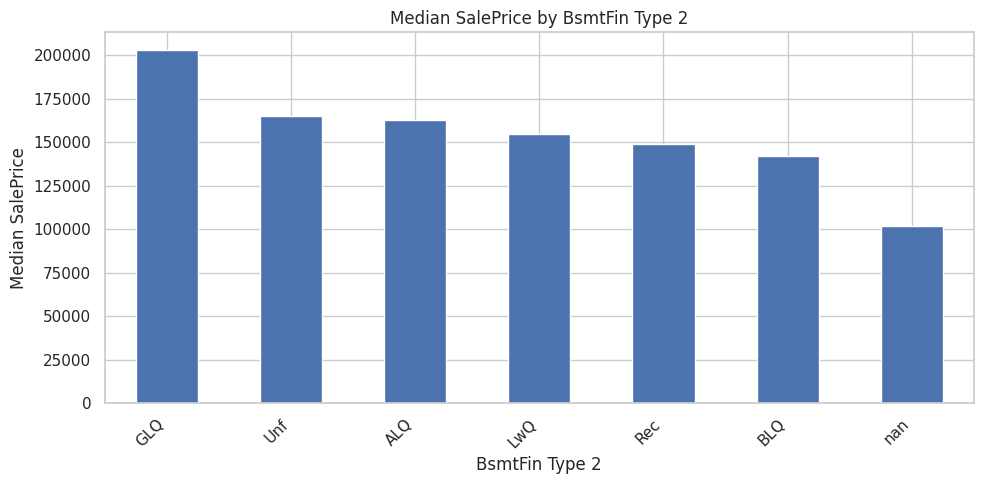

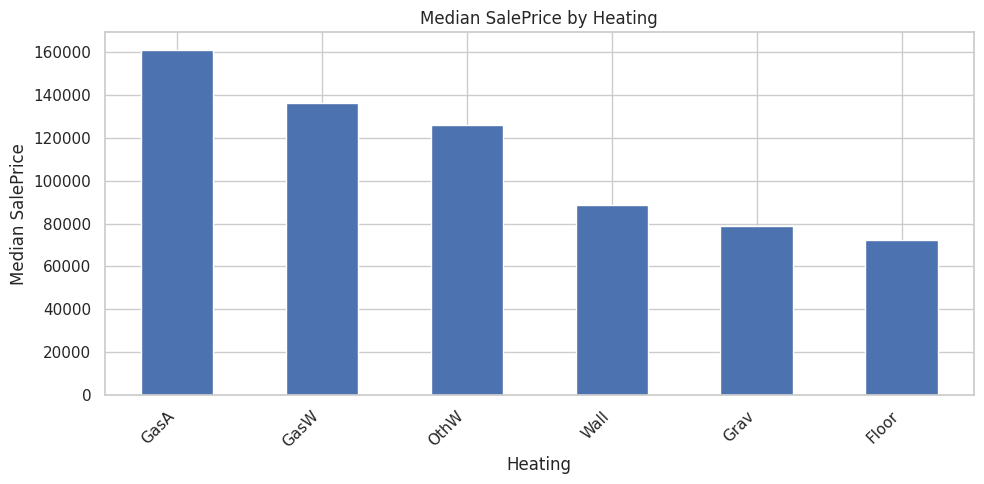

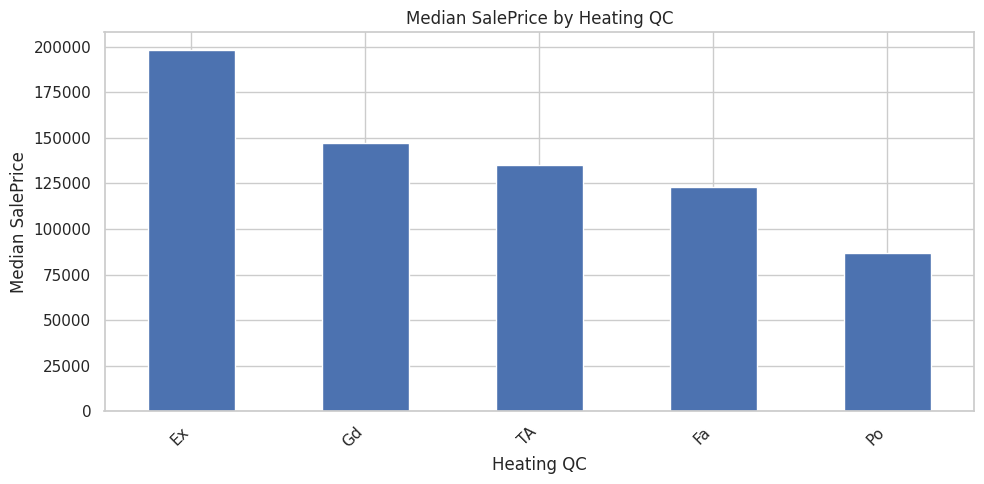

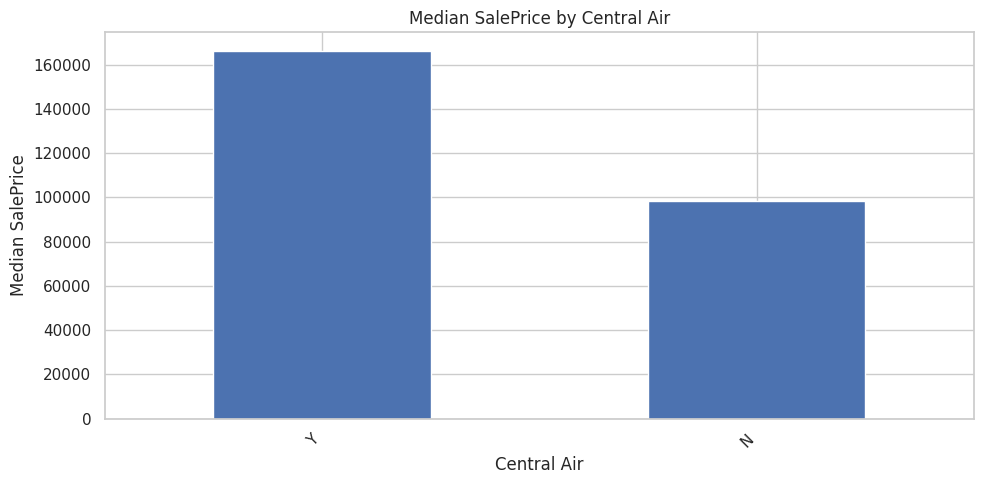

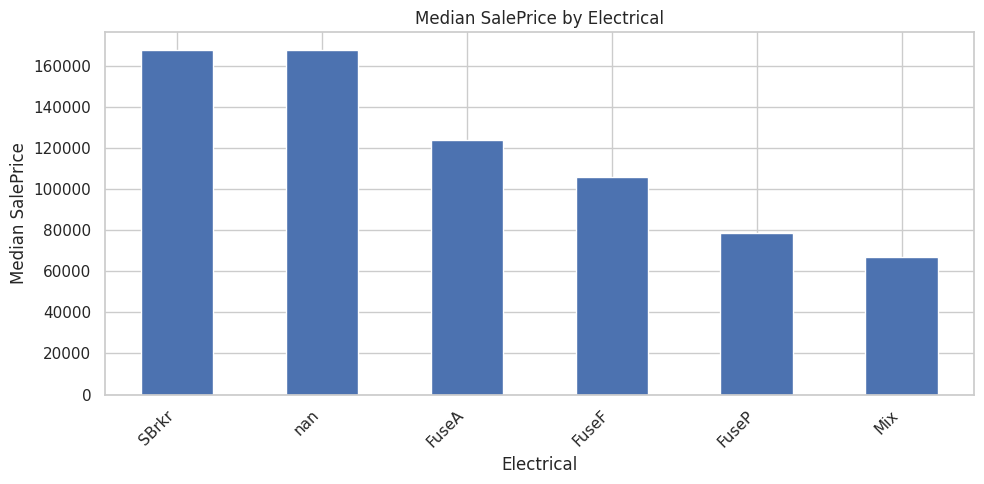

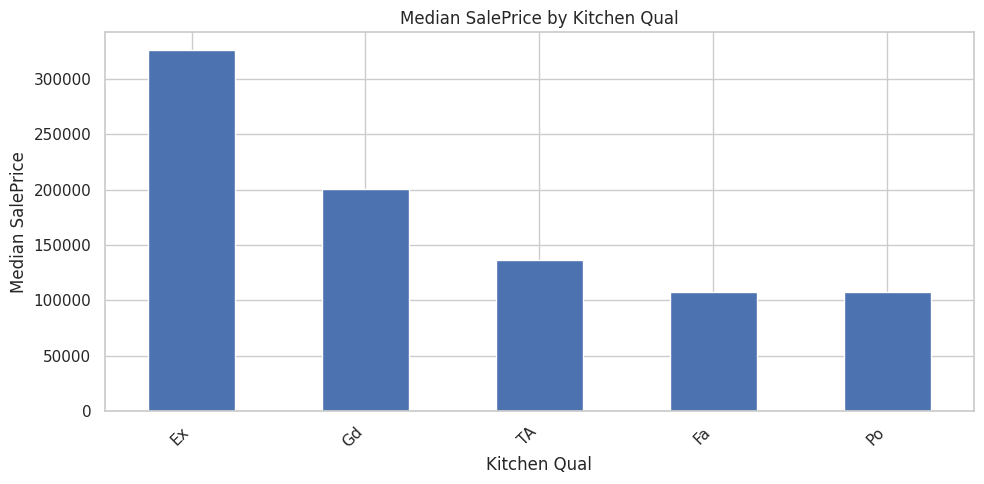

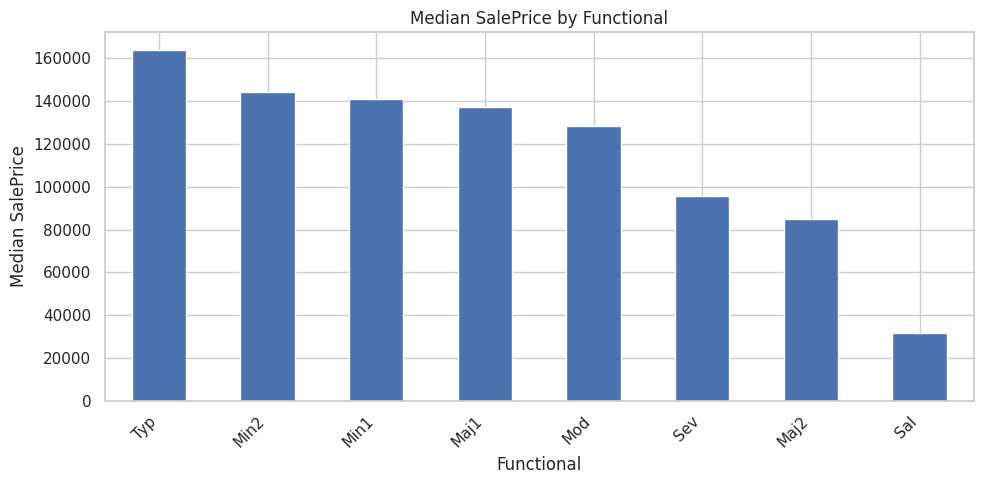

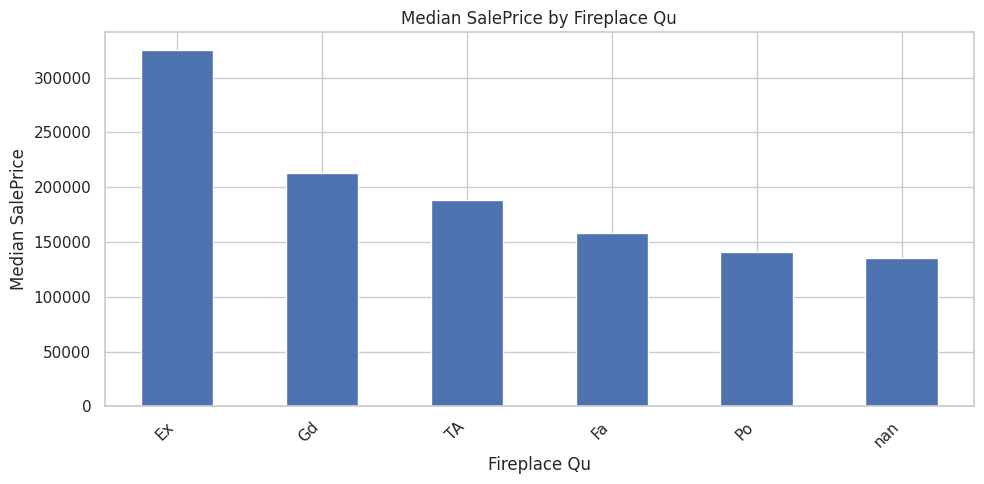

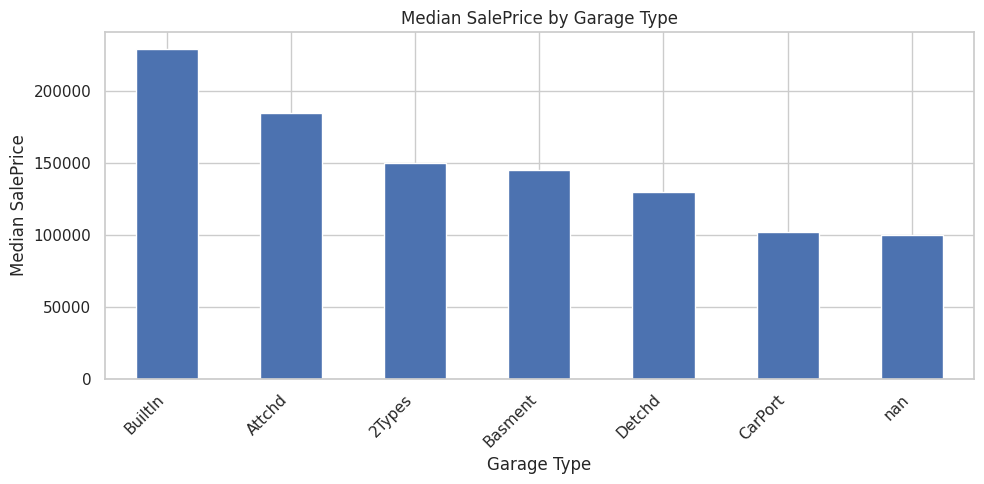

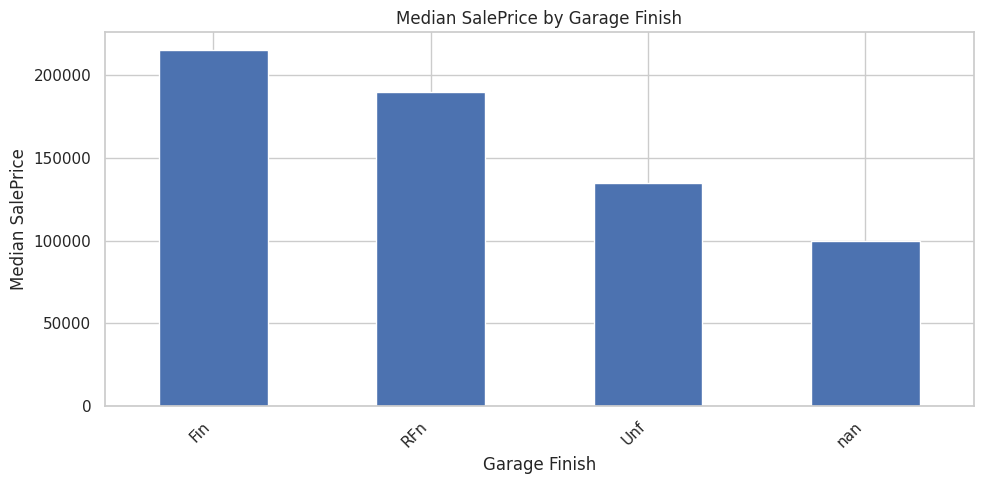

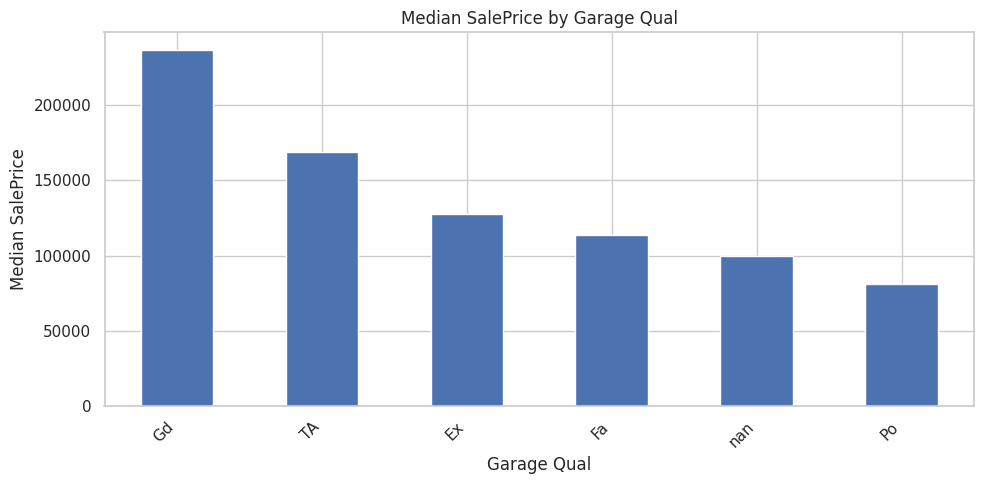

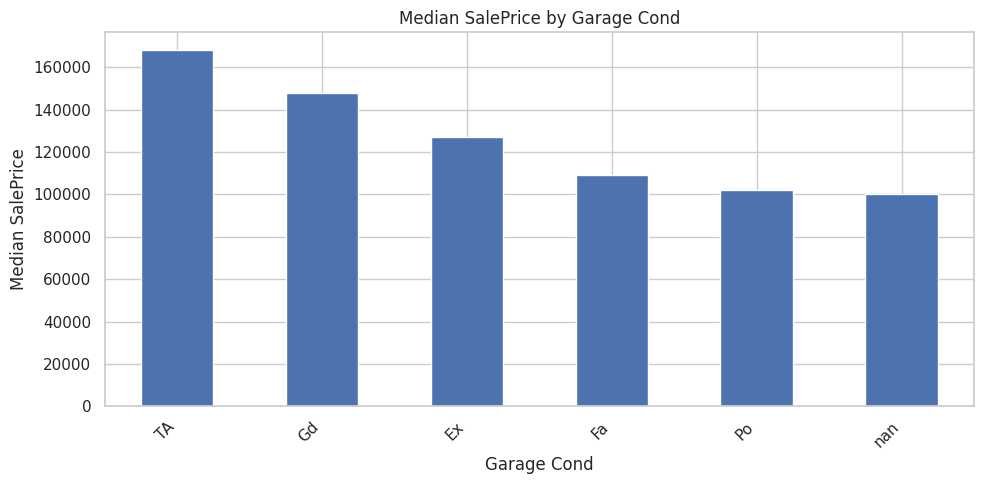

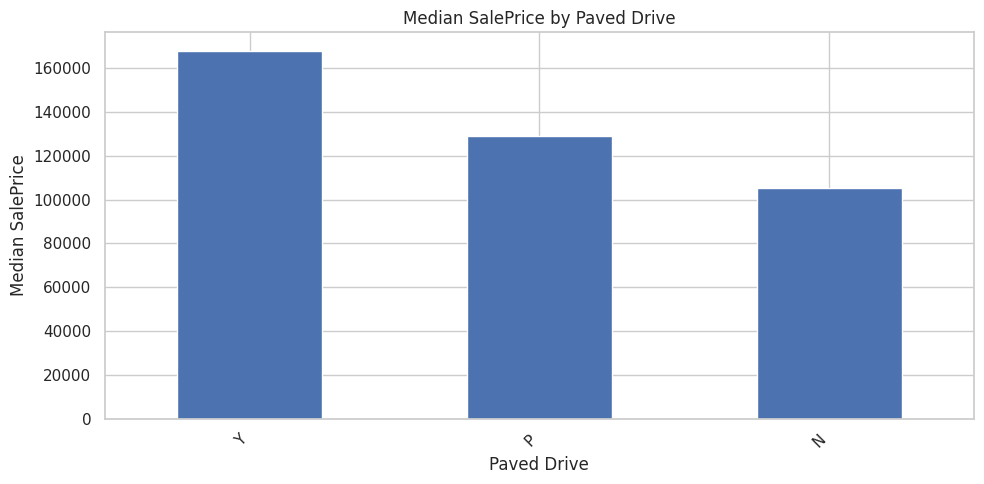

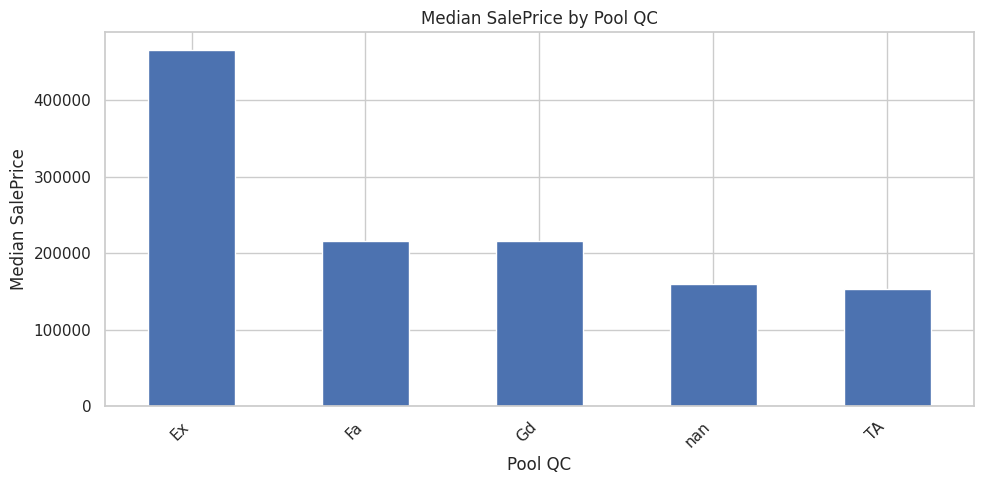

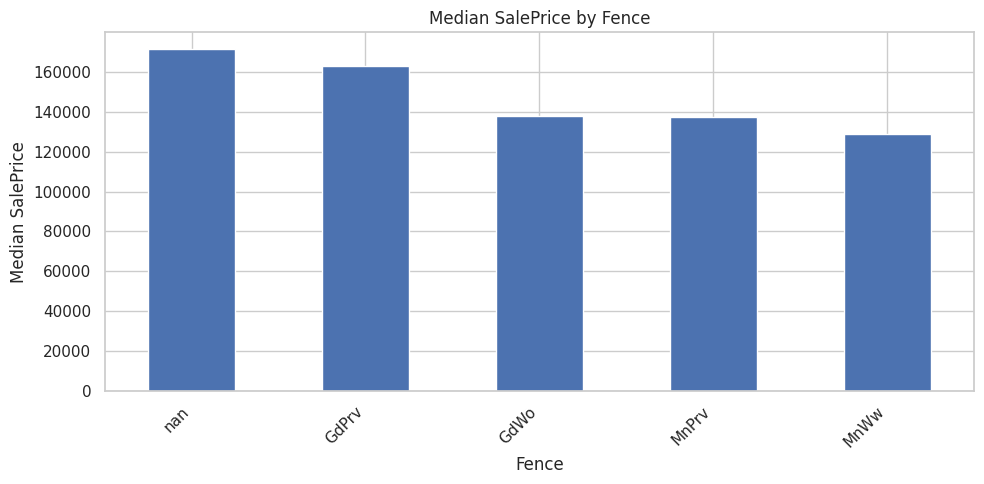

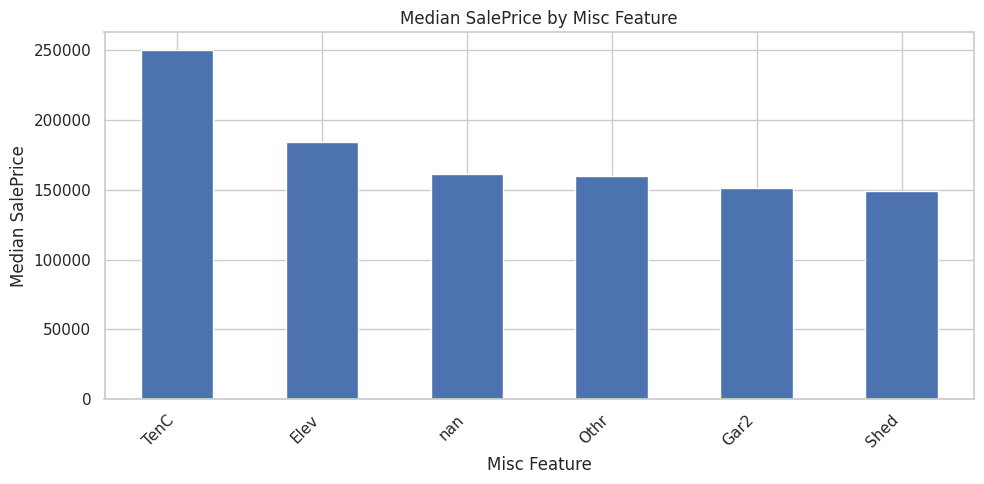

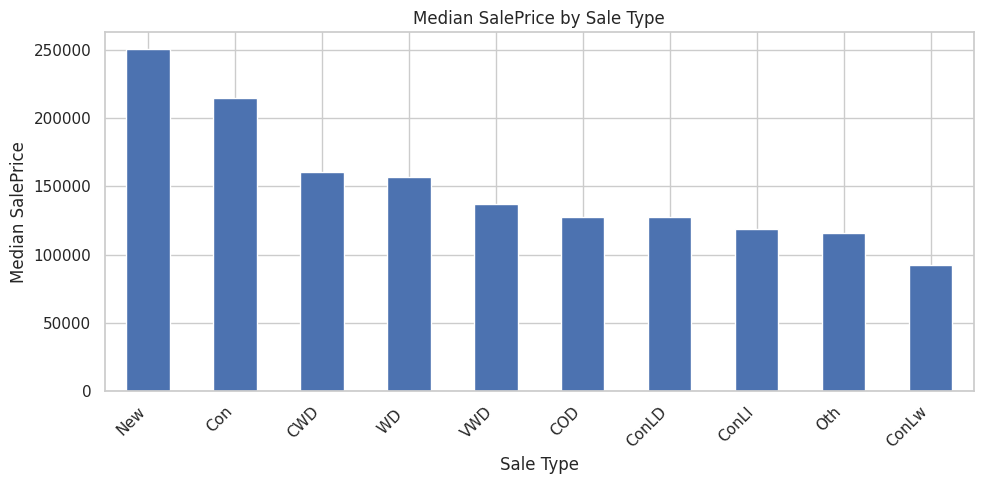

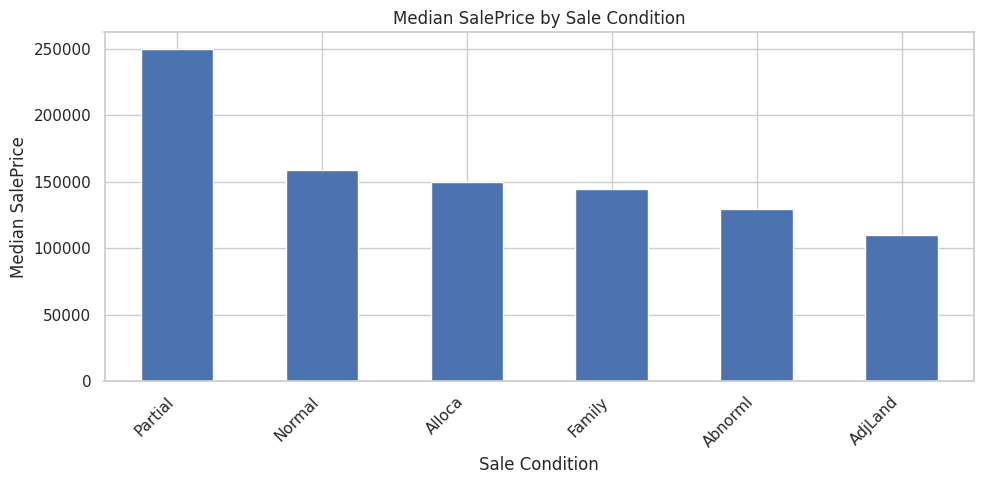

In [69]:
# Compare median SalePrice across categories.
# Limit plots to features with a manageable number of categories.
for feature in categorical_features:
    category_count = df[feature].nunique(dropna=True)

    if category_count <= 15:
        median_prices = (
            df.groupby(feature, dropna=False)[TARGET]
            .median()
            .sort_values(ascending=False)
        )

        plt.figure(figsize=(10, 5))
        median_prices.plot(kind="bar")
        plt.title(f"Median SalePrice by {feature}")
        plt.xlabel(feature)
        plt.ylabel("Median SalePrice")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

## 10. Outlier analysis

In [70]:
# Use box plots to inspect possible outliers in selected numerical features.
# The IQR rule identifies values outside Q1 - 1.5*IQR and Q3 + 1.5*IQR.
outlier_rows = []

for feature in numeric_predictors:
    values = df[feature].dropna()

    if values.empty:
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = ((values < lower_bound) | (values > upper_bound)).sum()

    outlier_rows.append({
        "Feature": feature,
        "Outlier_Count_IQR": int(outlier_count),
        "Outlier_Percent": round(outlier_count / len(values) * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_rows)
outlier_summary = outlier_summary.sort_values(
    "Outlier_Percent",
    ascending=False
)

display(outlier_summary)

,Feature,Outlier_Count_IQR,Outlier_Percent
31,Enclosed Porch,459,15.67
11,BsmtFin SF 2,351,11.98
33,Screen Porch,256,8.74
6,Overall Cond,252,8.60
3,Lot Frontage,187,7.66
2,MS SubClass,208,7.10
9,Mas Vnr Area,200,6.88
19,Bsmt Half Bath,175,5.98
30,Open Porch SF,159,5.43
23,Kitchen AbvGr,134,4.57


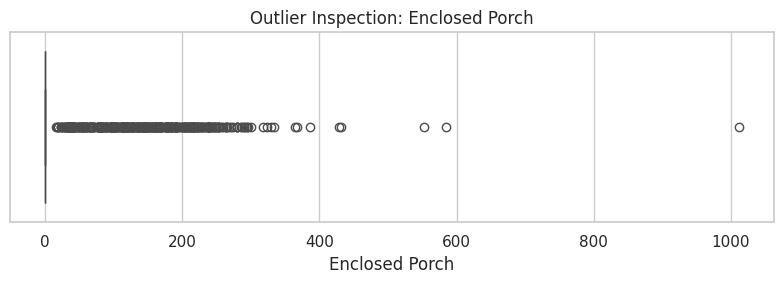

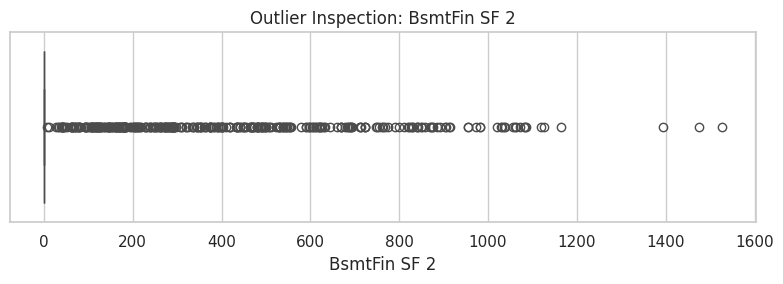

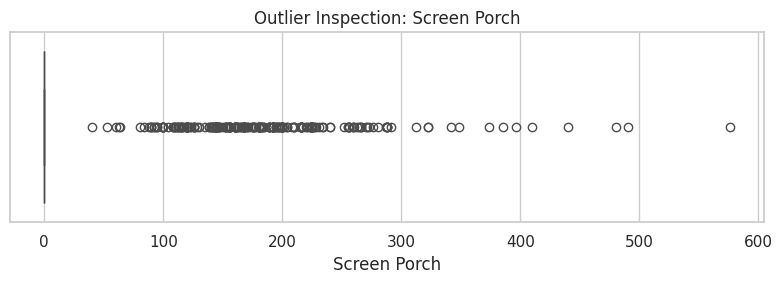

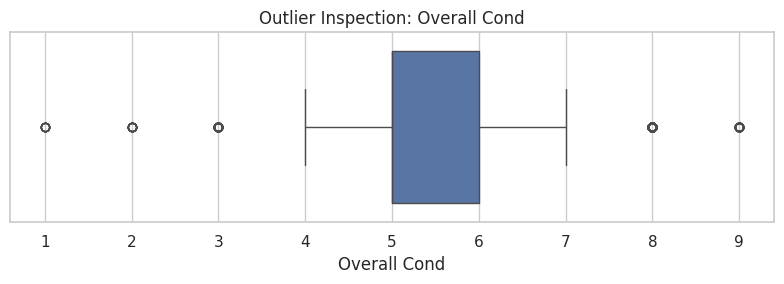

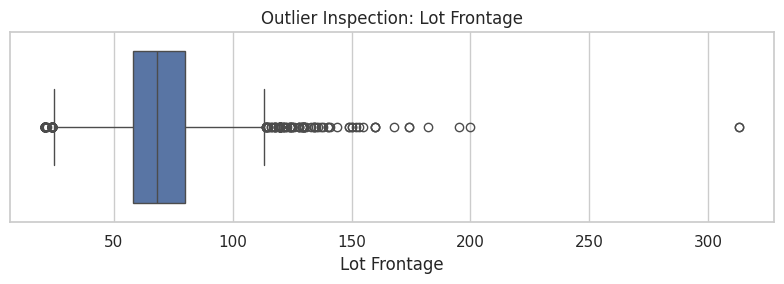

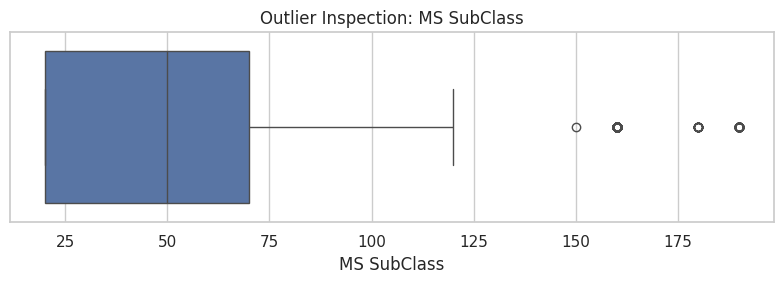

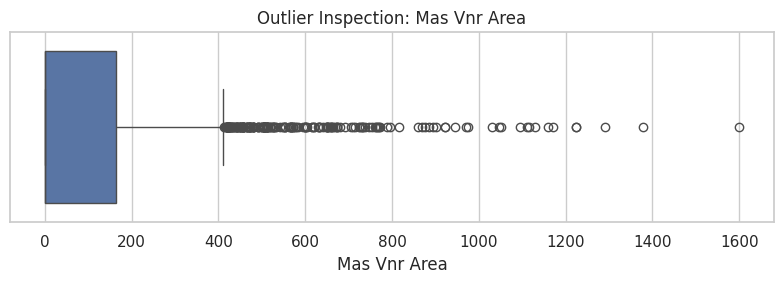

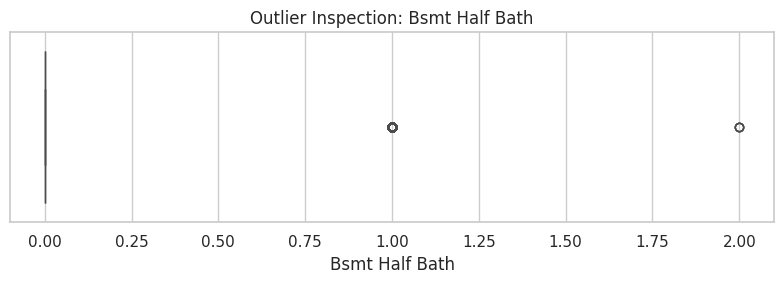

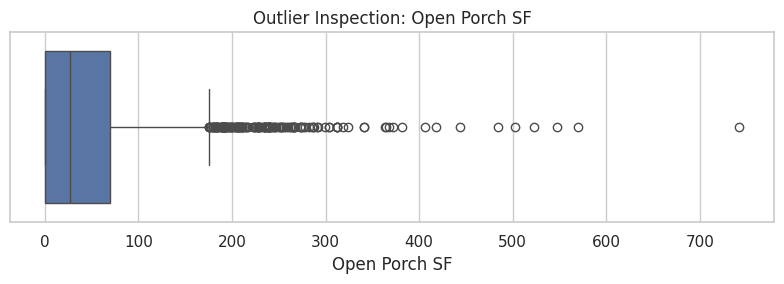

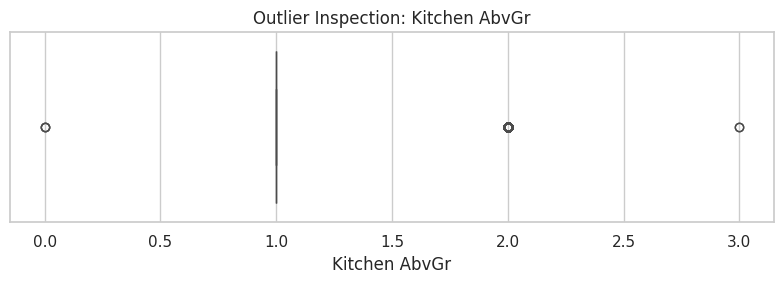

In [71]:
# Visualize selected numerical features with the highest IQR outlier percentages
features_to_plot = outlier_summary.head(10)["Feature"].tolist()

for feature in features_to_plot:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[feature])
    plt.title(f"Outlier Inspection: {feature}")
    plt.tight_layout()
    plt.show()

<details>
<summary><strong>Observation – Outliers</strong></summary>

The IQR method flags unusually low or high values; it does not prove that those records are incorrect. In housing data, a large house or expensive sale can be a genuine observation.

Investigate outliers using domain context and their relationship with `SalePrice`. Do not remove them automatically.
</details>

## 11. Correlation heatmap

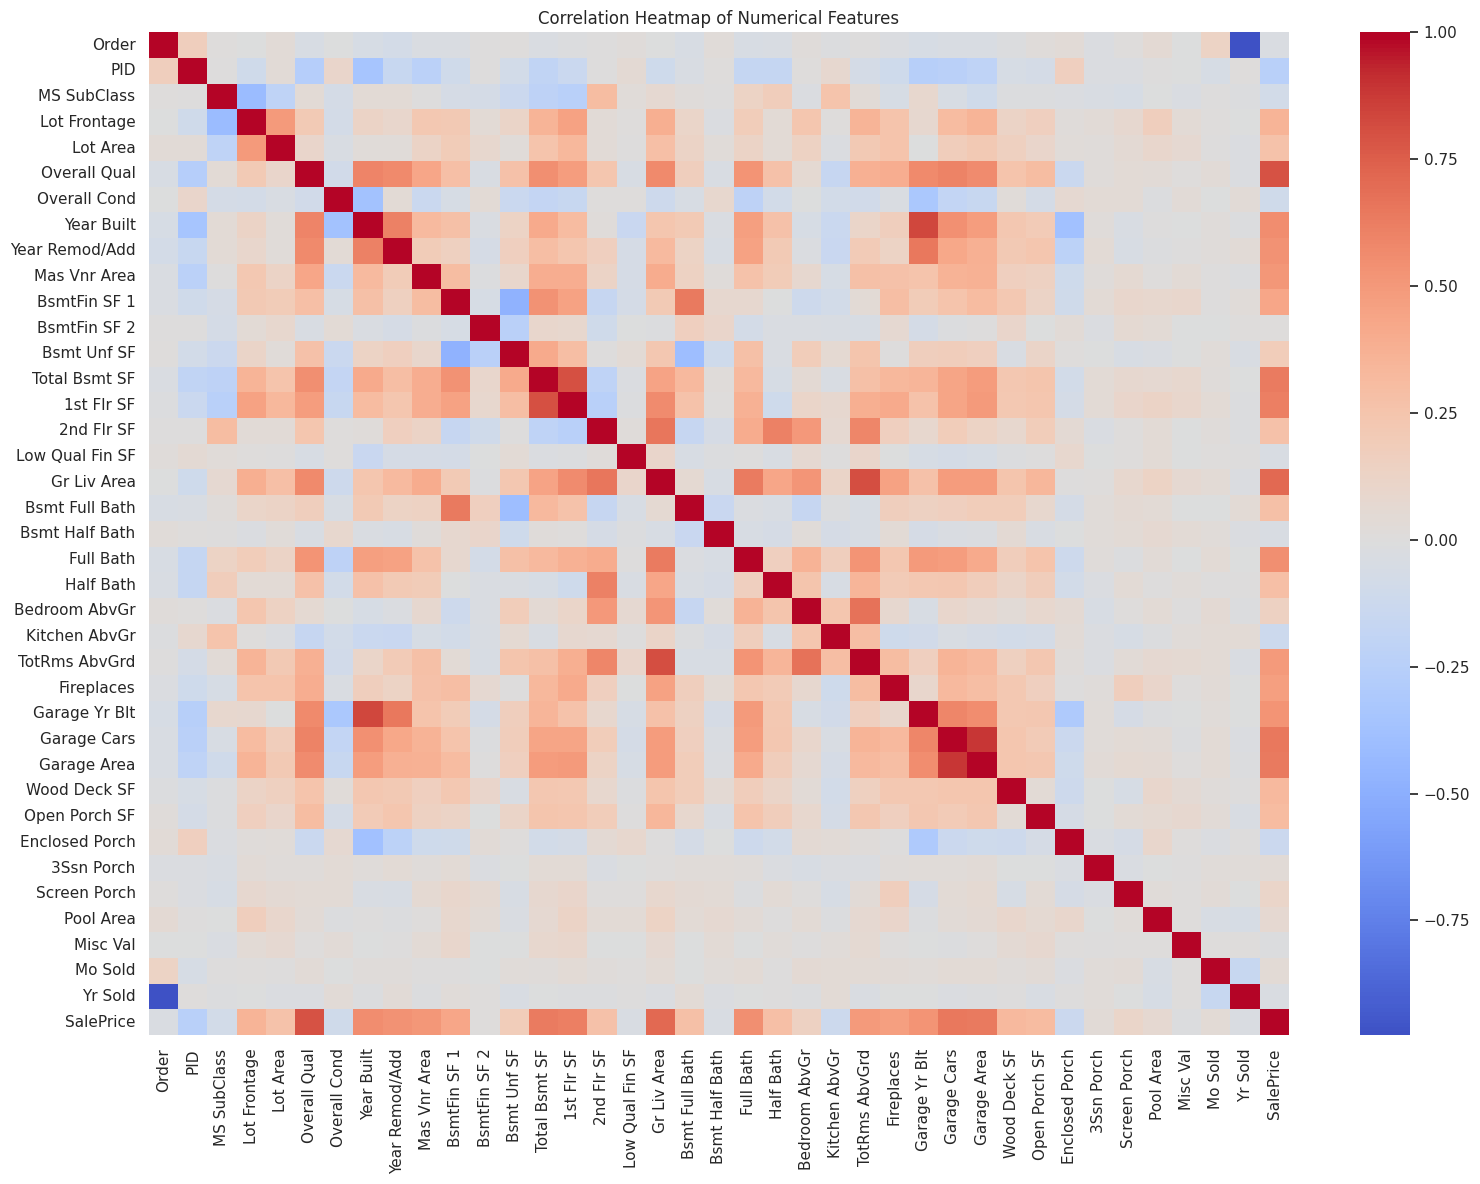

In [72]:
# Select numerical columns for correlation analysis
correlation_matrix = df[numerical_features].corr(numeric_only=True)

plt.figure(figsize=(16, 12))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False
)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

<details>
<summary><strong>Observation – Correlation between numerical features</strong></summary>

Look for groups of features that are strongly correlated with each other. Strong correlation between predictor features is called multicollinearity and may affect how linear regression coefficients are interpreted.

A correlation heatmap is a screening tool; investigate important feature pairs more closely before deciding whether to remove any feature.
</details>

## 12. Relationship between selected features and SalePrice

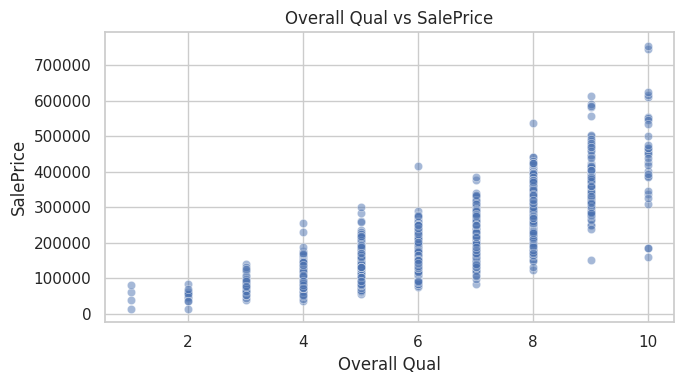

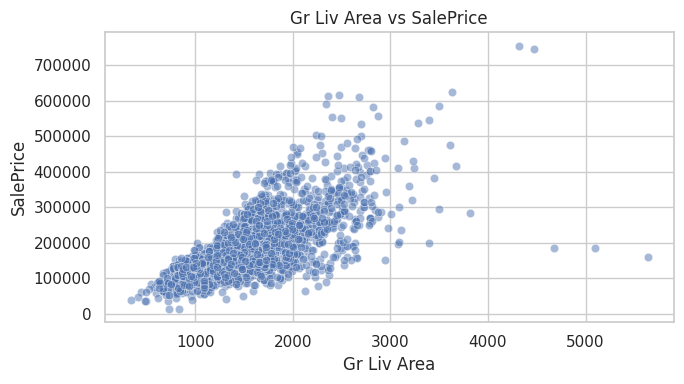

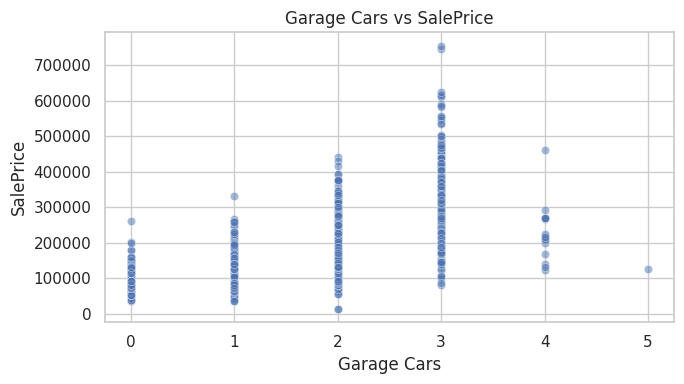

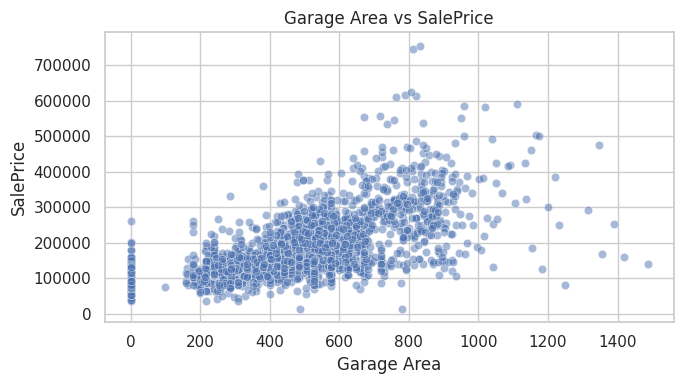

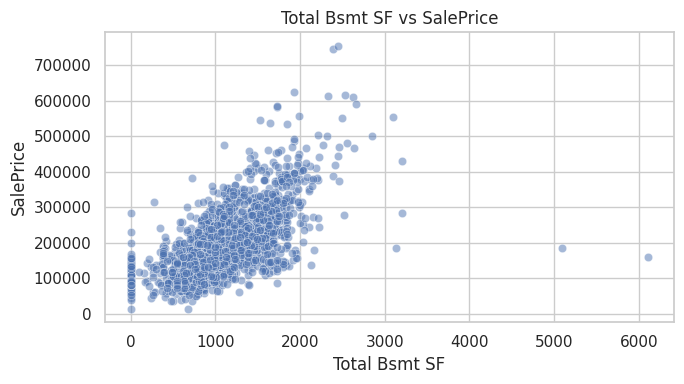

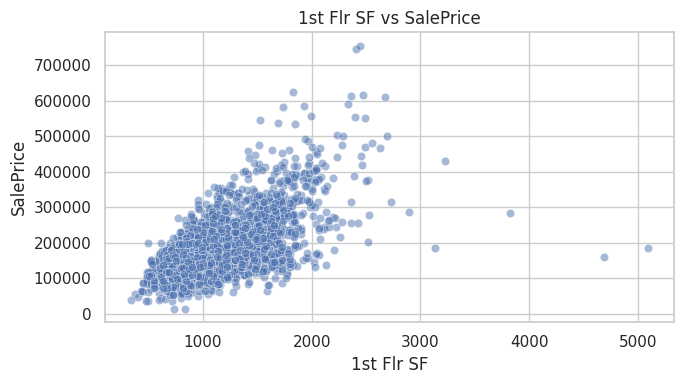

In [73]:
# Scatter plots for the numerical features most correlated with SalePrice
selected_features = (
    correlation_with_target.abs()
    .sort_values(ascending=False)
    .head(6)
    .index
    .tolist()
)

for feature in selected_features:
    plt.figure(figsize=(7, 4))
    sns.scatterplot(data=df, x=feature, y=TARGET, alpha=0.5)
    plt.title(f"{feature} vs {TARGET}")
    plt.xlabel(feature)
    plt.ylabel(TARGET)
    plt.tight_layout()
    plt.show()

<details>
<summary><strong>Observation – Feature relationships</strong></summary>

For each scatter plot, check whether the relationship looks approximately linear, non-linear, or weak. Also look for clusters and unusual records.

Linear regression works best when the model's relationship assumptions are reasonably appropriate. Feature transformations or additional features may be considered in later steps.
</details>

##  EDA summary

<details>
<summary><strong>1. Dataset overview</strong></summary>

- Number of rows:
- Number of columns:
- Target variable:
- Duplicate rows:
- Any data-type issues:
</details>

<details>
<summary><strong>2. Missing values</strong></summary>

- Features with the most missing values:
- Missing target values:
- Missing values that may mean “feature not present”:
- Proposed treatment to investigate in feature engineering:
</details>

<details>
<summary><strong>3. Target variable</strong></summary>

- Shape of SalePrice distribution:
- SalePrice skewness:
- Any unusually high or low sale prices:
- Is a target transformation worth testing?
</details>

<details>
<summary><strong>4. Important features</strong></summary>

- Numerical features with stronger correlation to SalePrice:
- Categorical features with visible price differences:
- Features requiring further investigation:
</details>

<details>
<summary><strong>5. Data-quality and preprocessing decisions</strong></summary>

- Duplicate handling:
- Missing-value handling:
- Categorical encoding:
- Numerical scaling or transformation:
- Outlier handling:
- Potential multicollinearity:
</details>

### Conclusion

EDA helps us understand the dataset before building a machine learning model. The next step is **feature engineering and preprocessing**. Decisions such as imputing missing values, encoding categories, scaling numerical features, and handling outliers should be fitted using the training data only to avoid data leakage.